# Pricing interventions and taxi travel in New York City, 2022–2025

**Research question.** How do two pricing interventions in New York City — the January 2025 congestion charge and the December 2022
metered fare increase — affect taxi travel speeds and demand, and what do the results imply for Indian cities?

| Section | Content |
|---|---|
| A | Data foundation: zone groups, cached panels from the cleaned trips, data checks |
| B | Descriptive statistics: tables, figures, correlations, maps, decomposition, weather |
| R | Regression analysis (OLS): weather and calendar effects, with diagnostics |
| 1 | Objective 1 — congestion pricing effect inside the charging zone (difference-in-differences + robustness) |
| 2 | Objective 2 — mechanism: peak vs overnight speed gains (triple difference + trends) |
| 3 | Objective 3 — fare sensitivity around the December 2022 fare revision |
| 4 | Objective 4 — machine-learning check: forecasts, model evaluation, clustering, matched controls |
| 5 | Results table and lessons for Indian cities (Objective 5) |
| 6 | Big-data engineering with Spark (optional): trip-level ML, vendor KPIs, engine timing, fare regression, scalability |

**Inputs** (in `My Drive/BigData Project`): the `out_20*/cleaned_trips` folders, `weather_daily.csv`, `cleaning_log_by_month.csv`,
the five `taxi_zones` shapefile files, and optionally the MTA *Congestion Relief Zone Vehicle Entries* CSV saved as `mta_crz_entries.csv`.

**Running it.** Run all cells in order. The first run scans the trip files once with DuckDB (≈5 minutes over Drive) and caches small
panels in `BigData Project/panels`; later runs reuse them. Tables are saved as CSVs in `panels/tables`.
Section 6 uses Spark and takes 30–60 minutes; if Colab runs short of memory, restart the session and run the setup cells,
Section A, then Section 6 on its own.

In [1]:
# ---------------------------------------------------------------- configuration
import os
# Mount Google Drive first (Colab only), before anything is written under /content/drive
try:
    import google.colab  # noqa: F401
    if not os.path.ismount("/content/drive"):
        from google.colab import drive
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR        = os.environ.get("TAXI_BASE", "/content/drive/MyDrive/BigData Project")
PARQUET_GLOB    = os.environ.get("TAXI_PARQUET_GLOB", f"{BASE_DIR}/out_20*/cleaned_trips/**/*.parquet")
CSV_DIR         = os.environ.get("TAXI_CSV_DIR", BASE_DIR)
ZONE_SHP        = os.environ.get("TAXI_ZONE_SHP", f"{BASE_DIR}/taxi_zones.shp")    # optional
MTA_ENTRIES_CSV = os.environ.get("TAXI_MTA_CSV", f"{BASE_DIR}/mta_crz_entries.csv")          # optional
CACHE_DIR       = os.environ.get("TAXI_CACHE", f"{BASE_DIR}/panels")
REBUILD_PANELS  = False      # True forces a fresh scan of the trip files

MIN_CELL_TRIPS  = int(os.environ.get("TAXI_MIN_CELL", 30))   # min trips per group-date-hour cell in Section 2
N_BOOT          = int(os.environ.get("TAXI_N_BOOT", 200))    # bootstrap replications
if CACHE_DIR.startswith("/content/drive") and not os.path.ismount("/content/drive"):
    raise RuntimeError("Google Drive is not mounted: refusing to create folders under /content/drive")
os.makedirs(CACHE_DIR, exist_ok=True)

Mounted at /content/drive


In [2]:
# ---------------------------------------------------------------- setup
import sys, subprocess, importlib
for pkg in ["statsmodels", "holidays", "duckdb", "pyarrow", "sklearn"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "scikit-learn" if pkg == "sklearn" else pkg], check=True)

import glob, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import holidays, duckdb
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
       "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948",
       "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb", "muted": "#c9c8c2"}
GROUP_COLOR = {"charging_zone": PAL["blue"], "control_manhattan": PAL["aqua"], "buffer": PAL["yellow"],
               "matched_control": PAL["orange"]}
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": PAL["surface"],
    "axes.facecolor": PAL["surface"], "axes.edgecolor": PAL["grid"], "axes.labelcolor": PAL["ink2"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": PAL["grid"],
    "grid.linewidth": 0.8, "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": PAL["ink"], "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 10})

TOLL_START = pd.Timestamp("2025-01-05")
FARE_CHANGE = pd.Timestamp("2022-12-19")
HOLIDAYS = pd.to_datetime(list(holidays.US(state="NY", years=range(2021, 2027)).keys()))
RESULTS = []    # (objective, estimate, value, ci_low, ci_high, p, note)

def record(obj, name, val, lo=np.nan, hi=np.nan, p=np.nan, note=""):
    RESULTS.append(dict(objective=obj, estimate=name, value=val, ci_low=lo, ci_high=hi, p=p, note=note))

def pct(b):            # log-point coefficient -> percent
    return (np.exp(b) - 1) * 100

def find_csv(name):
    for d in [CSV_DIR, BASE_DIR, ".", "/content", "/mnt/user-data/uploads"]:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None
print("ready")

ready


## A. Data foundation
### A1. Zone groups
The charging zone is Manhattan south of and including 60th Street. Each taxi zone is assigned by geometry: the share of its area south of
60th Street.

| Group | Rule | Zones |
|---|---|---|
| `charging_zone` | ≥ 90% of area south of 60th St | 38 |
| `buffer` | 1–90% south (the 59th–60th St strip, Central Park) — excluded from both groups to avoid spillover contamination | 6 |
| `control_manhattan` | Manhattan, entirely north of the buffer | 20 |
| `excluded_island` | Governors/Ellis/Liberty, Roosevelt and Randalls Islands | 5 |
| `outside_manhattan` | everything else | 194 |

Zone-level assignment ignores the toll-exempt FDR Drive and West Side Highway; note this in the methods.

Zone groups computed from shapefile; matches embedded lists: True


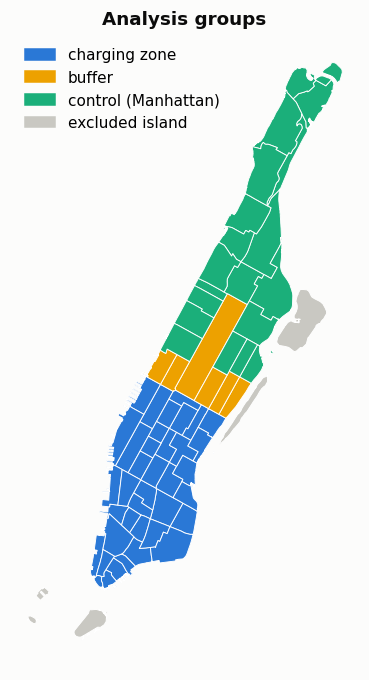

grp
outside_manhattan    194
charging_zone         38
control_manhattan     20
buffer                 6
excluded_island        5


In [3]:
CHARGING = [4, 12, 13, 45, 48, 50, 68, 79, 87, 88, 90, 100, 107, 113, 114, 125, 137, 144, 148, 158, 161, 162, 163,
            164, 170, 186, 209, 211, 224, 229, 230, 231, 232, 233, 234, 246, 249, 261]
BUFFER = [43, 140, 141, 142, 143, 237]
CONTROL = [24, 41, 42, 74, 75, 116, 120, 127, 128, 151, 152, 153, 166, 236, 238, 239, 243, 244, 262, 263]
ISLANDS = [103, 104, 105, 194, 202]

def zone_groups_from_shapefile(path):
    import geopandas as gpd
    from shapely.geometry import Polygon, Point
    z = gpd.read_file(path).to_crs(2263)
    # 59th St reference points: Columbus Circle and 59th St & 1st Ave; shifted ~80 m north = 60th St
    pts = gpd.GeoSeries([Point(-73.98182, 40.76803), Point(-73.96170, 40.76030)], crs=4326).to_crs(2263)
    p1, p2 = np.array(pts[0].coords[0]), np.array(pts[1].coords[0])
    d = (p2 - p1) / np.linalg.norm(p2 - p1); n = np.array([-d[1], d[0]]); n = n if n[1] > 0 else -n
    a, b = p1 + n * 260 - d * 30000, p2 + n * 260 + d * 30000
    south = Polygon([a, b, b - n * 200000, a - n * 200000])
    man = z.borough == "Manhattan"
    z["frac_south"] = 0.0
    z.loc[man, "frac_south"] = z[man].geometry.intersection(south).area / z[man].geometry.area
    def grp(r):
        if r.borough != "Manhattan": return "outside_manhattan"
        if r.LocationID in ISLANDS: return "excluded_island"
        if r.frac_south >= 0.9: return "charging_zone"
        if r.frac_south > 0.01: return "buffer"
        return "control_manhattan"
    z["grp"] = z.apply(grp, axis=1)
    return z

if os.path.exists(ZONE_SHP):
    zgeo = zone_groups_from_shapefile(ZONE_SHP)
    zg = zgeo[["LocationID", "zone", "borough", "grp"]].copy()
    same = (set(zg.loc[zg.grp == "charging_zone", "LocationID"]) == set(CHARGING)
            and set(zg.loc[zg.grp == "buffer", "LocationID"]) == set(BUFFER))
    print("Zone groups computed from shapefile; matches embedded lists:", same)
    m = zgeo[zgeo.borough == "Manhattan"]
    fig, ax = plt.subplots(figsize=(5, 7.5))
    for g, c in [("charging_zone", PAL["blue"]), ("buffer", PAL["yellow"]),
                 ("control_manhattan", PAL["aqua"]), ("excluded_island", PAL["muted"])]:
        m[m.grp == g].plot(ax=ax, color=c, edgecolor="white", linewidth=0.6)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=c, label=l) for l, c in [("charging zone", PAL["blue"]), ("buffer", PAL["yellow"]),
              ("control (Manhattan)", PAL["aqua"]), ("excluded island", PAL["muted"])]], loc="upper left")
    ax.set_axis_off(); ax.set_title("Analysis groups"); plt.show()
else:
    ids = range(1, 264)
    def g(i):
        return ("charging_zone" if i in CHARGING else "buffer" if i in BUFFER else
                "control_manhattan" if i in CONTROL else "excluded_island" if i in ISLANDS else "outside_manhattan")
    zg = pd.DataFrame({"LocationID": list(ids), "grp": [g(i) for i in ids]})
    print("Shapefile not found: using embedded zone lists")
print(zg.grp.value_counts().to_string())

### A2. Build the analysis panels (one scan of the trip files)
| Panel | Grain | Used in |
|---|---|---|
| `panel_hourly` | date × hour × pickup group × dropoff group | 1, 2 |
| `panel_zone_day` | date × pickup zone | 4 |
| `panel_zone_profile` | pickup zone × hour × weekend, 2024 | 4 (clustering) |
| `panel_fare_segments` | date × fare segment, Sep 2022 – Mar 2024 | 3 |

Speed = Σ distance ÷ Σ duration (trip-weighted, not an average of per-trip speeds). Zone IDs 264/265 fall into group `other`.

In [4]:
import json, re
import pyarrow.parquet as pq

def check_trip_files():
    # Validate every parquet file, count rows per month, and compare with the cleaning log.
    # Broken files are skipped; months whose rows don't match the log are dropped entirely,
    # because a partly missing month would look like a fall in demand.
    files = sorted(glob.glob(PARQUET_GLOB, recursive=True))
    if not files:
        raise FileNotFoundError(f"No parquet files match {PARQUET_GLOB}")
    good, bad, rows = [], [], {}
    for f in files:
        try:
            n = pq.ParquetFile(f).metadata.num_rows
        except Exception as e:
            bad.append({"file": f, "bytes": os.path.getsize(f), "error": type(e).__name__}); continue
        y = re.search(r"year=(\d{4})", f) or re.search(r"out_(\d{4})", f)
        m = re.search(r"month=(\d{1,2})", f)
        key = f"{int(y.group(1))}-{int(m.group(1)):02d}"
        rows[key] = rows.get(key, 0) + n
        good.append((f, key))
    expected, incomplete = None, []
    p = find_csv("cleaning_log_by_month.csv")
    if p:
        cl = pd.read_csv(p)
        cl["key"] = [f"{y}-{m:02d}" for y, m in zip(cl.file_year, cl.file_month)]
        cl["in_files"] = cl.key.map(rows).fillna(0).astype(int)
        cl["missing"] = cl.rows_kept - cl.in_files
        incomplete = cl.loc[cl.missing != 0, "key"].tolist()
        expected = int(cl.loc[cl.missing == 0, "rows_kept"].sum())
        if incomplete:
            print("Incomplete months (dropped entirely):")
            display(cl.loc[cl.missing != 0, ["key", "rows_kept", "in_files", "missing"]])
    elif bad:
        print("Warning: broken files found and no cleaning log to check completeness against.")
    keep = [f for f, k in good if k not in incomplete]
    info = {"n_files": len(files), "n_used": len(keep), "bad_files": bad,
            "incomplete_months": incomplete, "expected_rows": expected}
    print(f"{len(files)} files found, {len(bad)} unreadable, {len(keep)} used")
    for b in bad:
        print("  unreadable:", b["file"].split("/out_")[-1], f"({b['bytes']} bytes)")
    return keep, info

def build_panels(names):
    keep, info = check_trip_files()
    with open(f"{CACHE_DIR}/data_check.json", "w") as fh:
        json.dump(info, fh, indent=1)
    file_list = "[" + ", ".join("'" + f.replace("'", "''") + "'" for f in keep) + "]"
    con = duckdb.connect()
    con.execute(f"SET temp_directory='{CACHE_DIR}/duckdb_tmp'")
    con.execute(f"CREATE VIEW trips AS SELECT * FROM read_parquet({file_list}, hive_partitioning=true, union_by_name=true)")
    con.register("zg_df", zg[["LocationID", "grp"]])
    con.execute("CREATE TABLE zg AS SELECT CAST(LocationID AS INTEGER) AS LocationID, grp FROM zg_df")
    timings = {}
    def run(name, sql):
        t0 = time.time()
        con.execute(f"COPY ({sql}) TO '{CACHE_DIR}/{name}.parquet' (FORMAT parquet)")
        timings[name] = time.time() - t0
        print(f"  {name}: {timings[name]:.1f}s")
    if "panel_hourly" in names: run("panel_hourly", '''
        SELECT CAST(t.pickup_date AS DATE) AS pickup_date, CAST(t.pickup_hour AS INTEGER) AS hour,
               CAST(t.is_weekend AS BOOLEAN) AS weekend,
               coalesce(p.grp, 'other') AS pu_grp, coalesce(d.grp, 'other') AS do_grp,
               count(*) AS trips, sum(t.trip_distance) AS dist, sum(t.trip_duration_min) AS dur,
               sum(CASE WHEN t.has_cbd_fee THEN 1 ELSE 0 END) AS n_cbd_fee
        FROM trips t
        LEFT JOIN zg p ON CAST(t.pulocationid AS INTEGER) = p.LocationID
        LEFT JOIN zg d ON CAST(t.dolocationid AS INTEGER) = d.LocationID
        GROUP BY ALL''')
    if "panel_zone_day" in names: run("panel_zone_day", '''
        SELECT CAST(pickup_date AS DATE) AS pickup_date, CAST(pulocationid AS INTEGER) AS zone_id,
               count(*) AS trips, sum(trip_distance) AS dist, sum(trip_duration_min) AS dur,
               sum(CASE WHEN dolocationid IN (1, 132, 138) THEN 1 ELSE 0 END) AS n_airport
        FROM trips GROUP BY ALL''')
    if "panel_zone_profile" in names: run("panel_zone_profile", '''
        SELECT CAST(pulocationid AS INTEGER) AS zone_id, CAST(pickup_hour AS INTEGER) AS hour,
               CAST(is_weekend AS BOOLEAN) AS weekend, count(*) AS trips
        FROM trips WHERE CAST(pickup_date AS DATE) BETWEEN DATE '2024-01-01' AND DATE '2024-12-31'
        GROUP BY ALL''')
    if "panel_fare_segments" in names: run("panel_fare_segments", '''
        SELECT CAST(pickup_date AS DATE) AS pickup_date,
               CASE WHEN CAST(ratecodeid AS INTEGER) = 2 THEN 'JFK flat'
                    WHEN CAST(ratecodeid AS INTEGER) = 1 THEN
                      (CASE WHEN trip_distance < 1 THEN 'd0-1' WHEN trip_distance < 2 THEN 'd1-2'
                            WHEN trip_distance < 3 THEN 'd2-3' WHEN trip_distance < 5 THEN 'd3-5'
                            WHEN trip_distance < 10 THEN 'd5-10' ELSE 'd10+' END) || ' | ' ||
                      (CASE WHEN NOT CAST(is_weekend AS BOOLEAN) AND pickup_hour BETWEEN 16 AND 19 THEN 'rush'
                            WHEN pickup_hour >= 20 OR pickup_hour < 6 THEN 'night' ELSE 'day' END)
               END AS segment,
               count(*) AS trips, avg(fare_amount) AS avg_fare, avg(trip_distance) AS avg_dist,
               avg(trip_duration_min) AS avg_dur
        FROM trips
        WHERE NOT is_zero_fare AND CAST(ratecodeid AS INTEGER) IN (1, 2)
          AND CAST(pickup_date AS DATE) BETWEEN DATE '2022-09-01' AND DATE '2024-03-31'
        GROUP BY ALL''')
    if "panel_desc" in names: run("panel_desc", '''
        SELECT CAST(date_trunc('month', CAST(t.pickup_date AS DATE)) AS DATE) AS month,
               coalesce(p.grp, 'other') AS pu_grp,
               CASE WHEN t.trip_distance < 1 THEN '0-1' WHEN t.trip_distance < 2 THEN '1-2'
                    WHEN t.trip_distance < 3 THEN '2-3' WHEN t.trip_distance < 5 THEN '3-5'
                    WHEN t.trip_distance < 10 THEN '5-10' WHEN t.trip_distance < 20 THEN '10-20' ELSE '20+' END AS dist_bin,
               count(*) AS trips, sum(t.trip_distance) AS dist, sum(t.trip_duration_min) AS dur,
               sum(CASE WHEN NOT t.is_zero_fare THEN t.fare_amount ELSE 0 END) AS fare_sum,
               sum(CASE WHEN NOT t.is_zero_fare THEN 1 ELSE 0 END) AS n_fare,
               sum(t.total_amount) AS total_sum,
               sum(CASE WHEN CAST(t.payment_type AS INTEGER) = 1 THEN 1 ELSE 0 END) AS n_card,
               sum(CASE WHEN CAST(t.payment_type AS INTEGER) = 1 THEN t.tip_amount ELSE 0 END) AS tip_card,
               sum(CASE WHEN CAST(t.payment_type AS INTEGER) = 1 THEN t.fare_amount ELSE 0 END) AS fare_card,
               sum(CASE WHEN t.has_cbd_fee THEN 1 ELSE 0 END) AS n_cbd_fee,
               sum(coalesce(t.cbd_congestion_fee, 0)) AS cbd_fee_sum,
               sum(CASE WHEN t.pulocationid IN (1, 132, 138) OR t.dolocationid IN (1, 132, 138) THEN 1 ELSE 0 END) AS n_airport,
               sum(t.passenger_count) AS pax_sum, count(t.passenger_count) AS pax_n
        FROM trips t LEFT JOIN zg p ON CAST(t.pulocationid AS INTEGER) = p.LocationID
        GROUP BY ALL''')
    old = pd.read_csv(f"{CACHE_DIR}/build_timings.csv", index_col=0)["seconds"] if os.path.exists(f"{CACHE_DIR}/build_timings.csv") else pd.Series(dtype=float)
    pd.concat([old.drop(list(timings), errors="ignore"), pd.Series(timings)]).rename("seconds").to_csv(f"{CACHE_DIR}/build_timings.csv")
    con.close()

needed = ["panel_hourly", "panel_zone_day", "panel_zone_profile", "panel_fare_segments", "panel_desc"]
to_build = needed if REBUILD_PANELS else [n for n in needed if not os.path.exists(f"{CACHE_DIR}/{n}.parquet")]
if to_build:
    print("Building:", to_build)
    t0 = time.time(); build_panels(to_build); print(f"Panels built in {time.time() - t0:.0f}s")
else:
    print("Using cached panels in", CACHE_DIR)

ph   = pd.read_parquet(f"{CACHE_DIR}/panel_hourly.parquet")
pzd  = pd.read_parquet(f"{CACHE_DIR}/panel_zone_day.parquet")
pzp  = pd.read_parquet(f"{CACHE_DIR}/panel_zone_profile.parquet")
pfs  = pd.read_parquet(f"{CACHE_DIR}/panel_fare_segments.parquet")
pdesc = pd.read_parquet(f"{CACHE_DIR}/panel_desc.parquet"); pdesc["month"] = pd.to_datetime(pdesc.month)
for df in (ph, pzd, pfs):
    df["pickup_date"] = pd.to_datetime(df.pickup_date)
DATA_CHECK = json.load(open(f"{CACHE_DIR}/data_check.json")) if os.path.exists(f"{CACHE_DIR}/data_check.json") else {}
INCOMPLETE_MONTHS = DATA_CHECK.get("incomplete_months", [])
exp = DATA_CHECK.get("expected_rows")
print(f"Trips in panel_hourly: {ph.trips.sum():,}" + (f"  (expected {exp:,} from complete months)" if exp else ""))
if INCOMPLETE_MONTHS:
    print("NOTE: months dropped because their files are incomplete:", INCOMPLETE_MONTHS,
          "\n      Once the files are fixed, set REBUILD_PANELS = True and rerun.")
if os.path.exists(f"{CACHE_DIR}/build_timings.csv"):
    display(pd.read_csv(f"{CACHE_DIR}/build_timings.csv", index_col=0).round(1))

Using cached panels in /content/drive/MyDrive/BigData Project/panels
Trips in panel_hourly: 154,669,633  (expected 154,669,633 from complete months)
NOTE: months dropped because their files are incomplete: ['2023-12'] 
      Once the files are fixed, set REBUILD_PANELS = True and rerun.


,seconds
panel_hourly,87.4
panel_zone_day,17.3
panel_zone_profile,4.0
panel_fare_segments,14.1


### A3. Weather, data-gap days and the 2025 cleaning break
Gap days (daily trips < 40% of the 15-day rolling median, excluding the 29 Jan 2022 blizzard) are missing source records and are dropped
everywhere. The cleaning-rate break matters for **volume** results: in 2025 about twice as many raw rows were removed (mostly negative
fares), so volume effects are reported with that caveat; speed is unaffected because removed rows are not in the speed calculation.

In [5]:
wx = pd.read_csv(find_csv("weather_daily.csv"), parse_dates=["date"]).rename(columns={"date": "pickup_date"})

daily_all = ph.groupby("pickup_date").trips.sum()
med = daily_all.rolling(15, center=True, min_periods=5).median()
KNOWN_REAL = [pd.Timestamp("2022-01-29")]
GAP_DAYS = [d for d in daily_all[daily_all < 0.4 * med].index if d not in KNOWN_REAL]
print("Gap days excluded:", [d.strftime("%Y-%m-%d") for d in GAP_DAYS])
for k in INCOMPLETE_MONTHS:          # whole months dropped for incomplete files
    GAP_DAYS += list(pd.date_range(f"{k}-01", periods=pd.Period(k).days_in_month))
if INCOMPLETE_MONTHS:
    print("Also excluded (incomplete files):", INCOMPLETE_MONTHS)

p = find_csv("cleaning_log_by_month.csv")
if p:
    cl = pd.read_csv(p)
    cl["removed_pct"] = (1 - cl.rows_kept / cl.rows_in) * 100
    print("Removal rate by year (%):", cl.groupby("file_year").apply(
        lambda d: 100 * (1 - d.rows_kept.sum() / d.rows_in.sum()), include_groups=False).round(2).to_dict())

def calendar(df):
    df = df.copy()
    df["dow"] = df.pickup_date.dt.dayofweek
    df["month"] = df.pickup_date.dt.month
    df["ym"] = df.pickup_date.dt.to_period("M").astype(str)
    df["hol"] = df.pickup_date.isin(HOLIDAYS).astype(int)
    df["t"] = (df.pickup_date - pd.Timestamp("2022-01-01")).dt.days / 365.25
    return df

Gap days excluded: ['2022-09-18', '2023-09-21', '2023-09-22', '2023-09-23', '2023-09-24']
Also excluded (incomplete files): ['2023-12']
Removal rate by year (%): {2022: 4.04, 2023: 4.45, 2024: 4.5, 2025: 9.86}


## B. Descriptive statistics
Baseline facts before the causal analysis. All averages are trip-weighted (sums ÷ trips). Card tip % = Σ card tips ÷ Σ card fares,
which is robust to the extreme per-trip `tip_pct_card` values. Trips per day use the days present in the data, so incomplete months
and gap days are left out of both numerator and denominator. Tables are saved to `CACHE_DIR/tables/` for the report.

In [6]:
TAB_DIR = f"{CACHE_DIR}/tables"; os.makedirs(TAB_DIR, exist_ok=True)
GROUP_LABEL = {"charging_zone": "Charging zone", "buffer": "Buffer", "control_manhattan": "Control (N. Manhattan)",
               "outside_manhattan": "Outside Manhattan", "excluded_island": "Islands", "other": "Unknown zone"}
pdesc["year"] = pdesc.month.dt.year
ok_days = ph[~ph.pickup_date.isin(GAP_DAYS)].pickup_date.drop_duplicates()
days_per_year = ok_days.dt.year.value_counts().sort_index()
pd_ok = pdesc[~pdesc.month.dt.strftime("%Y-%m").isin(INCOMPLETE_MONTHS)]

def summary(d):
    t = d[["trips", "dist", "dur", "fare_sum", "n_fare", "total_sum", "n_card", "tip_card", "fare_card",
           "n_cbd_fee", "cbd_fee_sum", "n_airport", "pax_sum", "pax_n"]].sum()
    return pd.Series({
        "Trips (millions)": t.trips / 1e6,
        "Mean distance (mi)": t.dist / t.trips,
        "Mean duration (min)": t.dur / t.trips,
        "Speed (mph)": t.dist / t.dur * 60,
        "Mean fare ($, excl. zero)": t.fare_sum / t.n_fare,
        "Mean total paid ($)": t.total_sum / t.trips,
        "Card payment share (%)": 100 * t.n_card / t.trips,
        "Card tip (% of fare)": 100 * t.tip_card / t.fare_card,
        "Airport trips (%)": 100 * t.n_airport / t.trips,
        "Trips paying CBD fee (%)": 100 * t.n_cbd_fee / t.trips,
        "Mean passengers": t.pax_sum / t.pax_n if t.pax_n else np.nan,
    })

t1 = pd_ok.groupby("year").apply(summary, include_groups=False).T
ph_ok = ph[~ph.pickup_date.isin(GAP_DAYS)]
t1.loc["Trips per day (thousands)"] = [ph_ok[ph_ok.pickup_date.dt.year == y].trips.sum() / days_per_year[y] / 1e3
                                       for y in t1.columns]
share = pd_ok.groupby(["year", "pu_grp"]).trips.sum().unstack()
t1.loc["Pickups in charging zone (%)"] = (100 * share["charging_zone"] / share.sum(axis=1)).values
t1 = t1.reindex(["Trips (millions)", "Trips per day (thousands)", "Mean distance (mi)", "Mean duration (min)", "Speed (mph)",
                 "Mean fare ($, excl. zero)", "Mean total paid ($)", "Card payment share (%)", "Card tip (% of fare)",
                 "Airport trips (%)", "Pickups in charging zone (%)", "Trips paying CBD fee (%)", "Mean passengers"])
t1.columns = [str(c) for c in t1.columns]
print("Table 1. Yellow taxi trips by year")
display(t1.round(2))
t1.round(3).to_csv(f"{TAB_DIR}/table1_by_year.csv")

Table 1. Yellow taxi trips by year


,2022,2023,2024,2025
Trips (millions),38.05,33.38,39.32,43.92
Trips per day (thousands),104.53,101.02,107.42,120.32
Mean distance (mi),3.56,3.55,3.43,3.49
Mean duration (min),17.51,17.55,17.64,17.62
Speed (mph),12.21,12.13,11.66,11.89
"Mean fare ($, excl. zero)",14.80,19.79,19.82,20.04
Mean total paid ($),21.71,28.94,28.66,28.85
Card payment share (%),76.73,79.74,75.97,68.59
Card tip (% of fare),23.47,22.30,22.07,21.93
Airport trips (%),10.05,11.20,10.15,8.88


In [7]:
# Table 2. Analysis groups before (2024) and after (2025) the toll
rows = []
for gname in ["charging_zone", "buffer", "control_manhattan"]:
    for yr in [2024, 2025]:
        dd = ph[(ph.pickup_date.dt.year == yr) & ~ph.pickup_date.isin(GAP_DAYS)]
        pu = dd[dd.pu_grp == gname]; it = pu[pu.do_grp == gname]
        s_ = summary(pd_ok[(pd_ok.pu_grp == gname) & (pd_ok.year == yr)])
        rows.append({"Group": GROUP_LABEL[gname], "Year": yr,
                     "Pickups per day": pu.trips.sum() / dd.pickup_date.nunique(),
                     "Internal trips (%)": 100 * it.trips.sum() / pu.trips.sum(),
                     "Speed, internal trips (mph)": it.dist.sum() / it.dur.sum() * 60,
                     "Mean distance (mi)": s_["Mean distance (mi)"], "Mean duration (min)": s_["Mean duration (min)"],
                     "Mean fare ($)": s_["Mean fare ($, excl. zero)"], "Trips paying CBD fee (%)": s_["Trips paying CBD fee (%)"]})
t2 = pd.DataFrame(rows).set_index(["Group", "Year"])
chg = t2.xs(2025, level="Year") / t2.xs(2024, level="Year") * 100 - 100
print("Table 2. Analysis groups, 2024 vs 2025"); display(t2.round(2))
print("Change 2025 vs 2024 (%)"); display(chg.drop(columns=["Trips paying CBD fee (%)"]).round(1))
t2.round(3).to_csv(f"{TAB_DIR}/table2_groups_pre_post.csv")

Table 2. Analysis groups, 2024 vs 2025


Pickups per day  Internal trips (%)  Speed, internal trips (mph)  Mean distance (mi)  Mean duration (min)  Mean fare ($)  \
Group                  Year                                                                                                                             
Charging zone          2024         62900.01               70.99                         7.48                2.53                16.15          16.93   
                       2025         68676.28               71.03                         7.81                2.56                15.75          17.02   
Buffer                 2024         15980.61               23.26                         6.92                2.06                13.54          14.27   
                       2025         16720.81               22.88                         7.01                2.11                13.49          14.45   
Control (N. Manhattan) 2024         16484.87               43.28                         9.46                2.34                13.44          14.85   
                       2025         18315.41               42.13                         9.65                2.61                14.19          15.73   

                             Trips paying CBD fee (%)  
Group                  Year                            
Charging zone          2024                      0.00  
                       2025                     98.40  
Buffer                 2024                      0.00  
                       2025                     54.03  
Control (N. Manhattan) 2024                      0.00  
                       2025                     31.52

Change 2025 vs 2024 (%)


,Pickups per day,Internal trips (%),"Speed, internal trips (mph)",Mean distance (mi),Mean duration (min),Mean fare ($)
Group,,,,,,
Charging zone,9.2,0.1,4.4,1.1,-2.5,0.6
Buffer,4.6,-1.7,1.4,2.1,-0.4,1.2
Control (N. Manhattan),11.1,-2.7,2.1,11.8,5.6,5.9


In [8]:
# Table 3. Weather by year (Central Park)
w_ = wx.assign(year=wx.pickup_date.dt.year)
t3 = w_.groupby("year").agg(**{
    "Rain days (≥1 mm)": ("prcp_mm", lambda x: (x >= 1).sum()),
    "Heavy rain days (≥10 mm)": ("prcp_mm", lambda x: (x >= 10).sum()),
    "Total precipitation (mm)": ("prcp_mm", "sum"),
    "Snow days": ("snow_mm", lambda x: (x > 0).sum()),
    "Total snowfall (mm)": ("snow_mm", "sum"),
    "Mean max temp (°C)": ("tmax_c", "mean"),
    "Hot days (max > 30°C)": ("tmax_c", lambda x: (x > 30).sum()),
    "Freezing days (max < 0°C)": ("tmax_c", lambda x: (x < 0).sum()),
    "Mean wind (m/s)": ("wind_ms", "mean")}).T
t3.columns = [str(c) for c in t3.columns]
print("Table 3. Weather by year"); display(t3.round(1))
t3.round(2).to_csv(f"{TAB_DIR}/table3_weather.csv")

# Table 4. Fare segments before and after the Dec 2022 fare change (holiday weeks excluded)
pre_ = pfs[(pfs.pickup_date >= "2022-10-01") & (pfs.pickup_date < "2022-12-19")]
post_ = pfs[(pfs.pickup_date >= "2023-01-09") & (pfs.pickup_date <= "2023-03-15")]
def seg_stats(d):
    g = d.assign(band=d.segment.str.split(" \\| ").str[-1]).groupby("band")
    return pd.DataFrame({"trips_per_day": g.trips.sum() / d.pickup_date.nunique(),
                         "mean_fare": g.apply(lambda x: np.average(x.avg_fare, weights=x.trips), include_groups=False)})
a4, b4 = seg_stats(pre_), seg_stats(post_)
t4 = pd.concat({"Oct–mid Dec 2022": a4, "Jan–mid Mar 2023": b4}, axis=1)
t4[("Change (%)", "trips_per_day")] = (b4.trips_per_day / a4.trips_per_day - 1) * 100
t4[("Change (%)", "mean_fare")] = (b4.mean_fare / a4.mean_fare - 1) * 100
t4.index = t4.index.map({"JFK flat": "JFK flat fare", "day": "Metered, daytime", "night": "Metered, overnight",
                         "rush": "Metered, weekday rush"})
print("Table 4. Trips and fares around the Dec 2022 fare change (seasonality not removed — see Section 3)")
display(t4.round(2)); t4.round(3).to_csv(f"{TAB_DIR}/table4_fare_segments.csv")

Table 3. Weather by year


,2022,2023,2024,2025
Rain days (≥1 mm),106.0,102.0,105.0,96.0
Heavy rain days (≥10 mm),44.0,49.0,32.0,36.0
Total precipitation (mm),1175.8,1506.6,1178.0,1006.1
Snow days,8.0,4.0,8.0,14.0
Total snowfall (mm),448.0,59.0,261.0,440.0
Mean max temp (°C),17.6,18.3,18.3,17.1
Hot days (max > 30°C),41.0,33.0,33.0,32.0
Freezing days (max < 0°C),16.0,1.0,6.0,14.0
Mean wind (m/s),2.4,2.1,2.2,2.4


Table 4. Trips and fares around the Dec 2022 fare change (seasonality not removed — see Section 3)


Oct–mid Dec 2022           Jan–mid Mar 2023              Change (%)          
                         trips_per_day mean_fare    trips_per_day mean_fare trips_per_day mean_fare
band                                                                                               
JFK flat fare                  4455.91     52.00          3412.59     69.99        -23.41     34.60
Metered, daytime              53062.10     12.92         48841.73     15.96         -7.95     23.58
Metered, overnight            29095.97     12.89         26007.44     16.59        -10.61     28.77
Metered, weekday rush         19165.73     12.53         19224.03     15.45          0.30     23.27

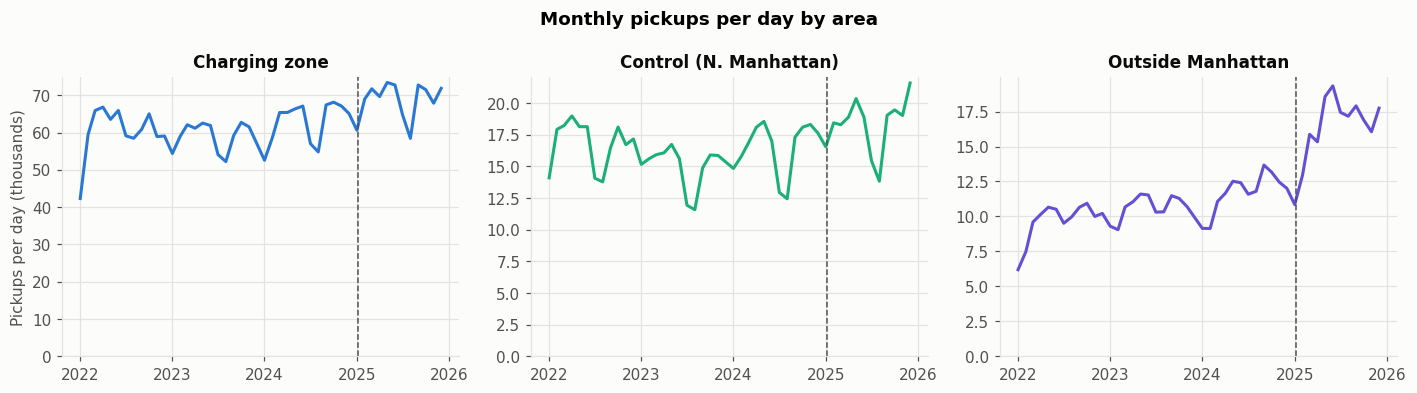

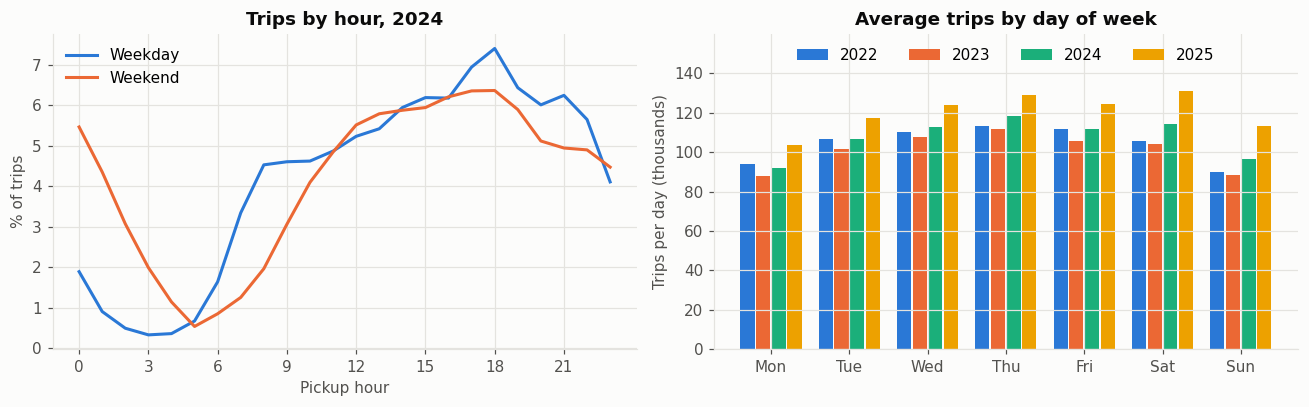

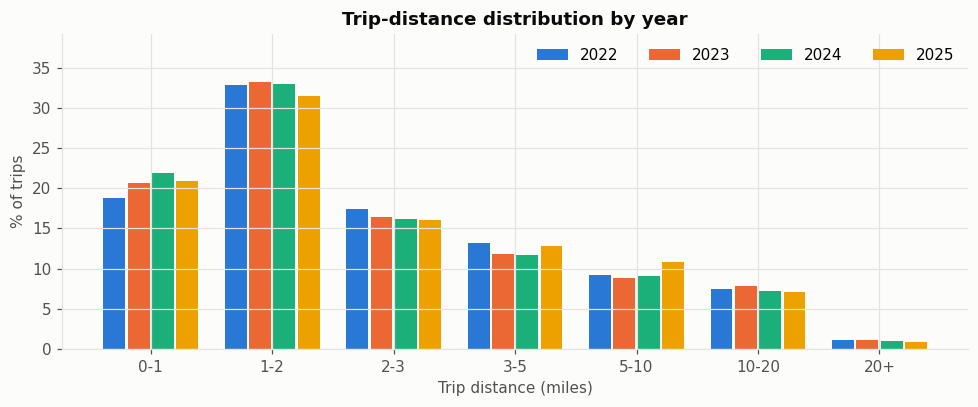

In [9]:
# Figures: monthly volumes by area, daily and weekly rhythm, trip-distance distribution
m_ = ph[~ph.pickup_date.isin(GAP_DAYS)].assign(m=lambda d: d.pickup_date.dt.to_period("M").dt.to_timestamp())
mv = m_.groupby(["m", "pu_grp"]).trips.sum().unstack() / m_.groupby("m").pickup_date.nunique().values[:, None] / 1e3
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, gname in zip(axes, ["charging_zone", "control_manhattan", "outside_manhattan"]):
    ax.plot(mv.index, mv[gname], color=GROUP_COLOR.get(gname, PAL["violet"]))
    ax.axvline(TOLL_START, color=PAL["ink2"], ls="--", lw=1); ax.set_title(GROUP_LABEL[gname], fontsize=11)
    ax.set_ylim(bottom=0)
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("Pickups per day (thousands)")
fig.suptitle("Monthly pickups per day by area", fontweight="bold"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
h24 = ph[(ph.pickup_date.dt.year == 2024) & ~ph.pickup_date.isin(GAP_DAYS)]
prof = h24.groupby(["weekend", "hour"]).trips.sum().unstack(0); prof = prof / prof.sum() * 100
axes[0].plot(prof.index, prof[False], color=PAL["blue"], label="Weekday")
axes[0].plot(prof.index, prof[True], color=PAL["orange"], label="Weekend")
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_xlabel("Pickup hour"); axes[0].set_ylabel("% of trips")
axes[0].set_title("Trips by hour, 2024"); axes[0].legend(loc="upper left")
dd_ = ph[~ph.pickup_date.isin(GAP_DAYS)].groupby("pickup_date").trips.sum().reset_index()
dd_["dow"] = dd_.pickup_date.dt.dayofweek; dd_["year"] = dd_.pickup_date.dt.year
dw = dd_.groupby(["dow", "year"]).trips.mean().unstack() / 1e3
yrs = list(dw.columns); width = 0.8 / len(yrs); ycol = [PAL["blue"], PAL["orange"], PAL["aqua"], PAL["yellow"]]
for i, y in enumerate(yrs):
    axes[1].bar(dw.index + (i - (len(yrs) - 1) / 2) * width, dw[y], width=width * 0.9, color=ycol[i % 4], label=str(y))
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_ylabel("Trips per day (thousands)"); axes[1].set_title("Average trips by day of week")
axes[1].set_ylim(0, dw.values.max() * 1.22); axes[1].legend(ncol=4, loc="upper center")
plt.tight_layout(); plt.show()

order = ["0-1", "1-2", "2-3", "3-5", "5-10", "10-20", "20+"]
db = pd_ok.groupby(["dist_bin", "year"]).trips.sum().unstack().reindex(order); db = db / db.sum() * 100
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, y in enumerate(db.columns):
    ax.bar(np.arange(len(order)) + (i - (len(db.columns) - 1) / 2) * width, db[y], width=width * 0.9, color=ycol[i % 4], label=str(y))
ax.set_xticks(range(len(order)), order); ax.set_xlabel("Trip distance (miles)"); ax.set_ylabel("% of trips")
ax.set_title("Trip-distance distribution by year"); ax.set_ylim(0, db.values.max() * 1.18); ax.legend(ncol=4, loc="upper right")
plt.tight_layout(); plt.show()

### B2. Further descriptive analysis

**Correlations, raw vs deseasonalised.** Which daily relationships survive once day-of-week and month effects are removed.

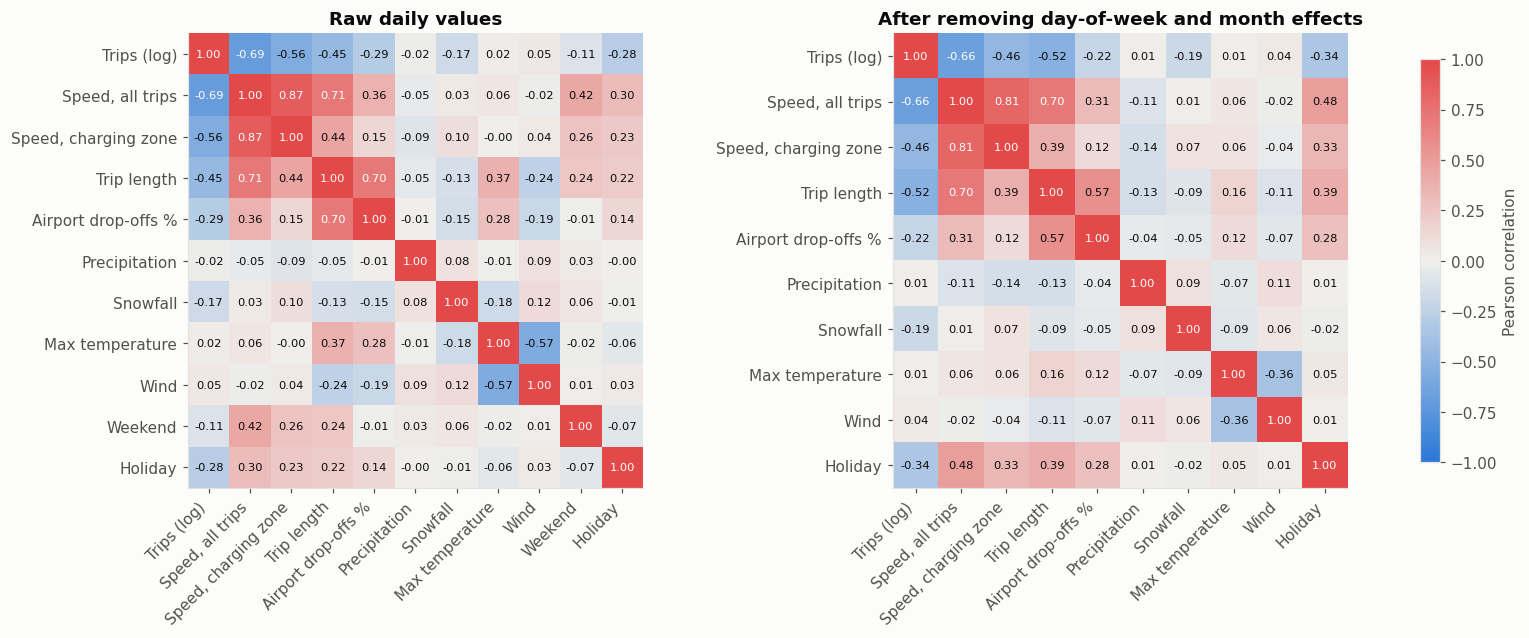

In [10]:
# Correlation heatmaps: raw daily values vs after removing day-of-week and month effects
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list("div", [PAL["blue"], "#f0efec", PAL["red"]])

dd = ph_ok.groupby("pickup_date")[["trips", "dist", "dur"]].sum()
cz = ph_ok[(ph_ok.pu_grp == "charging_zone") & (ph_ok.do_grp == "charging_zone")].groupby("pickup_date")[["dist", "dur"]].sum()
air = pzd[~pzd.pickup_date.isin(GAP_DAYS)].groupby("pickup_date")[["n_airport", "trips"]].sum()
daily = pd.DataFrame({"log_trips": np.log(dd.trips), "speed": dd.dist / dd.dur * 60,
                      "cz_speed": cz.dist / cz.dur * 60, "mean_miles": dd.dist / dd.trips,
                      "airport_pct": air.n_airport / air.trips * 100}).reset_index()
daily = daily.merge(wx, on="pickup_date", how="left")
daily["weekend"] = (daily.pickup_date.dt.dayofweek >= 5).astype(int)
daily["holiday"] = daily.pickup_date.isin(HOLIDAYS).astype(int)
daily["dow"] = daily.pickup_date.dt.dayofweek
daily["ym"] = daily.pickup_date.dt.to_period("M").astype(str)
LABELS = {"log_trips": "Trips (log)", "speed": "Speed, all trips", "cz_speed": "Speed, charging zone",
          "mean_miles": "Trip length", "airport_pct": "Airport drop-offs %", "prcp_mm": "Precipitation",
          "snow_mm": "Snowfall", "tmax_c": "Max temperature", "wind_ms": "Wind", "weekend": "Weekend", "holiday": "Holiday"}
raw = daily[list(LABELS)].corr()
resid = {}
for v in [k for k in LABELS if k != "weekend"]:     # weekend is fully absorbed by day-of-week
    r = smf.ols(f"{v} ~ C(dow) + C(ym)", daily.dropna(subset=[v])).fit()
    resid[v] = r.resid
desea = pd.DataFrame(resid).corr()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.8), gridspec_kw={"wspace": 0.55})
for ax, cm, title in [(axes[0], raw, "Raw daily values"), (axes[1], desea, "After removing day-of-week and month effects")]:
    im = ax.imshow(cm.values, cmap=DIV, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cm)), [LABELS[c] for c in cm.columns], rotation=45, ha="right")
    ax.set_yticks(range(len(cm)), [LABELS[c] for c in cm.index]); ax.grid(False)
    for i in range(len(cm)):
        for j in range(len(cm)):
            val = cm.values[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(val) > 0.6 else PAL["ink"])
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.7, label="Pearson correlation")
plt.show()
raw.round(3).to_csv(f"{TAB_DIR}/corr_raw.csv"); desea.round(3).to_csv(f"{TAB_DIR}/corr_deseasonalised.csv")

**Calendar heatmap.** Every day of the four years at a glance: holidays, storms, gap days and the missing month.

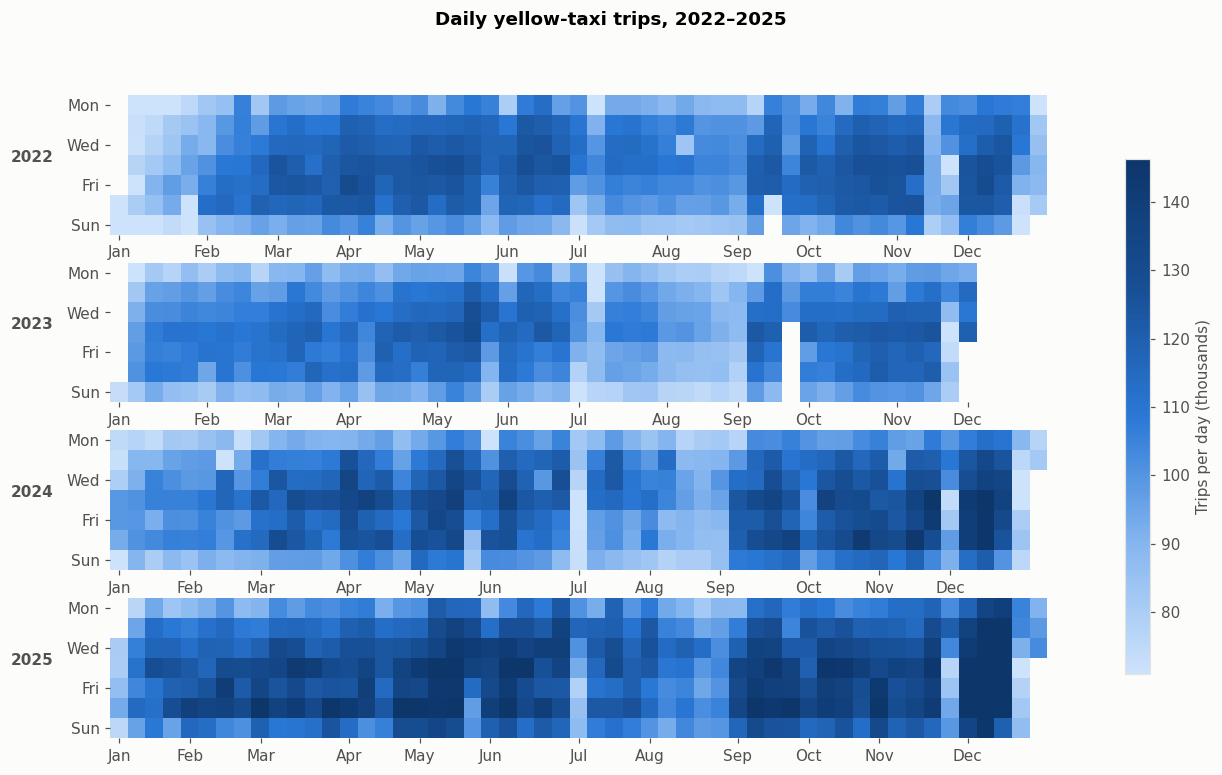

In [11]:
# Calendar heatmap of daily trips (blank cells = gap days / missing data)
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
dser = ph.groupby("pickup_date").trips.sum()
dser[dser.index.isin(GAP_DAYS)] = np.nan
years = sorted(dser.index.year.unique())
fig, axes = plt.subplots(len(years), 1, figsize=(14, 1.9 * len(years)), squeeze=False)
vmin, vmax = np.nanpercentile(dser / 1e3, [2, 98])
for ax, y in zip(axes[:, 0], years):
    days = pd.date_range(f"{y}-01-01", f"{y}-12-31")
    vals = dser.reindex(days) / 1e3
    week = ((days.dayofyear - 1 + pd.Timestamp(f"{y}-01-01").dayofweek) // 7)
    grid = np.full((7, 54), np.nan)
    grid[days.dayofweek, week] = vals.values
    im = ax.imshow(grid, aspect="auto", cmap=SEQ, vmin=vmin, vmax=vmax)
    ax.set_yticks([0, 2, 4, 6], ["Mon", "Wed", "Fri", "Sun"]); ax.grid(False)
    mstarts = [((pd.Timestamp(f"{y}-{m:02d}-01").dayofyear - 1 + pd.Timestamp(f"{y}-01-01").dayofweek) // 7) for m in range(1, 13)]
    ax.set_xticks(mstarts, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    ax.set_ylabel(str(y), rotation=0, labelpad=22, fontweight="bold")
    for sp in ax.spines.values(): sp.set_visible(False)
fig.colorbar(im, ax=axes[:, 0], shrink=0.8, label="Trips per day (thousands)")
fig.suptitle("Daily yellow-taxi trips, 2022–2025", fontweight="bold", x=0.45)
plt.show()

**Speed by hour and weekday, 2024 vs 2025.** Where in the week charging-zone speeds changed (raw, not yet net of the control).

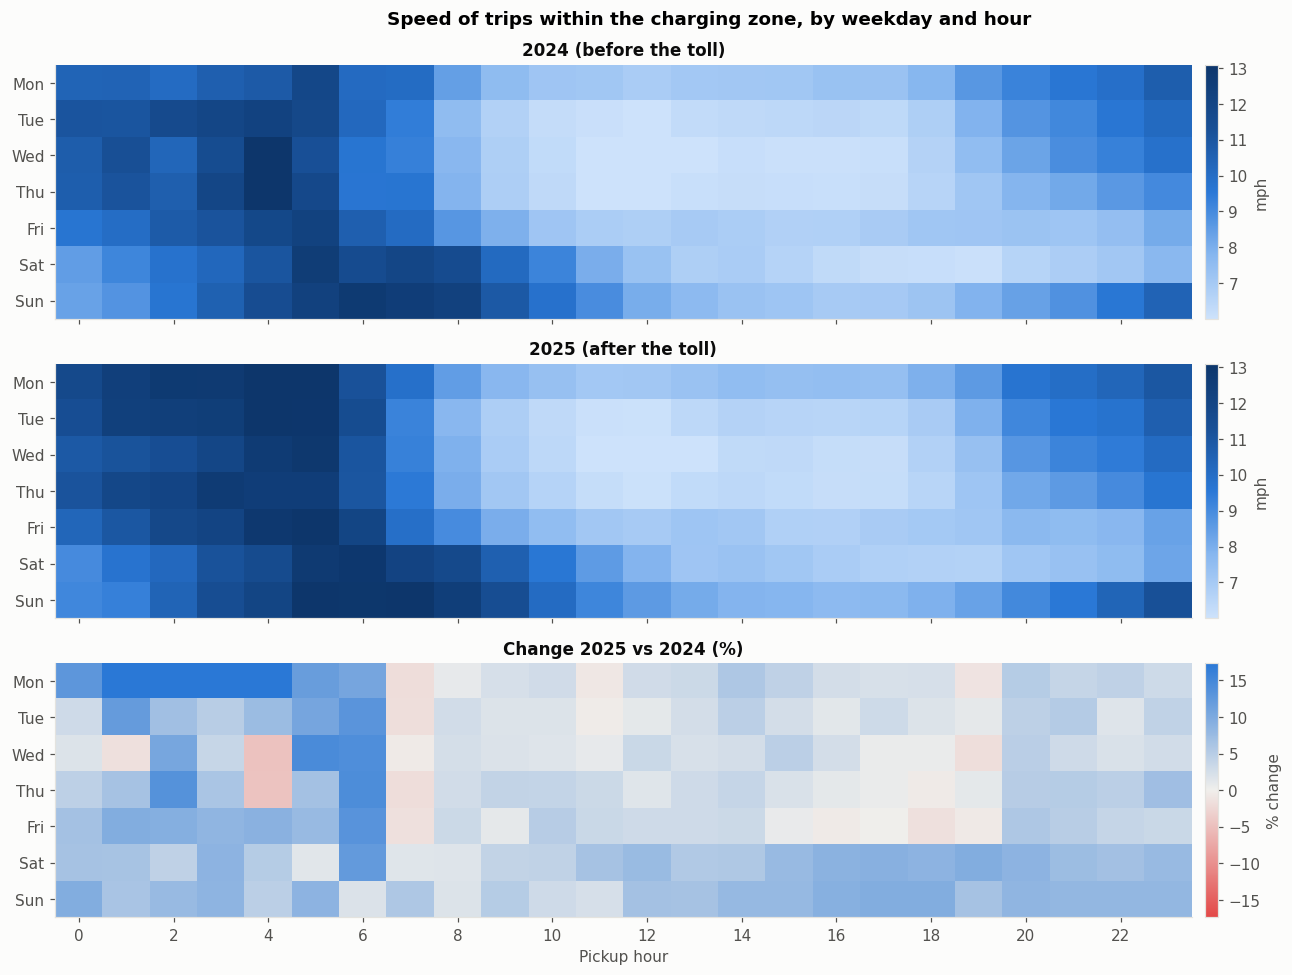

Raw 2025 vs 2024 change — not yet net of the control group or seasonality (Sections 1–2 do that).


In [12]:
# Speed by hour and weekday inside the charging zone: 2024, 2025 and % change
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [PAL["red"], "#f0efec", PAL["blue"]])
cz_h = ph_ok[(ph_ok.pu_grp == "charging_zone") & (ph_ok.do_grp == "charging_zone")].copy()
cz_h["dow"] = cz_h.pickup_date.dt.dayofweek; cz_h["year"] = cz_h.pickup_date.dt.year
def speed_grid(yr):
    g = cz_h[cz_h.year == yr].groupby(["dow", "hour"])[["dist", "dur"]].sum()
    return (g.dist / g.dur * 60).unstack().reindex(index=range(7), columns=range(24))
s24, s25 = speed_grid(2024), speed_grid(2025)
chg_ = (s25 / s24 - 1) * 100
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
lo_, hi_ = np.nanpercentile(np.r_[s24.values.ravel(), s25.values.ravel()], [2, 98])
lim = np.nanpercentile(np.abs(chg_.values), 98)
for ax, grid, title, cmap, vmin, vmax, lab in [
        (axes[0], s24, "2024 (before the toll)", SEQ, lo_, hi_, "mph"),
        (axes[1], s25, "2025 (after the toll)", SEQ, lo_, hi_, "mph"),
        (axes[2], chg_, "Change 2025 vs 2024 (%)", DIV, -lim, lim, "% change")]:
    im = ax.imshow(grid.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax.grid(False)
    ax.set_title(title, fontsize=11); fig.colorbar(im, ax=ax, label=lab, pad=0.01)
axes[2].set_xticks(range(0, 24, 2)); axes[2].set_xlabel("Pickup hour")
fig.suptitle("Speed of trips within the charging zone, by weekday and hour", fontweight="bold")
plt.tight_layout(); plt.show()
print("Raw 2025 vs 2024 change — not yet net of the control group or seasonality (Sections 1–2 do that).")

**Origin–destination matrix.** Whether trips shifted between the charging zone, buffer, north Manhattan and the rest of the city.

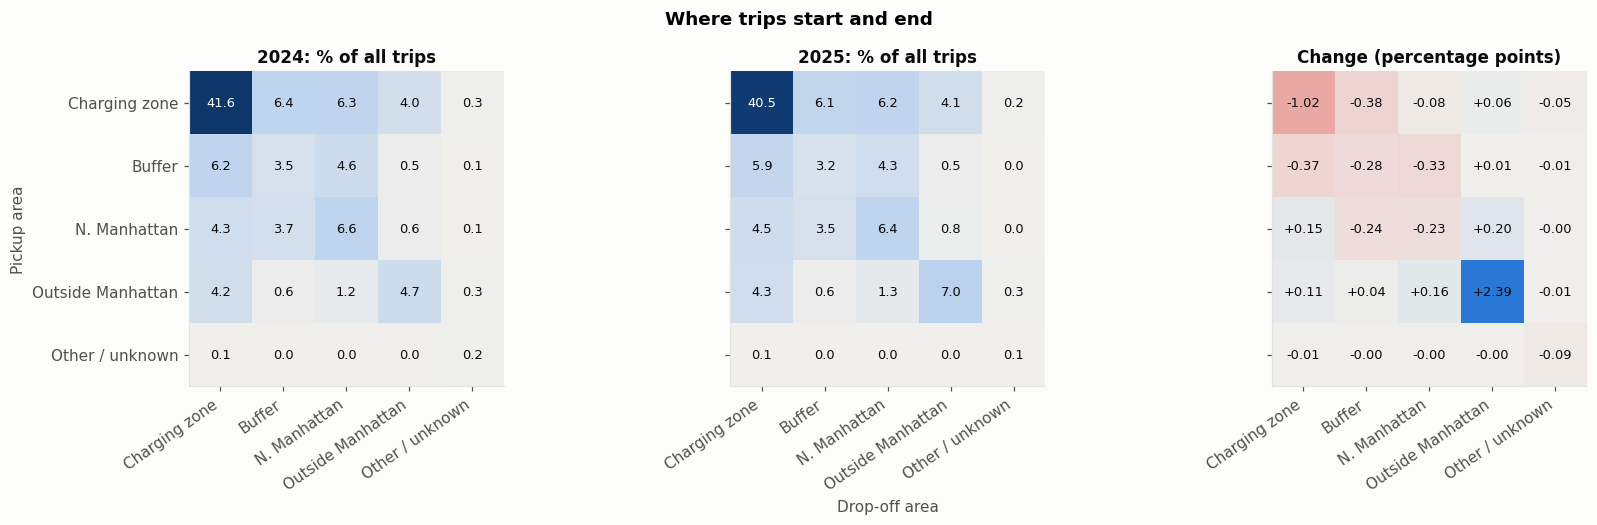

In [13]:
# Origin–destination matrix between areas: share of trips, 2024 vs 2025
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [PAL["red"], "#f0efec", PAL["blue"]])
AREA = {"charging_zone": "Charging zone", "buffer": "Buffer", "control_manhattan": "N. Manhattan",
        "outside_manhattan": "Outside Manhattan", "excluded_island": "Other / unknown", "other": "Other / unknown"}
od = ph_ok.assign(o=ph_ok.pu_grp.map(AREA), d=ph_ok.do_grp.map(AREA), year=ph_ok.pickup_date.dt.year)
order = ["Charging zone", "Buffer", "N. Manhattan", "Outside Manhattan", "Other / unknown"]
def od_share(yr):
    m = od[od.year == yr].pivot_table(index="o", columns="d", values="trips", aggfunc="sum").reindex(index=order, columns=order).fillna(0)
    return m / m.values.sum() * 100
o24, o25 = od_share(2024), od_share(2025)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
lim = np.abs((o25 - o24).values).max()
for ax, m, title, cmap, vmin, vmax, fmt in [(axes[0], o24, "2024: % of all trips", SEQ, 0, None, "{:.1f}"),
                                            (axes[1], o25, "2025: % of all trips", SEQ, 0, None, "{:.1f}"),
                                            (axes[2], o25 - o24, "Change (percentage points)", DIV, -lim, lim, "{:+.2f}")]:
    vmax = vmax if vmax is not None else max(o24.values.max(), o25.values.max())
    ax.imshow(m.values, cmap=cmap, vmin=vmin, vmax=vmax); ax.grid(False)
    ax.set_xticks(range(len(order)), order, rotation=35, ha="right"); ax.set_yticks(range(len(order)), order if ax is axes[0] else [])
    for i in range(len(order)):
        for j in range(len(order)):
            v = m.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8.5,
                    color="white" if (cmap is SEQ and v > 0.6 * vmax) else PAL["ink"])
    ax.set_title(title, fontsize=11)
axes[0].set_ylabel("Pickup area"); axes[1].set_xlabel("Drop-off area")
fig.suptitle("Where trips start and end", fontweight="bold"); plt.tight_layout(); plt.show()
(o25 - o24).round(3).to_csv(f"{TAB_DIR}/od_change_pp.csv")

**Zone maps.** Where pickups concentrate, and which Manhattan zones gained or lost pickups after the toll.

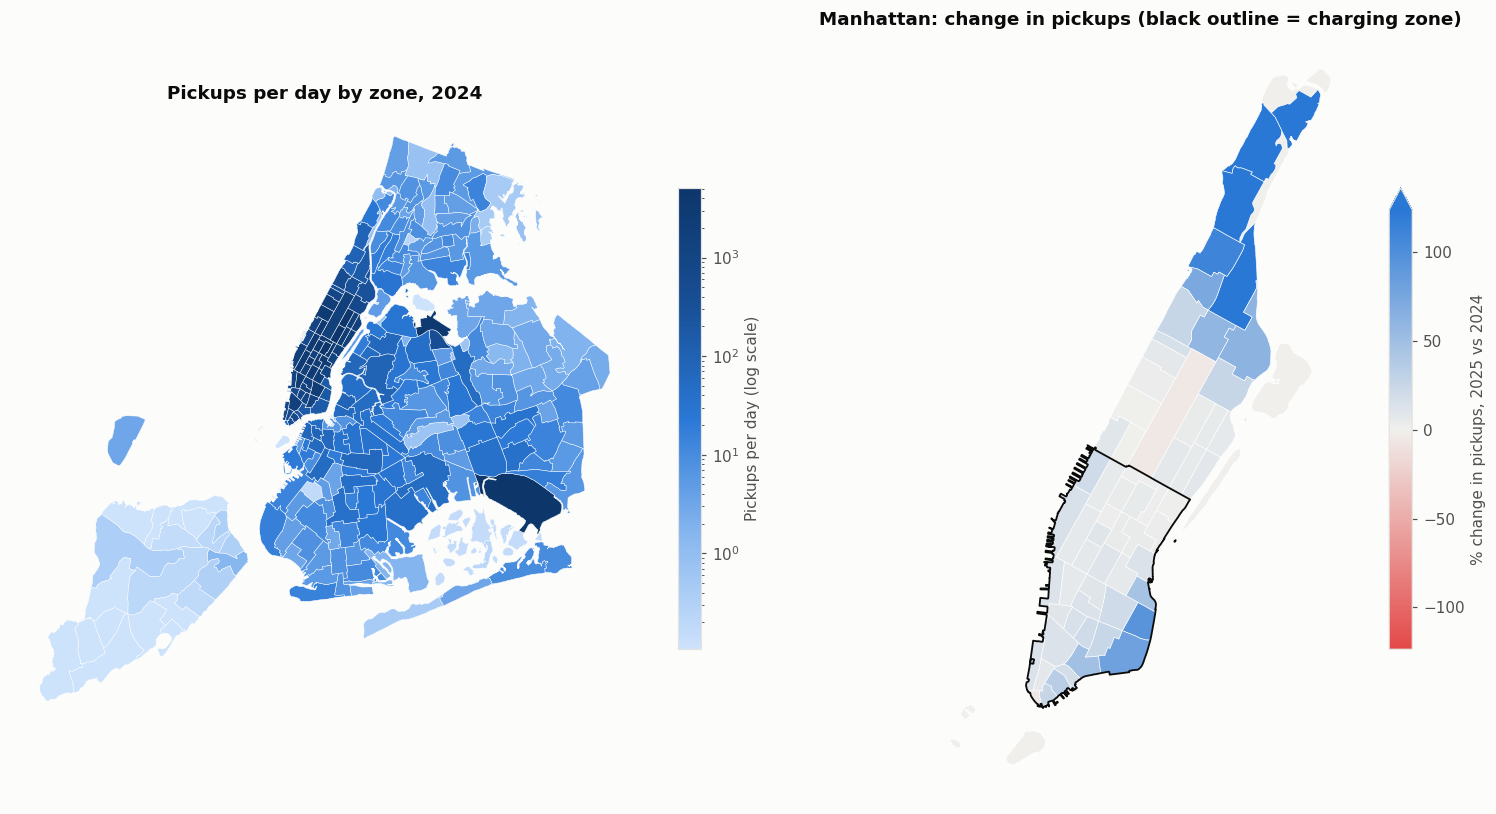

In [14]:
# Zone maps: pickups per day (2024) and % change 2025 vs 2024
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [PAL["red"], "#f0efec", PAL["blue"]])
zmap = zgeo if "zgeo" in globals() else gpd.read_file(ZONE_SHP)
pz = pzd[~pzd.pickup_date.isin(GAP_DAYS)].assign(year=lambda d: d.pickup_date.dt.year)
ndays = pz.groupby("year").pickup_date.nunique()
per_day = pz.groupby(["zone_id", "year"]).trips.sum().unstack() / ndays
zm = zmap.merge(per_day, left_on="LocationID", right_index=True, how="left")
zm["chg"] = np.where(zm[2024] >= 10, (zm[2025] / zm[2024] - 1) * 100, np.nan)   # only zones with ≥10 pickups/day

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
zm.plot(ax=axes[0], color="#f0efec", edgecolor="white", linewidth=0.3)
zm[zm[2024] > 0].plot(ax=axes[0], column=2024, cmap=SEQ, norm=LogNorm(vmin=max(zm[2024].quantile(0.05), 0.1), vmax=zm[2024].max()),
                      edgecolor="white", linewidth=0.3, legend=True, legend_kwds={"label": "Pickups per day (log scale)", "shrink": 0.6})
axes[0].set_title("Pickups per day by zone, 2024")
man = zm[zm.borough == "Manhattan"]
lim = np.nanpercentile(np.abs(man.chg), 95)
man.plot(ax=axes[1], color="#f0efec", edgecolor="white", linewidth=0.4)
man[man.chg.notna()].plot(ax=axes[1], column="chg", cmap=DIV, vmin=-lim, vmax=lim, edgecolor="white", linewidth=0.4,
                          legend=True, legend_kwds={"label": "% change in pickups, 2025 vs 2024", "shrink": 0.6})
if "grp" in zm.columns:
    outline = zm[zm.grp == "charging_zone"].dissolve().buffer(60).buffer(-60)   # close slivers between zones
    outline.boundary.plot(ax=axes[1], color=PAL["ink"], linewidth=1.2)
axes[1].set_title("Manhattan: change in pickups (black outline = charging zone)")
for ax in axes: ax.set_axis_off()
plt.tight_layout(); plt.show()

**Trend and seasonal decomposition (MSTL).** Long-run trend, weekly and yearly cycles, and residual of daily trips.

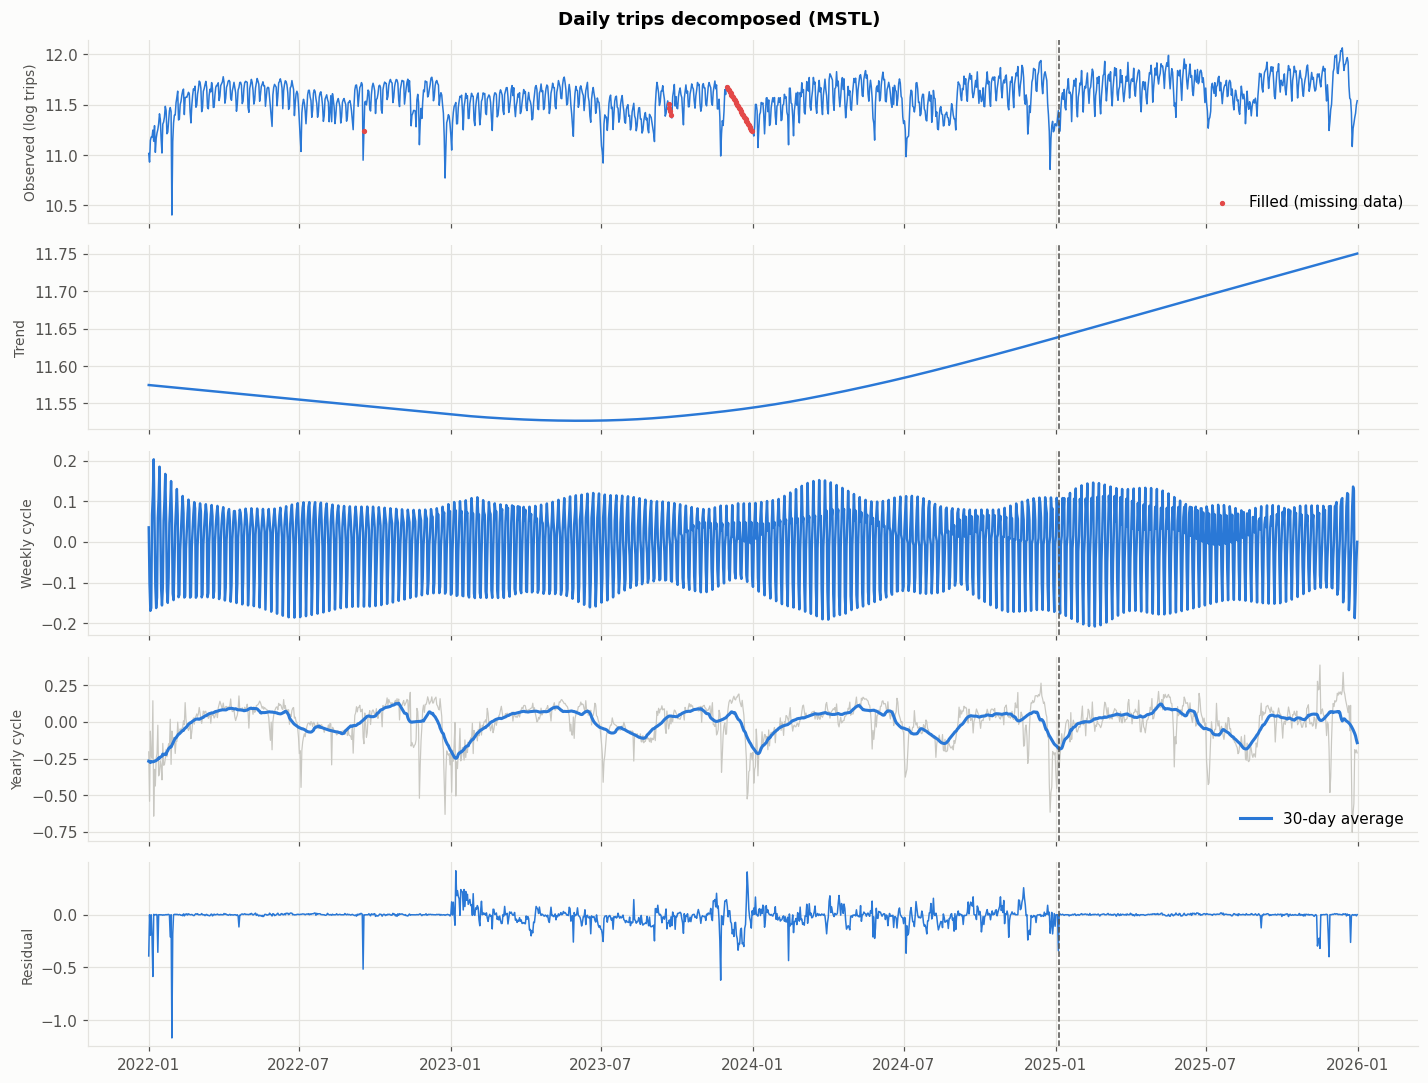

Trend level, Dec 2024 vs Dec 2025: 12.0% (citywide; includes the 2025 cleaning-rate change)


In [15]:
# Decomposing daily trips into trend, weekly cycle, yearly cycle and residual
from statsmodels.tsa.seasonal import MSTL
s = ph.groupby("pickup_date").trips.sum()
s = s.reindex(pd.date_range(s.index.min(), s.index.max()))
s[s.index.isin(GAP_DAYS)] = np.nan
y = np.log(s).interpolate(limit_direction="both")          # gap days and missing months filled for the decomposition only
res = MSTL(y, periods=(7, 365), stl_kwargs={"robust": True}).fit()
parts = [("Observed (log trips)", y), ("Trend", res.trend), ("Weekly cycle", res.seasonal["seasonal_7"]),
         ("Yearly cycle", res.seasonal["seasonal_365"]), ("Residual", res.resid)]
fig, axes = plt.subplots(len(parts), 1, figsize=(13, 10), sharex=True)
for ax, (name, ser) in zip(axes, parts):
    if name == "Yearly cycle":
        ax.plot(ser.index, ser.values, color=PAL["muted"], lw=0.8)
        ax.plot(ser.index, ser.rolling(30, center=True, min_periods=10).mean(), color=PAL["blue"], lw=2, label="30-day average")
        ax.legend(loc="lower right")
    else:
        ax.plot(ser.index, ser.values, color=PAL["blue"], lw=1 if name in ("Observed (log trips)", "Residual") else 1.6)
    ax.axvline(TOLL_START, color=PAL["ink2"], ls="--", lw=1); ax.set_ylabel(name, fontsize=9)
filled = s.isna()
axes[0].scatter(y.index[filled], y[filled], s=6, color=PAL["red"], zorder=3, label="Filled (missing data)")
axes[0].legend(loc="lower right")
fig.suptitle("Daily trips decomposed (MSTL)", fontweight="bold"); plt.tight_layout(); plt.show()
tr = res.trend
print(f"Trend level, Dec 2024 vs Dec 2025: {(np.exp(tr['2025-12'].mean() - tr['2024-12'].mean()) - 1) * 100:.1f}% "
      "(citywide; includes the 2025 cleaning-rate change)")

**Weather response curves.** How trips and speed vary across rain and temperature levels, net of calendar effects.

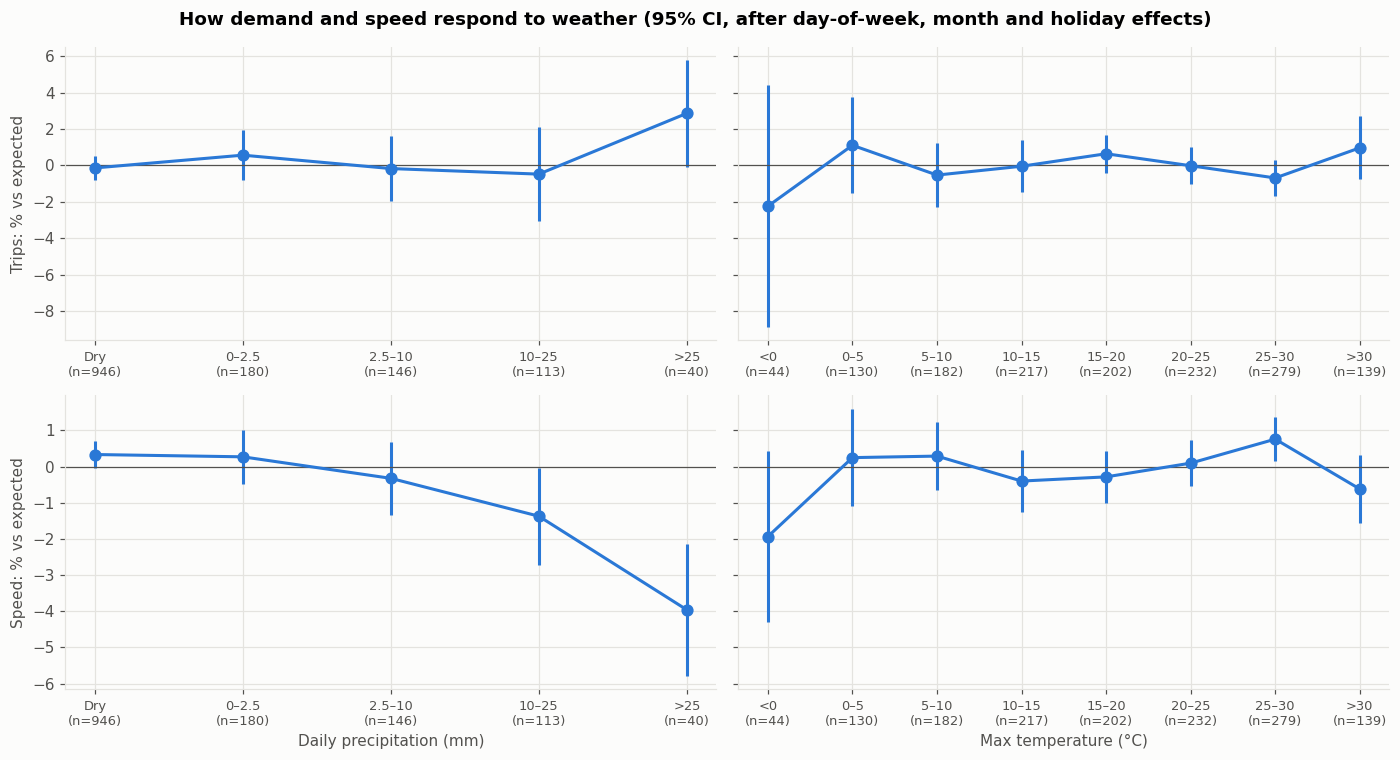

In [16]:
# Weather response curves: trips and speed vs rain and temperature, net of calendar effects
import statsmodels.formula.api as smf
dw_ = daily.dropna(subset=["log_trips", "speed"]).copy()
dw_["hol"] = dw_.holiday
for v in ["log_trips", "speed"]:
    r = smf.ols(f"{'np.log(' + v + ')' if v == 'speed' else v} ~ C(dow) + C(ym) + hol", dw_).fit()
    dw_[v + "_res"] = r.resid * 100            # % deviation from the expected day
dw_["rain_bin"] = pd.cut(dw_.prcp_mm, [-0.1, 0, 2.5, 10, 25, 1e4], labels=["Dry", "0–2.5", "2.5–10", "10–25", ">25"])
dw_["temp_bin"] = pd.cut(dw_.tmax_c, [-30, 0, 5, 10, 15, 20, 25, 30, 50],
                         labels=["<0", "0–5", "5–10", "10–15", "15–20", "20–25", "25–30", ">30"])
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey="row")
for row, v, ylab in [(0, "log_trips_res", "Trips: % vs expected"), (1, "speed_res", "Speed: % vs expected")]:
    for col, b, xlab in [(0, "rain_bin", "Daily precipitation (mm)"), (1, "temp_bin", "Max temperature (°C)")]:
        g = dw_.groupby(b, observed=True)[v].agg(["mean", "sem", "count"])
        ax = axes[row, col]
        ax.errorbar(range(len(g)), g["mean"], yerr=1.96 * g["sem"], fmt="o-", color=PAL["blue"], ms=7, capsize=0, lw=2)
        ax.axhline(0, color=PAL["ink2"], lw=0.8)
        ax.set_xticks(range(len(g)), [f"{i}\n(n={n})" for i, n in zip(g.index, g["count"])], fontsize=8.5)
        if col == 0: ax.set_ylabel(ylab)
        if row == 1: ax.set_xlabel(xlab)
fig.suptitle("How demand and speed respond to weather (95% CI, after day-of-week, month and holiday effects)", fontweight="bold")
plt.tight_layout(); plt.show()

## R. Regression analysis (OLS)
Daily trips are regressed on weather, building up from one-variable regressions (as in Tang, 2019) to a full model with day-of-week,
month and year effects. Diagnostics then check the OLS assumptions and justify Newey–West standard errors.
These regressions describe day-to-day variation; the causal toll estimates are in Sections 1–2.

Table R1. OLS: log daily trips on weather and calendar (Newey-West SE in parentheses; *** p<0.01, ** p<0.05, * p<0.1)
Coefficients are log points: ×100 ≈ % change in daily trips per unit.


,(1),(2),(3),(4),(5),(6),(7)
Precipitation (cm),,,-0.0035,-0.0019,-0.0017,0.0023,0.0019
,,,(0.0050),(0.0049),(0.0041),(0.0034),(0.0035)
Snowfall (cm),,-0.0366***,,-0.0245**,-0.0280**,-0.0260**,-0.0265**
,,(0.0123),,(0.0116),(0.0123),(0.0113),(0.0115)
Snow depth (cm),-0.0240***,,,-0.0177***,-0.0157***,-0.0096***,-0.0095***
,(0.0065),,,(0.0050),(0.0048),(0.0036),(0.0036)
"Max temp (°C, from 18)",,,,-0.0006,-0.0010,0.0006,0.0013
,,,,(0.0012),(0.0011),(0.0009),(0.0008)
Max temp² (/10),,,,,,,0.0003
,,,,,,,(0.0007)


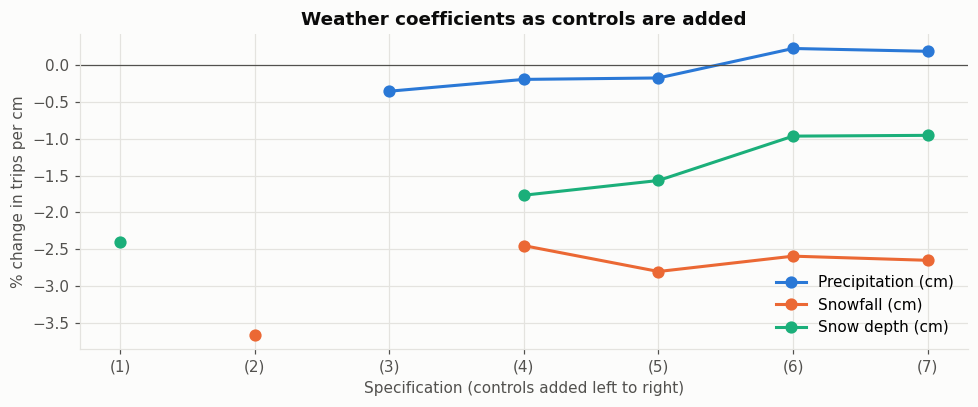

Table R2. OLS: log daily speed on weather and calendar (same controls as column 7)


,"Speed, all trips","Speed, charging zone"
Precipitation (cm),-0.0097***,-0.0110***
,(0.0020),(0.0026)
Snowfall (cm),0.0046,0.0087**
,(0.0054),(0.0035)
Snow depth (cm),-0.0018,0.0002
,(0.0023),(0.0013)
"Max temp (°C, from 18)",0.0003,0.0004
,(0.0004),(0.0004)
Max temp² (/10),-0.0004,-0.0004*
,(0.0003),(0.0002)


In [17]:
# OLS regression table: weather and calendar effects on daily trips, built up step by step
#           Columns (1)-(3) replicate one-variable regressions as in Tang (2019); (4)-(7) add controls.
#           Standard errors: Newey-West (HAC, 7 lags), robust to heteroskedasticity and autocorrelation.
import statsmodels.formula.api as smf

ph_ok_ = ph[~ph.pickup_date.isin(GAP_DAYS)]
dly = ph_ok_.groupby("pickup_date")[["trips", "dist", "dur"]].sum()
czd = ph_ok_[(ph_ok_.pu_grp == "charging_zone") & (ph_ok_.do_grp == "charging_zone")].groupby("pickup_date")[["dist", "dur"]].sum()
reg = pd.DataFrame({"log_trips": np.log(dly.trips), "log_speed": np.log(dly.dist / dly.dur * 60),
                    "log_cz_speed": np.log(czd.dist / czd.dur * 60)}).reset_index()
reg = reg.merge(wx, on="pickup_date", how="left")
reg["prcp_cm"] = reg.prcp_mm / 10; reg["snow_cm"] = reg.snow_mm / 10; reg["snowdepth_cm"] = reg.snow_depth_mm / 10
reg["tmax_dev"] = reg.tmax_c - 18; reg["tmax_dev_sq"] = reg.tmax_dev ** 2 / 10     # centred at 18°C; squared term per 10
reg["holiday"] = reg.pickup_date.isin(HOLIDAYS).astype(int)
reg["dow"] = reg.pickup_date.dt.dayofweek; reg["month"] = reg.pickup_date.dt.month; reg["year"] = reg.pickup_date.dt.year
reg = reg.dropna(subset=["log_trips", "prcp_cm", "snow_cm", "snowdepth_cm", "tmax_c", "wind_ms"]).reset_index(drop=True)

SPECS = [
    ("(1)", "log_trips ~ snowdepth_cm"),
    ("(2)", "log_trips ~ snow_cm"),
    ("(3)", "log_trips ~ prcp_cm"),
    ("(4)", "log_trips ~ prcp_cm + snow_cm + snowdepth_cm + tmax_dev"),
    ("(5)", "log_trips ~ prcp_cm + snow_cm + snowdepth_cm + tmax_dev + holiday + C(dow)"),
    ("(6)", "log_trips ~ prcp_cm + snow_cm + snowdepth_cm + tmax_dev + holiday + C(dow) + C(month) + C(year)"),
    ("(7)", "log_trips ~ prcp_cm + snow_cm + snowdepth_cm + tmax_dev + tmax_dev_sq + wind_ms + holiday + C(dow) + C(month) + C(year)"),
]
SHOW = {"prcp_cm": "Precipitation (cm)", "snow_cm": "Snowfall (cm)", "snowdepth_cm": "Snow depth (cm)",
        "tmax_dev": "Max temp (°C, from 18)", "tmax_dev_sq": "Max temp² (/10)", "wind_ms": "Wind (m/s)",
        "holiday": "Public holiday", "Intercept": "Constant"}

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def reg_table(specs, data, show):
    fits, cols = {}, {}
    for name, f in specs:
        r = smf.ols(f, data).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
        fits[name] = r
        cell = {}
        for v, lab in show.items():
            if v in r.params:
                cell[lab] = f"{r.params[v]:.4f}{stars(r.pvalues[v])}"
                cell[lab + "|se"] = f"({r.bse[v]:.4f})"
            else:
                cell[lab] = ""; cell[lab + "|se"] = ""
        cell["Day-of-week effects"] = "Yes" if "C(dow)" in f else "No"
        cell["Month effects"] = "Yes" if "C(month)" in f else "No"
        cell["Year effects"] = "Yes" if "C(year)" in f else "No"
        cell["Observations (days)"] = f"{int(r.nobs):,}"
        cell["R²"] = f"{r.rsquared:.3f}"; cell["Adjusted R²"] = f"{r.rsquared_adj:.3f}"
        cols[name] = cell
    t = pd.DataFrame(cols)
    t.index = ["" if i.endswith("|se") else i for i in t.index]      # standard-error rows sit under their coefficient
    return t, fits

tab_trips, FITS_TRIPS = reg_table(SPECS, reg, SHOW)
print("Table R1. OLS: log daily trips on weather and calendar (Newey-West SE in parentheses; *** p<0.01, ** p<0.05, * p<0.1)")
print("Coefficients are log points: ×100 ≈ % change in daily trips per unit.")
display(tab_trips)
tab_trips.to_csv(f"{TAB_DIR}/regression_table_trips.csv")

# How the weather coefficients change once calendar effects are controlled
path = pd.DataFrame({name: {SHOW[v]: r.params.get(v, np.nan) * 100 for v in ["prcp_cm", "snow_cm", "snowdepth_cm"]}
                     for name, r in FITS_TRIPS.items()}).T
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (lab, col) in enumerate(zip(path.columns, [PAL["blue"], PAL["orange"], PAL["aqua"]])):
    ax.plot(range(len(path)), path[lab], "o-", color=col, ms=7, label=lab)
ax.axhline(0, color=PAL["ink2"], lw=0.8)
ax.set_xticks(range(len(path)), path.index); ax.set_xlabel("Specification (controls added left to right)")
ax.set_ylabel("% change in trips per cm"); ax.set_title("Weather coefficients as controls are added")
ax.legend(loc="best"); plt.tight_layout(); plt.show()

# Full specification for speed (citywide and inside the charging zone, internal trips)
SPEC_SPEED = ("prcp_cm + snow_cm + snowdepth_cm + tmax_dev + tmax_dev_sq + wind_ms + holiday + C(dow) + C(month) + C(year)")
tab_speed, FITS_SPEED = reg_table([("Speed, all trips", "log_speed ~ " + SPEC_SPEED),
                                   ("Speed, charging zone", "log_cz_speed ~ " + SPEC_SPEED)],
                                  reg.dropna(subset=["log_speed", "log_cz_speed"]), SHOW)
print("Table R2. OLS: log daily speed on weather and calendar (same controls as column 7)")
display(tab_speed)
tab_speed.to_csv(f"{TAB_DIR}/regression_table_speed.csv")
full = FITS_TRIPS["(7)"]
for v in ["prcp_cm", "snow_cm", "snowdepth_cm", "holiday"]:
    record("R", f"OLS (7): {SHOW[v]} effect on trips (%)", pct(full.params[v]),
           pct(full.conf_int().loc[v, 0]), pct(full.conf_int().loc[v, 1]), full.pvalues[v])

**Diagnostics:** multicollinearity, heteroskedasticity, autocorrelation, normality, functional form and influential days.

Table R3. Diagnostic tests, model (7)


,Statistic,p-value,Interpretation
Test,,,
Breusch-Pagan (heteroskedasticity),388.1874,0.000,Variance of errors differs across days
Durbin-Watson (autocorrelation),0.6068,NaN,Positive autocorrelation (DW well below 2)
"Ljung-Box, 7 lags",1567.1108,0.000,Residuals correlated across the week
"Ljung-Box, 14 lags",1643.3042,0.000,Residuals correlated over two weeks
Jarque-Bera (normality),1266.9414,0.000,"Non-normal errors (skew -1.12, kurtosis 7.1)"
Ramsey RESET (functional form),0.0195,0.889,No evidence of misspecification


VIF (above ~5–10 signals problematic multicollinearity):


,VIF
Precipitation (cm),1.05
Snowfall (cm),1.33
Snow depth (cm),1.45
"Max temp (°C, from 18)",5.73
Max temp² (/10),1.83
Wind (m/s),1.59
Public holiday,1.09


Standard errors under different assumptions — ratios above 1 show how much classical SEs understate uncertainty:


,Classical SE,Robust SE (HC1),Newey-West SE (7 lags),Newey-West / classical
Precipitation (cm),0.0034,0.0035,0.0035,1.0381
Snowfall (cm),0.0042,0.0117,0.0115,2.7324
Snow depth (cm),0.0028,0.0039,0.0036,1.2644
"Max temp (°C, from 18)",0.0007,0.0007,0.0008,1.1405
Max temp² (/10),0.0004,0.0005,0.0007,1.5800
Wind (m/s),0.0035,0.0037,0.0045,1.2633
Public holiday,0.0153,0.0303,0.0324,2.1249


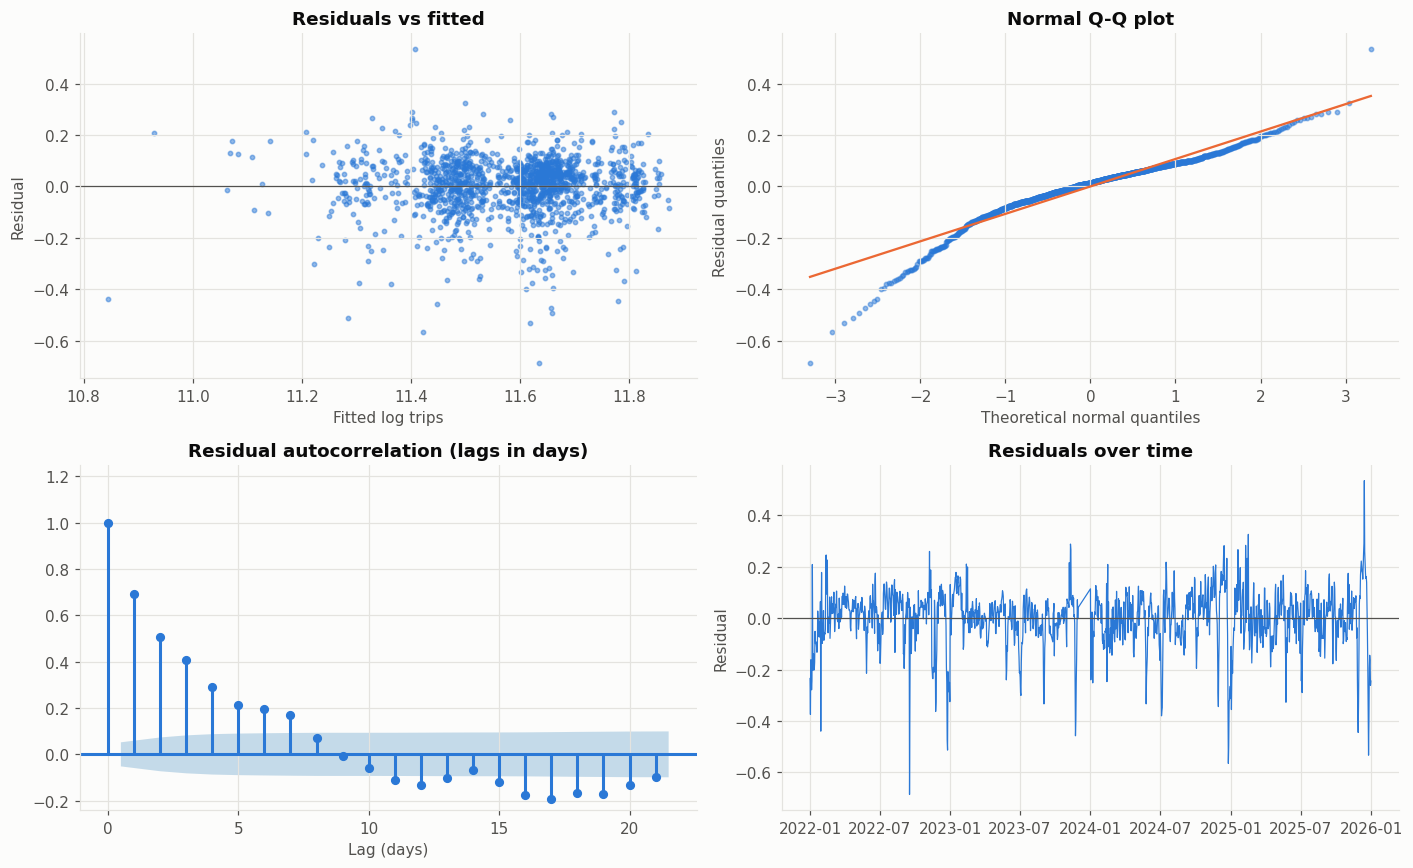

Most influential days (Cook's distance; rule of thumb 4/n = 0.0028). Check each for events or data problems:


,pickup_date,cooks,resid_pct,prcp_mm,snow_mm,tmax_c,holiday
28,2022-01-29,0.5366,-35.58,19.6,185.0,-1.6,0
1401,2025-12-14,0.0772,70.81,13.0,74.0,0.6,0
6,2022-01-07,0.0571,23.24,9.7,147.0,1.1,0
356,2022-12-24,0.0450,-37.70,0.0,0.0,-9.3,0
1048,2024-12-25,0.0414,-43.18,0.0,0.0,1.7,1
357,2022-12-25,0.0358,-40.15,0.0,0.0,-2.1,1
1412,2025-12-25,0.0310,-41.33,0.0,0.0,9.4,1
1093,2025-02-08,0.0270,32.76,15.5,76.0,1.7,0
1413,2025-12-26,0.0244,-32.74,6.9,43.0,-1.7,0
259,2022-09-17,0.0218,-49.65,0.0,0.0,24.4,0


Coefficients (×100, ≈ % effect) with and without the most influential days:


,All days,Without 10 influential days
Precipitation (cm),0.19,0.08
Snowfall (cm),-2.65,-2.65
Snow depth (cm),-0.95,-0.88
"Max temp (°C, from 18)",0.13,0.11
Max temp² (/10),0.03,0.08
Wind (m/s),0.79,0.92
Public holiday,-20.30,-17.01


In [18]:
# Regression diagnostics for the full model (column 7)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.graphics.tsaplots import plot_acf
import scipy.stats as st

f7 = SPECS[-1][1]
ols7 = smf.ols(f7, reg).fit()                  # classical fit, used for the tests
res = ols7.resid; fitted = ols7.fittedvalues
X = ols7.model.exog; names = ols7.model.exog_names

# 1. Multicollinearity among the weather and holiday regressors
wcols = [i for i, n in enumerate(names) if n in SHOW and n != "Intercept"]
vif = pd.Series({SHOW[names[i]]: variance_inflation_factor(X, i) for i in wcols}, name="VIF")
# 2-5. Formal tests
bp = het_breuschpagan(res, X)
dw = durbin_watson(res)
lb = acorr_ljungbox(res, lags=[7, 14], return_df=True)
jb_stat, jb_p, skew, kurt = jarque_bera(res)
reset = linear_reset(ols7, power=2, use_f=True)

tests = pd.DataFrame([
    ["Breusch-Pagan (heteroskedasticity)", bp[0], bp[1],
     "Variance of errors differs across days" if bp[1] < 0.05 else "No evidence of heteroskedasticity"],
    ["Durbin-Watson (autocorrelation)", dw, np.nan,
     "Positive autocorrelation (DW well below 2)" if dw < 1.5 else "Little first-order autocorrelation"],
    ["Ljung-Box, 7 lags", lb.lb_stat.iloc[0], lb.lb_pvalue.iloc[0],
     "Residuals correlated across the week" if lb.lb_pvalue.iloc[0] < 0.05 else "No weekly autocorrelation"],
    ["Ljung-Box, 14 lags", lb.lb_stat.iloc[1], lb.lb_pvalue.iloc[1],
     "Residuals correlated over two weeks" if lb.lb_pvalue.iloc[1] < 0.05 else "No two-week autocorrelation"],
    ["Jarque-Bera (normality)", jb_stat, jb_p,
     f"Non-normal errors (skew {skew:.2f}, kurtosis {kurt:.1f})" if jb_p < 0.05 else "Errors approximately normal"],
    ["Ramsey RESET (functional form)", float(reset.fvalue), float(reset.pvalue),
     "Possible missing nonlinearity" if reset.pvalue < 0.05 else "No evidence of misspecification"],
], columns=["Test", "Statistic", "p-value", "Interpretation"]).set_index("Test")
print("Table R3. Diagnostic tests, model (7)")
display(tests.round(4)); tests.round(4).to_csv(f"{TAB_DIR}/regression_diagnostics.csv")
print("VIF (above ~5–10 signals problematic multicollinearity):"); display(vif.round(2).to_frame())

# Implication for inference: compare classical, robust (HC1) and Newey-West standard errors
se_cmp = pd.DataFrame({
    "Classical SE": ols7.bse, "Robust SE (HC1)": smf.ols(f7, reg).fit(cov_type="HC1").bse,
    "Newey-West SE (7 lags)": smf.ols(f7, reg).fit(cov_type="HAC", cov_kwds={"maxlags": 7}).bse})
se_cmp = se_cmp.loc[[n for n in names if n in SHOW and n != "Intercept"]].rename(index=SHOW)
se_cmp["Newey-West / classical"] = se_cmp["Newey-West SE (7 lags)"] / se_cmp["Classical SE"]
print("Standard errors under different assumptions — ratios above 1 show how much classical SEs understate uncertainty:")
display(se_cmp.round(4)); se_cmp.round(5).to_csv(f"{TAB_DIR}/regression_se_comparison.csv")

# Plots: residuals vs fitted, Q-Q, residual autocorrelation, residuals over time
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].scatter(fitted, res, s=8, alpha=0.5, color=PAL["blue"]); axes[0, 0].axhline(0, color=PAL["ink2"], lw=0.8)
axes[0, 0].set_xlabel("Fitted log trips"); axes[0, 0].set_ylabel("Residual"); axes[0, 0].set_title("Residuals vs fitted")
(osm, osr), (slope, intercept, _) = st.probplot(res, dist="norm")
axes[0, 1].scatter(osm, osr, s=8, alpha=0.5, color=PAL["blue"])
axes[0, 1].plot(osm, slope * np.asarray(osm) + intercept, color=PAL["orange"], lw=1.5)
axes[0, 1].set_xlabel("Theoretical normal quantiles"); axes[0, 1].set_ylabel("Residual quantiles"); axes[0, 1].set_title("Normal Q-Q plot")
plot_acf(res, lags=21, ax=axes[1, 0], color=PAL["blue"], vlines_kwargs={"colors": PAL["blue"]}, auto_ylims=True)
axes[1, 0].set_title("Residual autocorrelation (lags in days)"); axes[1, 0].set_xlabel("Lag (days)")
axes[1, 1].plot(reg.pickup_date, res, color=PAL["blue"], lw=0.8); axes[1, 1].axhline(0, color=PAL["ink2"], lw=0.8)
axes[1, 1].set_title("Residuals over time"); axes[1, 1].set_ylabel("Residual")
plt.tight_layout(); plt.show()

# Most influential days (Cook's distance)
infl = ols7.get_influence(); cooks = infl.cooks_distance[0]
top = reg.assign(cooks=cooks, resid_pct=pct(res))[["pickup_date", "cooks", "resid_pct", "prcp_mm", "snow_mm", "tmax_c", "holiday"]]
top = top.nlargest(10, "cooks")
print(f"Most influential days (Cook's distance; rule of thumb 4/n = {4 / len(reg):.4f}). Check each for events or data problems:")
display(top.round({"cooks": 4, "resid_pct": 2}))

# Robustness: refit without the influential days
drop = top.pickup_date[top.cooks > 4 / len(reg)]
r_drop = smf.ols(f7, reg[~reg.pickup_date.isin(drop)]).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
r_full = smf.ols(f7, reg).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
cmp_ = pd.DataFrame({"All days": r_full.params, f"Without {len(drop)} influential days": r_drop.params}).loc[
    [n for n in names if n in SHOW and n != "Intercept"]].rename(index=SHOW) * 100
print("Coefficients (×100, ≈ % effect) with and without the most influential days:"); display(cmp_.round(2))

## 1. Congestion pricing effect inside the charging zone
**Design.** For each day *t*, the outcome gap is
`gap_t = log Y(charging zone) − log Y(control Manhattan)`, and

`gap_t = α + β·post_t + day-of-week + month-of-year + holiday + ε_t`, Newey–West errors (14 lags).

β is the difference-in-differences effect in log points. Month-of-year effects absorb group-specific seasonality (identified from 2022–2024).

**Outcomes**
- **Speed of internal trips** (pickup *and* drop-off in the same group), so speed is measured on each group's own streets.
- **Pickups** (any destination).

**Checks:** pre-trend slope, monthly event study, placebo toll date (5 Jan 2024), a version with a group-specific linear trend, and the
buffer zone against the control to look for spillovers.

In [19]:
def group_daily(panel, groups, internal):
    d = panel[panel.pu_grp.isin(groups)]
    if internal:
        d = d[d.pu_grp == d.do_grp]
    g = d.groupby(["pickup_date", "pu_grp"])[["trips", "dist", "dur"]].sum().reset_index()
    g["speed"] = g.dist / g.dur * 60
    return g

def make_gap(g, treat, ctrl, outcome):
    w = g.pivot(index="pickup_date", columns="pu_grp", values=outcome)
    out = pd.DataFrame({"pickup_date": w.index, "gap": np.log(w[treat]) - np.log(w[ctrl])}).dropna()
    out = out[~out.pickup_date.isin(GAP_DAYS)]
    return calendar(out)

FE = "C(dow) + C(month) + hol"

def gap_did(gd, post_date=TOLL_START, trend=False, end=None):
    d = gd if end is None else gd[gd.pickup_date <= end]
    d = d.assign(post=(d.pickup_date >= post_date).astype(int))
    f = f"gap ~ post + {FE}" + (" + t" if trend else "")
    r = smf.ols(f, d).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
    lo, hi = r.conf_int().loc["post"]
    return dict(b=r.params["post"], lo=lo, hi=hi, p=r.pvalues["post"], n=int(r.nobs))

def pretrend(gd, before=TOLL_START):
    d = gd[gd.pickup_date < before]
    r = smf.ols(f"gap ~ t + {FE}", d).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
    return r.params["t"], r.pvalues["t"]

def event_study(gd, before=TOLL_START, start="2024-01"):
    pre = gd[gd.pickup_date < before]
    r = smf.ols(f"gap ~ {FE}", pre).fit()
    d = gd.copy(); d["resid"] = d.gap - r.predict(d)
    d = d[d.ym >= start]
    es = smf.ols("resid ~ C(ym) - 1", d).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
    ci = es.conf_int()
    return pd.DataFrame({"ym": [k[6:-1] for k in es.params.index], "est": pct(es.params.values),
                         "lo": pct(ci[0].values), "hi": pct(ci[1].values)})

def did_report(gd, label, obj="1"):
    main = gd_main = gap_did(gd)
    rows = {"Main (post 5 Jan 2025)": main,
            "With linear group trend": gap_did(gd, trend=True),
            "Placebo: toll on 5 Jan 2024 (pre data only)": gap_did(gd, post_date=pd.Timestamp("2024-01-05"),
                                                                  end=TOLL_START - pd.Timedelta(days=1))}
    tab = pd.DataFrame(rows).T
    tab[["effect_%", "ci_lo_%", "ci_hi_%"]] = pct(tab[["b", "lo", "hi"]].astype(float))
    slope, sp = pretrend(gd)
    print(f"{label}: pre-period trend in gap = {slope*100:.2f} log-points/yr (p = {sp:.3g})")
    display(tab[["effect_%", "ci_lo_%", "ci_hi_%", "p", "n"]].astype(float).round(3))
    record(obj, label, pct(main["b"]), pct(main["lo"]), pct(main["hi"]), main["p"],
           f"pre-trend {slope*100:.2f} lp/yr (p={sp:.2g}); placebo {pct(rows[list(rows)[2]]['b']):.1f}%")
    return tab

def plot_es(es_list, title, ylabel):
    fig, ax = plt.subplots()
    for es, lab, col, off in es_list:
        x = pd.PeriodIndex(es.ym, freq="M").to_timestamp() + pd.Timedelta(days=off)
        ax.vlines(x, es.lo, es.hi, color=col, alpha=0.35, lw=2)
        ax.plot(x, es.est, "o", color=col, ms=6, label=lab)
    ax.axvline(TOLL_START - pd.Timedelta(days=20), color=PAL["ink2"], ls="--", lw=1)
    ax.axhline(0, color=PAL["ink2"], lw=0.8)
    ax.set_title(title); ax.set_ylabel(ylabel)
    if len(es_list) > 1: ax.legend(loc="upper left")
    plt.show()

grps = ["charging_zone", "control_manhattan", "buffer"]
g_int = group_daily(ph, grps, internal=True)
g_all = group_daily(ph, grps, internal=False)

print("Internal-trip share of each group's pickups:",
      (g_int.groupby("pu_grp").trips.sum() / g_all.groupby("pu_grp").trips.sum()).round(3).to_dict())

gap_speed = make_gap(g_int, "charging_zone", "control_manhattan", "speed")
gap_trips = make_gap(g_all, "charging_zone", "control_manhattan", "trips")
gap_speed_buf = make_gap(g_int, "buffer", "control_manhattan", "speed")
gap_trips_buf = make_gap(g_all, "buffer", "control_manhattan", "trips")

print("\n=== Speed (internal trips) ===")
t_speed = did_report(gap_speed, "Speed, charging zone vs control (%)")
print("\n=== Pickups ===")
t_trips = did_report(gap_trips, "Pickups, charging zone vs control (%)")
print("\n=== Spillover: buffer vs control ===")
did_report(gap_speed_buf, "Speed, buffer vs control (%)")
did_report(gap_trips_buf, "Pickups, buffer vs control (%)")

Internal-trip share of each group's pickups: {'buffer': 0.228, 'charging_zone': 0.7, 'control_manhattan': 0.426}

=== Speed (internal trips) ===
Speed, charging zone vs control (%): pre-period trend in gap = -3.82 log-points/yr (p = 1.94e-24)


,effect_%,ci_lo_%,ci_hi_%,p,n
Main (post 5 Jan 2025),-1.031,-2.205,0.157,0.089,1425.0
With linear group trend,6.827,4.930,8.759,0.000,1425.0
Placebo: toll on 5 Jan 2024 (pre data only),-5.065,-6.477,-3.631,0.000,1064.0



=== Pickups ===
Pickups, charging zone vs control (%): pre-period trend in gap = 3.24 log-points/yr (p = 4.66e-08)


,effect_%,ci_lo_%,ci_hi_%,p,n
Main (post 5 Jan 2025),-1.071,-2.921,0.814,0.264,1425.0
With linear group trend,-7.224,-9.920,-4.447,0.000,1425.0
Placebo: toll on 5 Jan 2024 (pre data only),1.927,-0.236,4.138,0.081,1064.0



=== Spillover: buffer vs control ===
Speed, buffer vs control (%): pre-period trend in gap = -2.06 log-points/yr (p = 2.93e-07)


,effect_%,ci_lo_%,ci_hi_%,p,n
Main (post 5 Jan 2025),-2.300,-3.330,-1.259,0.000,1425.0
With linear group trend,1.797,-0.045,3.673,0.056,1425.0
Placebo: toll on 5 Jan 2024 (pre data only),-2.976,-4.278,-1.656,0.000,1064.0


Pickups, buffer vs control (%): pre-period trend in gap = 0.07 log-points/yr (p = 0.845)


,effect_%,ci_lo_%,ci_hi_%,p,n
Main (post 5 Jan 2025),-7.500,-8.686,-6.299,0.0,1425.0
With linear group trend,-7.589,-9.347,-5.796,0.0,1425.0
Placebo: toll on 5 Jan 2024 (pre data only),-2.056,-3.144,-0.957,0.0,1064.0


,b,lo,hi,p,n,effect_%,ci_lo_%,ci_hi_%
Main (post 5 Jan 2025),-0.077962,-0.090862,-0.065062,2.278100e-32,1425.0,-7.500045,-8.685627,-6.299071
With linear group trend,-0.078921,-0.098130,-0.059712,8.099804e-16,1425.0,-7.588687,-9.346851,-5.796424
Placebo: toll on 5 Jan 2024 (pre data only),-0.020777,-0.031943,-0.009611,2.651987e-04,1064.0,-2.056267,-3.143784,-0.956539


In [ ]:
# Levels: monthly speed of internal trips by group
lv = g_int[~g_int.pickup_date.isin(GAP_DAYS)].assign(m=lambda d: d.pickup_date.dt.to_period("M").dt.to_timestamp())
lv = lv.groupby(["m", "pu_grp"])[["dist", "dur"]].sum(); lv = (lv.dist / lv.dur * 60).unstack()
fig, ax = plt.subplots()
for gname, lab in [("charging_zone", "Charging zone"), ("buffer", "Buffer (59th–60th St strip)"),
                   ("control_manhattan", "Control (north Manhattan)")]:
    ax.plot(lv.index, lv[gname], color=GROUP_COLOR[gname], label=lab)
ax.axvline(TOLL_START, color=PAL["ink2"], ls="--", lw=1)
ax.set_ylabel("mph"); ax.set_title("Average speed of trips within each group"); ax.legend(loc="center left")
plt.show()

plot_es([(event_study(gap_speed), "Speed", PAL["blue"], 0),
         (event_study(gap_trips), "Pickups", PAL["orange"], 6)],
        "Charging zone vs control: monthly gap relative to pre-toll pattern",
        "% difference vs expected gap (95% CI)")

### 1b. Robustness: pre-period, timing and the full event study
The 2022–24 pre-period shows the charging zone diverging from the control before the toll (a failed parallel-trends test). This
section re-estimates with pre-periods starting in 2023 and 2024, splits 2025 into halves, and plots the monthly gap from 2022.
An estimate is credible when its pre-trend and placebo are both close to zero.

Table O1. Difference-in-differences under different pre-periods
Read: an estimate is credible when its pre-trend and placebo are both close to 0 (p > 0.05).


,,Effect (%),CI low,CI high,p,With linear trend (%),Pre-trend (pp/yr),Pre-trend p,Placebo 2024 (%),Placebo p
Outcome,Pre-period,,,,,,,,,
"Speed, charging zone",2022–24,-1.031,-2.205,0.157,0.089,6.827,-3.818,0.000,-5.065,0.000
"Pickups, charging zone",2022–24,-1.071,-2.921,0.814,0.264,-7.224,3.238,0.000,1.927,0.081
"Speed, buffer",2022–24,-2.300,-3.330,-1.259,0.000,1.797,-2.061,0.000,-2.976,0.000
"Pickups, buffer",2022–24,-7.500,-8.686,-6.299,0.000,-7.589,0.065,0.845,-2.056,0.000
"Speed, charging zone",2023–24,1.144,0.033,2.268,0.044,5.546,-2.964,0.000,-2.639,0.001
"Pickups, charging zone",2023–24,-3.544,-5.127,-1.935,0.000,-0.423,-2.537,0.008,-3.076,0.001
"Speed, buffer",2023–24,-1.179,-2.266,-0.080,0.036,1.345,-1.979,0.005,-1.937,0.006
"Pickups, buffer",2023–24,-8.102,-9.262,-6.927,0.000,-2.471,-4.424,0.000,-4.518,0.000
"Speed, charging zone",2024 only,2.420,1.210,3.644,0.000,NaN,NaN,NaN,NaN,NaN


Table O2. Effect in the first vs second half of 2025


Jan–Jun 2025 (%)  CI (Jan–Jun) Jul–Dec 2025 (%)   CI (Jul–Dec)
Outcome                Pre-period                                                               
Speed, charging zone   2023–24             1.88514   -0.0 to 3.8         0.395344    -0.8 to 1.6
                       2024 only          4.668069    2.9 to 6.5         0.256124    -1.1 to 1.6
Pickups, charging zone 2023–24           -0.950681   -3.2 to 1.3        -6.116057   -8.0 to -4.2
                       2024 only          0.205266   -2.5 to 3.0        -4.786679   -6.9 to -2.6
Speed, buffer          2023–24            0.080066   -1.3 to 1.5        -2.445195   -4.0 to -0.9
                       2024 only          1.632924    0.3 to 3.0        -2.242919   -4.0 to -0.4
Pickups, buffer        2023–24           -6.403697  -7.8 to -5.0        -9.800279  -11.4 to -8.1
                       2024 only         -4.302255  -5.6 to -3.0        -8.072397   -9.7 to -6.4

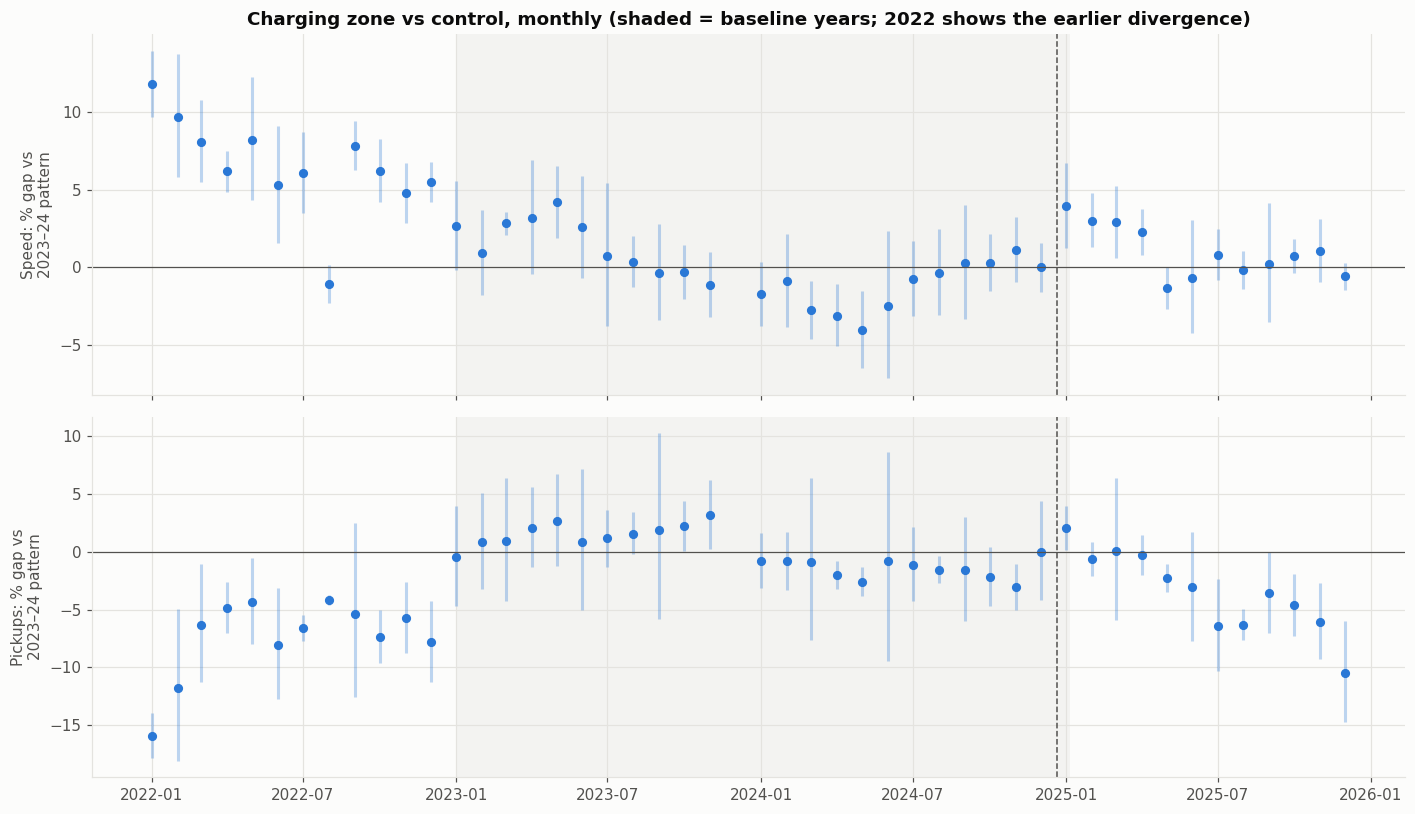

In [20]:
# Objective 1 robustness: later pre-periods, effect by half-year, and the full event study
#   The 2022–24 pre-period shows the charging zone diverging from the control (a failed parallel-trends test).
#   Here: (a) start the pre-period in 2023 or 2024 to drop the COVID-recovery years,
#         (b) split 2025 into January–June and July–December to see whether the effect faded,
#         (c) plot the monthly gap from 2022 so the pre-trend is visible.
SERIES = {"Speed, charging zone": gap_speed, "Pickups, charging zone": gap_trips,
          "Speed, buffer": gap_speed_buf, "Pickups, buffer": gap_trips_buf}
PRE_STARTS = [("2022-01-01", "2022–24"), ("2023-01-01", "2023–24"), ("2024-01-01", "2024 only")]
rows = []
for start, plab in PRE_STARTS:
    for name, gd in SERIES.items():
        d = gd[gd.pickup_date >= start]
        m = gap_did(d)
        row = {"Outcome": name, "Pre-period": plab, "Effect (%)": pct(m["b"]), "CI low": pct(m["lo"]),
               "CI high": pct(m["hi"]), "p": m["p"]}
        if start < "2024-01-01":          # trend and placebo need more than one pre-toll year
            t_ = gap_did(d, trend=True); s_, sp_ = pretrend(d)
            pl = gap_did(d, post_date=pd.Timestamp("2024-01-05"), end=TOLL_START - pd.Timedelta(days=1))
            row.update({"With linear trend (%)": pct(t_["b"]), "Pre-trend (pp/yr)": s_ * 100, "Pre-trend p": sp_,
                        "Placebo 2024 (%)": pct(pl["b"]), "Placebo p": pl["p"]})
        rows.append(row)
rob1 = pd.DataFrame(rows).set_index(["Outcome", "Pre-period"])
print("Table O1. Difference-in-differences under different pre-periods")
print("Read: an estimate is credible when its pre-trend and placebo are both close to 0 (p > 0.05).")
display(rob1.round(3)); rob1.round(4).to_csv(f"{TAB_DIR}/obj1_preperiod_robustness.csv")
for (name, plab), r_ in rob1.iterrows():
    record("1", f"{name}, pre-period {plab} (%)", r_["Effect (%)"], r_["CI low"], r_["CI high"], r_["p"],
           "" if pd.isna(r_.get("Placebo 2024 (%)", np.nan)) else
           f"pre-trend {r_['Pre-trend (pp/yr)']:.2f} pp/yr (p={r_['Pre-trend p']:.2g}); placebo {r_['Placebo 2024 (%)']:.1f}% (p={r_['Placebo p']:.2g})")

# (b) First vs second half of 2025
def did_halves(gd, start):
    d = gd[gd.pickup_date >= start].copy()
    d["h1"] = ((d.pickup_date >= TOLL_START) & (d.pickup_date < "2025-07-01")).astype(int)
    d["h2"] = (d.pickup_date >= "2025-07-01").astype(int)
    r = smf.ols(f"gap ~ h1 + h2 + {FE}", d).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
    ci = r.conf_int()
    return {"Jan–Jun 2025 (%)": pct(r.params["h1"]), "CI (Jan–Jun)": f"{pct(ci.loc['h1', 0]):.1f} to {pct(ci.loc['h1', 1]):.1f}",
            "Jul–Dec 2025 (%)": pct(r.params["h2"]), "CI (Jul–Dec)": f"{pct(ci.loc['h2', 0]):.1f} to {pct(ci.loc['h2', 1]):.1f}"}
halves = pd.DataFrame({(name, plab): did_halves(gd, start) for name, gd in SERIES.items()
                       for start, plab in PRE_STARTS[1:]}).T
halves.index.names = ["Outcome", "Pre-period"]
print("Table O2. Effect in the first vs second half of 2025")
display(halves.round(2)); halves.to_csv(f"{TAB_DIR}/obj1_halves.csv")

# (c) Event study across the whole period, baseline = 2023–24 pattern
def event_study_base(gd, base_start, before=TOLL_START, start="2022-01"):
    pre = gd[(gd.pickup_date >= base_start) & (gd.pickup_date < before)]
    r = smf.ols(f"gap ~ {FE}", pre).fit()
    d = gd.copy(); d["resid"] = d.gap - r.predict(d); d = d[d.ym >= start]
    es = smf.ols("resid ~ C(ym) - 1", d).fit(cov_type="HAC", cov_kwds={"maxlags": 14}); ci = es.conf_int()
    return pd.DataFrame({"ym": [k[6:-1] for k in es.params.index], "est": pct(es.params.values),
                         "lo": pct(ci[0].values), "hi": pct(ci[1].values)})
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for ax, (gd, lab) in zip(axes, [(gap_speed, "Speed"), (gap_trips, "Pickups")]):
    es = event_study_base(gd, "2023-01-01")
    x = pd.PeriodIndex(es.ym, freq="M").to_timestamp()
    ax.vlines(x, es.lo, es.hi, color=PAL["blue"], alpha=0.3, lw=2)
    ax.plot(x, es.est, "o", color=PAL["blue"], ms=5)
    ax.axvline(TOLL_START - pd.Timedelta(days=15), color=PAL["ink2"], ls="--", lw=1)
    ax.axvspan(pd.Timestamp("2023-01-01"), TOLL_START, color=PAL["grid"], alpha=0.35, lw=0)
    ax.axhline(0, color=PAL["ink2"], lw=0.8)
    ax.set_ylabel(f"{lab}: % gap vs\n2023–24 pattern")
axes[0].set_title("Charging zone vs control, monthly (shaded = baseline years; 2022 shows the earlier divergence)")
plt.tight_layout(); plt.show()

## 2. Mechanism: are speed gains concentrated in toll-peak hours?
The car toll is highest in the **peak period** (weekdays 5am–9pm, weekends 9am–9pm) and lower overnight. If the speed gain comes from
fewer private cars, it should be larger at peak.

Hourly gap for internal trips: `gap_{t,h} = log speed(charging) − log speed(control)` for date *t*, hour *h*.

`gap_{t,h} = β₁·post + β₂·post×peak + hour×weekend FE + month + holiday + ε`, clustered by week.

β₁ is the overnight effect; β₁ + β₂ is the peak effect; **β₂ > 0 supports the mechanism.**
Cells with fewer than `MIN_CELL_TRIPS` trips in either group are dropped.

In [21]:
def is_peak(hour, weekend):
    return np.where(weekend, (hour >= 9) & (hour < 21), (hour >= 5) & (hour < 21)).astype(int)

hh = ph[(ph.pu_grp == ph.do_grp) & ph.pu_grp.isin(["charging_zone", "control_manhattan"])]
hh = hh.groupby(["pickup_date", "hour", "weekend", "pu_grp"])[["trips", "dist", "dur"]].sum().reset_index()
w = hh.pivot_table(index=["pickup_date", "hour", "weekend"], columns="pu_grp", values=["trips", "dist", "dur"]).dropna()
ok = (w["trips"]["charging_zone"] >= MIN_CELL_TRIPS) & (w["trips"]["control_manhattan"] >= MIN_CELL_TRIPS)
w = w[ok]
hg = pd.DataFrame({"gap": np.log(w["dist"]["charging_zone"] / w["dur"]["charging_zone"])
                          - np.log(w["dist"]["control_manhattan"] / w["dur"]["control_manhattan"])}).reset_index()
hg = calendar(hg[~hg.pickup_date.isin(GAP_DAYS)])
hg["weekend"] = hg.weekend.astype(int)
hg["post"] = (hg.pickup_date >= TOLL_START).astype(int)
hg["peak"] = is_peak(hg.hour, hg.weekend.astype(bool))
hg["week"] = pd.factorize(hg.pickup_date.dt.to_period("W").astype(str))[0]
cover = hg.groupby(["hour", "weekend"]).post.agg(["sum", "count"])
good = cover[(cover["sum"] >= 20) & (cover["count"] - cover["sum"] >= 20)].index
hg = hg.set_index(["hour", "weekend"]).loc[lambda d: d.index.isin(good)].reset_index()
print("Hour-weekend cells with enough pre and post data:", len(good), "of 48")
hg["hw"] = hg.hour.astype(str) + "_" + hg.weekend.astype(str)
print(f"{len(hg):,} date-hour cells kept; dropped {(~ok).sum():,} sparse cells")

r = smf.ols("gap ~ post + post:peak + C(hw) + C(month) + hol", hg).fit(
    cov_type="cluster", cov_kwds={"groups": hg.week})
b1, b2 = r.params["post"], r.params["post:peak"]
V = r.cov_params().loc[["post", "post:peak"], ["post", "post:peak"]].values
se_peak = np.sqrt(V[0, 0] + V[1, 1] + 2 * V[0, 1])
print(f"Overnight effect (β1):           {pct(b1):6.2f}%  (p = {r.pvalues['post']:.3g})")
print(f"Peak effect (β1+β2):             {pct(b1+b2):6.2f}%  (95% CI {pct(b1+b2-1.96*se_peak):.2f} to {pct(b1+b2+1.96*se_peak):.2f})")
print(f"Peak minus overnight (β2):       {b2*100:6.2f} log points (p = {r.pvalues['post:peak']:.3g})")
ci2 = r.conf_int().loc["post:peak"]
record("2", "Speed effect, overnight (%)", pct(b1), *pct(r.conf_int().loc["post"].values), r.pvalues["post"])
record("2", "Speed effect, peak (%)", pct(b1 + b2), pct(b1 + b2 - 1.96 * se_peak), pct(b1 + b2 + 1.96 * se_peak))
record("2", "Peak minus overnight (log points ×100)", b2 * 100, ci2[0] * 100, ci2[1] * 100, r.pvalues["post:peak"])

# Placebo: same model with a fake toll on 5 Jan 2024, pre-toll data only
pl = hg[hg.pickup_date < TOLL_START].copy(); pl["post"] = (pl.pickup_date >= "2024-01-05").astype(int)
rp = smf.ols("gap ~ post + post:peak + C(hw) + C(month) + hol", pl).fit(
    cov_type="cluster", cov_kwds={"groups": pl.week})
print(f"Placebo (2024) peak-minus-overnight: {rp.params['post:peak']*100:.2f} log points (p = {rp.pvalues['post:peak']:.3g})")

# Robustness: pooled DiD from summed distance and time (no cell filter), all hours kept
hp = ph[(ph.pu_grp == ph.do_grp) & ph.pu_grp.isin(["charging_zone", "control_manhattan"])
        & ~ph.pickup_date.isin(GAP_DAYS)].copy()
hp["peak"] = is_peak(hp.hour, hp.weekend.astype(bool)); hp["post"] = hp.pickup_date >= TOLL_START
sp = hp.groupby(["peak", "post", "pu_grp"])[["dist", "dur"]].sum()
sp = np.log(sp.dist / sp.dur).unstack(); gp = (sp["charging_zone"] - sp["control_manhattan"]).unstack()
pooled = pct(gp[True] - gp[False])
print(f"Pooled check (no cell filter): overnight {pooled.loc[0]:.2f}%, peak {pooled.loc[1]:.2f}%")
record("2", "Pooled check: overnight / peak (%)", pooled.loc[1], note=f"overnight {pooled.loc[0]:.2f}%; no seasonality controls")

Hour-weekend cells with enough pre and post data: 46 of 48
29,449 date-hour cells kept; dropped 4,787 sparse cells
Overnight effect (β1):             1.39%  (p = 0.0301)
Peak effect (β1+β2):              -0.10%  (95% CI -1.29 to 1.10)
Peak minus overnight (β2):        -1.48 log points (p = 0.0666)
Placebo (2024) peak-minus-overnight: -3.51 log points (p = 0.00126)
Pooled check (no cell filter): overnight -2.03%, peak -1.96%


In [ ]:
# Hour-by-hour effect, weekdays
wd = hg[hg.weekend == 0].copy()
rh = smf.ols("gap ~ C(hour) + C(hour):post + C(month) + hol", wd).fit(cov_type="cluster", cov_kwds={"groups": wd.week})
ks = [k for k in rh.params.index if ":post" in k]
hour_eff = pd.DataFrame({"hour": [int(k.split("[")[1].split("]")[0].replace("T.", "")) for k in ks],
                         "est": pct(rh.params[ks].values), "lo": pct(rh.conf_int().loc[ks, 0].values),
                         "hi": pct(rh.conf_int().loc[ks, 1].values)}).sort_values("hour")

mta = None
if os.path.exists(MTA_ENTRIES_CSV):
    mta = pd.read_csv(MTA_ENTRIES_CSV)
    cols = {c.lower(): c for c in mta.columns}
    hcol = next((cols[c] for c in cols if "hour" in c and "of" in c), None) or next((cols[c] for c in cols if "hour" in c), None)
    ecol = next((cols[c] for c in cols if "entries" in c and "excluded" not in c), None)
    print("MTA columns used:", hcol, ecol)
    if hcol and ecol:
        hr = pd.to_datetime(mta[hcol], errors="coerce")
        mta["h"] = hr.dt.hour if hr.notna().mean() > 0.5 else pd.to_numeric(mta[hcol], errors="coerce")
        mta_h = mta.groupby("h")[ecol].sum(); mta_h = mta_h / mta_h.sum() * 100

n = 2 if mta is not None and "mta_h" in globals() else 1
fig, axes = plt.subplots(1, n, figsize=(6 * n, 4), squeeze=False)
ax = axes[0, 0]
peak_bg = [h for h in range(24) if 5 <= h < 21]
ax.axvspan(4.5, 20.5, color=PAL["grid"], alpha=0.5, lw=0)
ax.fill_between(hour_eff.hour, hour_eff.lo, hour_eff.hi, color=PAL["blue"], alpha=0.18, lw=0)
ax.plot(hour_eff.hour, hour_eff.est, "o-", color=PAL["blue"], ms=5)
ax.axhline(0, color=PAL["ink2"], lw=0.8)
ax.set_xlabel("Pickup hour (shaded = weekday toll peak)"); ax.set_ylabel("% speed effect (95% CI)")
ax.set_title("Weekday speed effect by hour")
ax.set_xticks(range(0, 24, 2))
if n == 2:
    ax2 = axes[0, 1]
    ax2.bar(mta_h.index, mta_h.values, color=PAL["muted"], width=0.8)
    ax2.set_xlabel("Hour"); ax2.set_ylabel("% of daily vehicle entries"); ax2.set_title("Vehicle entries into the zone (MTA)")
plt.tight_layout(); plt.show()

### 2b. Mechanism test allowing for pre-existing trends
The original specification's placebo fails, so peak and overnight hours are allowed to follow different trends.

Table O3. Peak vs overnight speed effects. The mechanism predicts Peak − overnight > 0;
a specification is credible when its placebo (fake toll in 2024) is close to 0.


Overnight (%)  Overnight p  Peak (%)      Peak CI  Peak − overnight (pp)      p  Placebo peak − overnight (pp)  \
Pre-period Model                                                                                                                                              
2022–24    No trends (original)                      1.393        0.030    -0.100  -1.3 to 1.1                 -1.484  0.067                         -3.506   
           Common trend                              7.600        0.000     5.878   4.2 to 7.6                 -1.613  0.047                         -3.563   
           Separate peak / overnight trends          3.482        0.003     7.559   5.6 to 9.5                  3.864  0.005                          1.463   
2023–24    No trends (original)                      2.022        0.004     1.850   0.6 to 3.1                 -0.169  0.852                         -2.393   
           Common trend                              5.679        0.000     5.481   3.2 to 7.8                 -0.188  0.835                         -2.422   
           Separate peak / overnight trends          2.262        0.142     6.884   4.4 to 9.4                  4.421  0.015                          2.616   

                                             Placebo p  
Pre-period Model                                        
2022–24    No trends (original)                  0.001  
           Common trend                          0.001  
           Separate peak / overnight trends      0.463  
2023–24    No trends (original)                  0.077  
           Common trend                          0.075  
           Separate peak / overnight trends      0.349

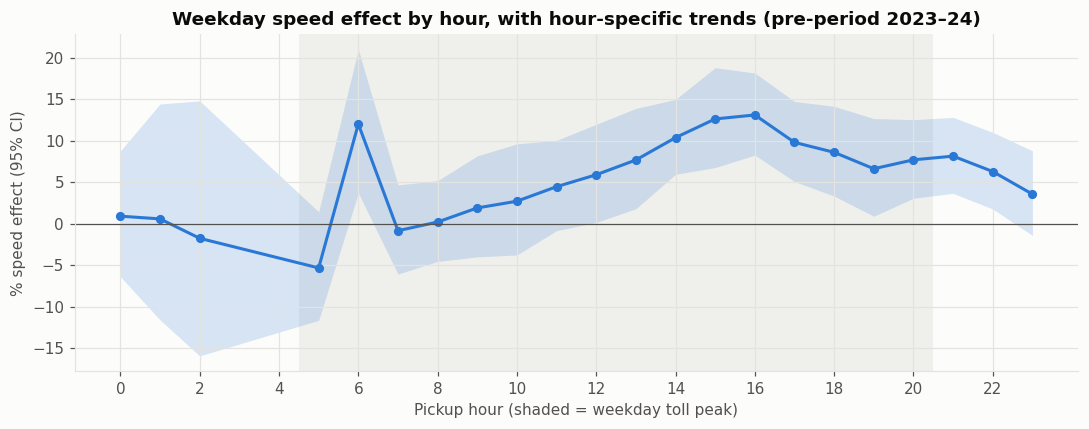

In [22]:
# Objective 2 with trends: does the speed gain differ between toll-peak and overnight hours,
#           once peak and overnight are allowed to follow different pre-existing trends?
SPECS2 = {
    "No trends (original)": "gap ~ post + post:peak + C(hw) + C(month) + hol",
    "Common trend": "gap ~ post + post:peak + C(hw) + C(month) + hol + t",
    "Separate peak / overnight trends": "gap ~ post + post:peak + C(hw) + C(month) + hol + t + t:peak",
}
rows = []
for start, plab in [("2022-01-01", "2022–24"), ("2023-01-01", "2023–24")]:
    d0 = hg[hg.pickup_date >= start].copy()
    pl0 = d0[d0.pickup_date < TOLL_START].copy(); pl0["post"] = (pl0.pickup_date >= "2024-01-05").astype(int)
    for name, f in SPECS2.items():
        r = smf.ols(f, d0).fit(cov_type="cluster", cov_kwds={"groups": d0.week})
        rp = smf.ols(f, pl0).fit(cov_type="cluster", cov_kwds={"groups": pl0.week})
        b1, b2 = r.params["post"], r.params["post:peak"]
        V = r.cov_params().loc[["post", "post:peak"], ["post", "post:peak"]].values
        se_pk = np.sqrt(V[0, 0] + V[1, 1] + 2 * V[0, 1])
        rows.append({"Pre-period": plab, "Model": name,
                     "Overnight (%)": pct(b1), "Overnight p": r.pvalues["post"],
                     "Peak (%)": pct(b1 + b2), "Peak CI": f"{pct(b1 + b2 - 1.96 * se_pk):.1f} to {pct(b1 + b2 + 1.96 * se_pk):.1f}",
                     "Peak − overnight (pp)": b2 * 100, "p": r.pvalues["post:peak"],
                     "Placebo peak − overnight (pp)": rp.params["post:peak"] * 100, "Placebo p": rp.pvalues["post:peak"]})
tab2 = pd.DataFrame(rows).set_index(["Pre-period", "Model"])
print("Table O3. Peak vs overnight speed effects. The mechanism predicts Peak − overnight > 0;")
print("a specification is credible when its placebo (fake toll in 2024) is close to 0.")
display(tab2.round(3)); tab2.round(4).to_csv(f"{TAB_DIR}/obj2_trend_robustness.csv")
for (plab, name), r_ in tab2.iterrows():
    record("2", f"Peak − overnight, {name}, pre {plab} (pp)", r_["Peak − overnight (pp)"], p=r_["p"],
           note=f"placebo {r_['Placebo peak − overnight (pp)']:.2f} pp (p={r_['Placebo p']:.2g})")

# Hour-by-hour weekday effects, allowing each hour its own trend (pre-period from 2023)
wd2 = hg[(hg.weekend == 0) & (hg.pickup_date >= "2023-01-01")].copy()
rh2 = smf.ols("gap ~ C(hour) + C(hour):post + C(hour):t + C(month) + hol", wd2).fit(
    cov_type="cluster", cov_kwds={"groups": wd2.week})
ks = [k for k in rh2.params.index if k.endswith(":post")]
he2 = pd.DataFrame({"hour": [int(k.split("[")[1].split("]")[0].replace("T.", "")) for k in ks],
                    "est": pct(rh2.params[ks].values), "lo": pct(rh2.conf_int().loc[ks, 0].values),
                    "hi": pct(rh2.conf_int().loc[ks, 1].values)}).sort_values("hour")
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(4.5, 20.5, color=PAL["grid"], alpha=0.5, lw=0)
ax.fill_between(he2.hour, he2.lo, he2.hi, color=PAL["blue"], alpha=0.18, lw=0)
ax.plot(he2.hour, he2.est, "o-", color=PAL["blue"], ms=5); ax.axhline(0, color=PAL["ink2"], lw=0.8)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Pickup hour (shaded = weekday toll peak)")
ax.set_ylabel("% speed effect (95% CI)"); ax.set_title("Weekday speed effect by hour, with hour-specific trends (pre-period 2023–24)")
plt.tight_layout(); plt.show()

## 3. Fare sensitivity: the December 2022 fare revision
All metered fares rose on 19 Dec 2022, but by different percentages for different trips (the base charge rose 20%, per-mile and
per-minute charges 40%, the weekday rush surcharge from \$1.00 to \$2.50, the overnight surcharge from \$0.50 to \$1.00, the JFK flat fare
from \$52 to \$70 — check against the TLC notice before citing).

**Design.** Trips are grouped into segments (distance band × time band, plus the JFK flat fare). For each segment the change in price
paid (fare + surcharges, from the `extra` column) and in trips is measured between **October–November** and **9 January–15 March**,
skipping December and its holidays. The **same calendar change one year later** (2023–24, no fare change) is subtracted, removing
segment-specific seasonality such as airport travel. The relative elasticity is the weighted slope of net Δtrips on net Δprice
across segments, with a week-block bootstrap. It measures how demand responds to *relative* price differences between trip types,
not the total fall in yellow-taxi demand.

Incomplete months (dropped entirely):


,key,rows_kept,in_files,missing
23,2023-12,3221392,2021173,1200219


77 files found, 1 unreadable, 75 used
  unreadable: 2023/cleaned_trips/year=2023/month=12/part-00023-537e7ab8-4005-4a89-947b-779fc99e5942.c000.snappy.parquet (0 bytes)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

panel_fare_segments2 built in 24s
Table O4. Changes by segment (Oct–Nov → 9 Jan–15 Mar). Net = actual minus the same calendar change a year later.


,"Δ price, actual (%)","Δ trips, actual (%)","Δ price, placebo (%)","Δ trips, placebo (%)",Net Δ price (pp),Net Δ trips (pp),Trips/day (pre)
segment,,,,,,,
JFK flat,34.08,-24.72,-0.07,-27.00,29.40,3.07,4493.51
d0-1 | day,23.44,4.30,-5.44,-0.30,26.65,4.51,11321.84
d0-1 | night,31.60,5.40,-2.60,-2.69,30.10,7.98,4283.47
d0-1 | rush,39.84,7.12,-6.80,-5.08,40.58,12.09,6033.90
d1-2 | day,25.84,-2.84,-5.54,-5.71,28.68,3.00,19025.11
d1-2 | night,32.25,-5.01,-3.17,-10.07,31.17,5.47,8918.98
d1-2 | rush,36.58,-1.77,-6.09,-7.11,37.46,5.59,10317.13
d10+ | day,43.24,-17.21,-2.05,-26.49,38.00,11.89,2455.00
d10+ | night,41.91,-13.81,-0.50,-18.67,35.51,5.79,1379.05


Placebo check: price change in the placebo year averages -4.6% (range -6.8 to -0.1%) — should be near 0, so the placebo isolates seasonality.
Table O5. Relative fare elasticity across segments (weighted by pre-period trips; 95% CI from week bootstrap)


,Elasticity,CI low,CI high
Net of placebo (main),0.387,0.036,0.804
Actual only (seasonality not removed),-0.697,-0.990,-0.340


Net price change by segment ranges 26.7 to 40.6 pp; the elasticity is identified from this spread. Correlation of net change in (fare+surcharge) vs fare only: 0.77.


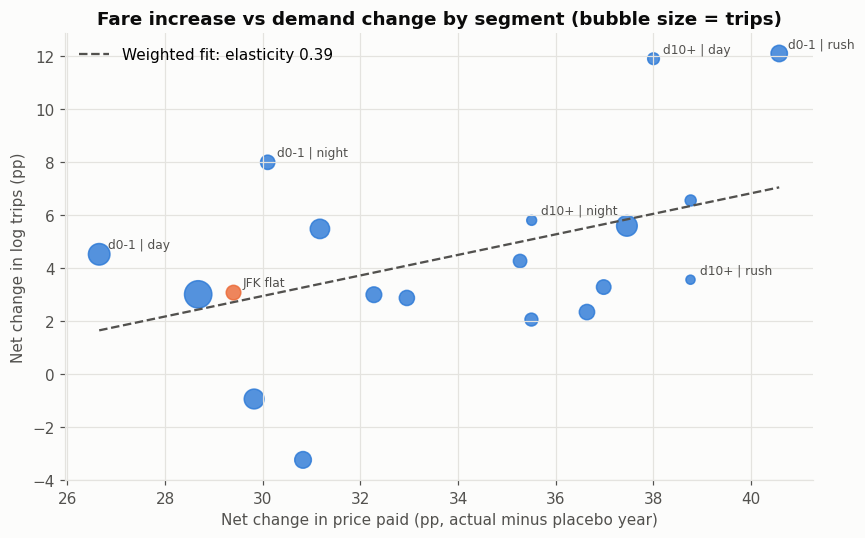

In [23]:
# Objective 3 redesigned: fare sensitivity with (a) the price passengers pay (fare + surcharges),
#           (b) windows that skip December (Oct–Nov vs 9 Jan–15 Mar), and (c) the same windows one year later
#           as a placebo, so segment-specific seasonality (e.g. airport travel) is netted out.
FS2 = f"{CACHE_DIR}/panel_fare_segments2.parquet"
if not os.path.exists(FS2):
    keep, _ = check_trip_files()
    flist = "[" + ", ".join("'" + f.replace("'", "''") + "'" for f in keep) + "]"
    t0 = time.time()
    duckdb.connect().execute(f"""COPY (
        SELECT CAST(pickup_date AS DATE) AS pickup_date,
               CASE WHEN CAST(ratecodeid AS INTEGER) = 2 THEN 'JFK flat'
                    ELSE (CASE WHEN trip_distance < 1 THEN 'd0-1' WHEN trip_distance < 2 THEN 'd1-2'
                               WHEN trip_distance < 3 THEN 'd2-3' WHEN trip_distance < 5 THEN 'd3-5'
                               WHEN trip_distance < 10 THEN 'd5-10' ELSE 'd10+' END) || ' | ' ||
                         (CASE WHEN NOT CAST(is_weekend AS BOOLEAN) AND pickup_hour BETWEEN 16 AND 19 THEN 'rush'
                               WHEN pickup_hour >= 20 OR pickup_hour < 6 THEN 'night' ELSE 'day' END) END AS segment,
               count(*) AS trips, avg(fare_amount) AS avg_fare,
               avg(fare_amount + coalesce(extra, 0)) AS avg_price, avg(trip_distance) AS avg_dist
        FROM read_parquet({flist}, hive_partitioning=true, union_by_name=true)
        WHERE NOT is_zero_fare AND CAST(ratecodeid AS INTEGER) IN (1, 2)
          AND CAST(pickup_date AS DATE) BETWEEN DATE '2022-09-01' AND DATE '2024-03-31'
        GROUP BY ALL) TO '{FS2}' (FORMAT parquet)""")
    print(f"panel_fare_segments2 built in {time.time() - t0:.0f}s")
pf2 = pd.read_parquet(FS2); pf2["pickup_date"] = pd.to_datetime(pf2.pickup_date)
pf2 = pf2[~pf2.pickup_date.isin(GAP_DAYS) & ~pf2.pickup_date.isin(HOLIDAYS)]

WINDOWS = {"Actual (2022–23)": (("2022-10-01", "2022-11-30"), ("2023-01-09", "2023-03-15")),
           "Placebo (2023–24)": (("2023-10-01", "2023-11-30"), ("2024-01-09", "2024-03-15"))}
def mats(a, b):
    d = pf2[(pf2.pickup_date >= a) & (pf2.pickup_date <= b)]
    T = d.pivot_table(index="pickup_date", columns="segment", values="trips", aggfunc="sum")
    R = d.assign(rev=d.trips * d.avg_price).pivot_table(index="pickup_date", columns="segment", values="rev", aggfunc="sum")
    F = d.assign(rev=d.trips * d.avg_fare).pivot_table(index="pickup_date", columns="segment", values="rev", aggfunc="sum")
    return T, R, F
M = {(w, side): mats(*WINDOWS[w][i]) for w in WINDOWS for i, side in enumerate(["pre", "post"])}
SEGS = sorted(set.intersection(*[set(m[0].columns) for m in M.values()]))

def deltas(idx=None):
    out = {}
    for w in WINDOWS:
        s = {}
        for side in ["pre", "post"]:
            T, R, F = M[(w, side)]
            if idx is not None: T, R, F = T.iloc[idx[(w, side)]], R.iloc[idx[(w, side)]], F.iloc[idx[(w, side)]]
            s[side] = (np.log(T[SEGS]).mean(), np.log(R[SEGS].sum() / T[SEGS].sum()), np.log(F[SEGS].sum() / T[SEGS].sum()))
        out[w] = tuple(s["post"][k] - s["pre"][k] for k in range(3))     # Δlog trips, Δlog price, Δlog fare
    return out
def slope(y, x, w):
    return np.polyfit(x, y, 1, w=np.sqrt(w))[0]

wts = M[("Actual (2022–23)", "pre")][0][SEGS].mean()
D = deltas()
(a_t, a_p, a_f), (p_t, p_p, p_f) = D["Actual (2022–23)"], D["Placebo (2023–24)"]
seg_tab = pd.DataFrame({"Δ price, actual (%)": pct(a_p), "Δ trips, actual (%)": pct(a_t),
                        "Δ price, placebo (%)": pct(p_p), "Δ trips, placebo (%)": pct(p_t),
                        "Net Δ price (pp)": (a_p - p_p) * 100, "Net Δ trips (pp)": (a_t - p_t) * 100,
                        "Trips/day (pre)": wts})
print("Table O4. Changes by segment (Oct–Nov → 9 Jan–15 Mar). Net = actual minus the same calendar change a year later.")
display(seg_tab.round(2)); seg_tab.round(3).to_csv(f"{TAB_DIR}/obj3_segments.csv")

# Bootstrap: resample weeks within each window
weeks = {k: pd.Series(range(len(v[0])), index=v[0].index).groupby(v[0].index.to_period("W")).apply(list).tolist() for k, v in M.items()}
rng = np.random.default_rng(0); bs = []
for _ in range(N_BOOT):
    idx = {k: [i for wk in rng.choice(len(w_), len(w_), replace=True) for i in w_[wk]] for k, w_ in weeks.items()}
    Db = deltas(idx); (bt, bp, bf), (pt, pp, pf_) = Db["Actual (2022–23)"], Db["Placebo (2023–24)"]
    bs.append([slope(bt - pt, bp - pp, wts), slope(bt, bp, wts)])
bs = np.array(bs)
est = [slope(a_t - p_t, a_p - p_p, wts), slope(a_t, a_p, wts)]
el = pd.DataFrame({"Elasticity": est, "CI low": np.percentile(bs, 2.5, axis=0), "CI high": np.percentile(bs, 97.5, axis=0)},
                  index=["Net of placebo (main)", "Actual only (seasonality not removed)"])
print(f"Placebo check: price change in the placebo year averages {np.average(pct(p_p), weights=wts):.1f}% "
      f"(range {pct(p_p).min():.1f} to {pct(p_p).max():.1f}%) — should be near 0, so the placebo isolates seasonality.")
fs_corr = np.corrcoef(a_p - p_p, a_f - p_f)[0, 1]
print("Table O5. Relative fare elasticity across segments (weighted by pre-period trips; 95% CI from week bootstrap)")
display(el.round(3)); el.round(4).to_csv(f"{TAB_DIR}/obj3_elasticity.csv")
print(f"Net price change by segment ranges {seg_tab['Net Δ price (pp)'].min():.1f} to {seg_tab['Net Δ price (pp)'].max():.1f} pp; "
      f"the elasticity is identified from this spread. Correlation of net change in (fare+surcharge) vs fare only: {fs_corr:.2f}.")
for nm, r_ in el.iterrows():
    if True:
        record("3", f"Relative fare elasticity (redesigned): {nm}", r_["Elasticity"], r_["CI low"], r_["CI high"])

fig, ax = plt.subplots(figsize=(8, 5))
x = seg_tab["Net Δ price (pp)"]; y = seg_tab["Net Δ trips (pp)"]
ax.scatter(x, y, s=20 + 300 * wts / wts.max(), color=[PAL["orange"] if s == "JFK flat" else PAL["blue"] for s in seg_tab.index], alpha=0.8)
xx = np.linspace(x.min(), x.max(), 50); b = np.polyfit(x, y, 1, w=np.sqrt(wts))
ax.plot(xx, b[0] * xx + b[1], color=PAL["ink2"], lw=1.5, ls="--", label=f"Weighted fit: elasticity {b[0]:.2f}")
for s in seg_tab.index:
    if s == "JFK flat" or s.startswith("d10") or s.startswith("d0-1"):
        ax.annotate(s, (x[s], y[s]), textcoords="offset points", xytext=(6, 4), fontsize=8, color=PAL["ink2"])
ax.set_xlabel("Net change in price paid (pp, actual minus placebo year)"); ax.set_ylabel("Net change in log trips (pp)")
ax.set_title("Fare increase vs demand change by segment (bubble size = trips)"); ax.legend(loc="best")
plt.tight_layout(); plt.show()

## 4. Machine-learning check
### 4a. Forecast counterfactual
A gradient-boosted model is trained on **pre-toll** zone-day data (calendar, weather and zone features only — no lagged outcomes, so the
forecast cannot learn from the post period). For 2025 it predicts what each zone would have done without the toll.

Effect = mean(log actual − log predicted) in the charging zone **minus** the same in control zones. Differencing removes forecast drift
common to both groups (tree models cannot extrapolate trends).

**Placebo:** train on 2022–2023, predict 2024 — the charging-minus-control difference should be ≈ 0.
Uncertainty: block bootstrap over weeks of the daily residual gap.

In [24]:
from sklearn.ensemble import HistGradientBoostingRegressor

zd = pzd.merge(zg.rename(columns={"LocationID": "zone_id"})[["zone_id", "grp"]], on="zone_id", how="left")
zd = zd[~zd.pickup_date.isin(GAP_DAYS)]
busy = zd[zd.pickup_date.dt.year == 2024].groupby("zone_id").trips.mean()
keep_zones = busy[busy >= 5].index
zd = zd[zd.zone_id.isin(keep_zones) & zd.grp.isin(["charging_zone", "control_manhattan"])].copy()
zd = calendar(zd).merge(wx[["pickup_date", "prcp_mm", "snow_mm", "tmax_c", "tmin_c"]], on="pickup_date", how="left")
zd["doy_s"] = np.sin(2 * np.pi * zd.pickup_date.dt.dayofyear / 365.25)
zd["doy_c"] = np.cos(2 * np.pi * zd.pickup_date.dt.dayofyear / 365.25)
zd["zone_code"] = zd.zone_id.astype("category").cat.codes
zd["y_trips"] = np.log(zd.trips)
zd["y_speed"] = np.log(zd.dist / zd.dur * 60)
# No time-trend feature: trees cannot extrapolate a trend, and including it caused drift in the placebo test
FEATS = ["zone_code", "dow", "month", "doy_s", "doy_c", "hol", "prcp_mm", "snow_mm", "tmax_c", "tmin_c"]

def ml_effect(target, train_end, test_start, test_end, seed=0):
    tr = zd[zd.pickup_date <= train_end].dropna(subset=[target])
    te = zd[(zd.pickup_date >= test_start) & (zd.pickup_date <= test_end)].dropna(subset=[target]).copy()
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, categorical_features=[0], random_state=seed)
    m.fit(tr[FEATS], tr[target])
    te["res"] = te[target] - m.predict(te[FEATS])
    daily = te.groupby(["pickup_date", "grp"]).apply(lambda g: np.average(g.res, weights=g.trips),
                                                     include_groups=False).unstack()
    gap = (daily["charging_zone"] - daily["control_manhattan"]).dropna()
    weeks = gap.index.to_period("W"); wk = gap.groupby(weeks).agg(["sum", "count"])
    rng = np.random.default_rng(seed); bs = []
    for _ in range(N_BOOT):
        s = wk.sample(len(wk), replace=True, random_state=rng.integers(1e9))
        bs.append(s["sum"].sum() / s["count"].sum())
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return dict(effect=pct(gap.mean()), lo=pct(lo), hi=pct(hi),
                charging=pct(daily["charging_zone"].mean()), control=pct(daily["control_manhattan"].mean()),
                raw=gap.mean(), bs=np.array(bs))

ml_rows = {}
for target, lab in [("y_speed", "speed"), ("y_trips", "pickups")]:
    a_ = ml_effect(target, "2024-12-31", TOLL_START, "2025-12-31")
    p_ = ml_effect(target, "2023-12-31", "2024-01-05", "2024-12-31")
    adj_bs = a_["bs"] - p_["bs"]
    adj = dict(effect=pct(a_["raw"] - p_["raw"]), lo=pct(np.percentile(adj_bs, 2.5)), hi=pct(np.percentile(adj_bs, 97.5)),
               charging=np.nan, control=np.nan)
    ml_rows[f"{lab}: toll (train ≤2024, test 2025)"] = a_
    ml_rows[f"{lab}: placebo (train ≤2023, test 2024)"] = p_
    ml_rows[f"{lab}: placebo-adjusted (toll − placebo)"] = adj
ml_tab = pd.DataFrame(ml_rows).T[["effect", "lo", "hi", "charging", "control"]].astype(float)
display(ml_tab.round(2))
print("A placebo far from 0 means the forecast drifts; the placebo-adjusted row removes that drift (assuming it is stable).")
for k, rr in ml_tab.iterrows():
    if "placebo" in k:
        record("4", f"ML forecast DiD, {k} (%)", rr.effect, rr.lo, rr.hi)

,effect,lo,hi,charging,control
"speed: toll (train ≤2024, test 2025)",-1.98,-2.56,-1.47,0.15,2.17
"speed: placebo (train ≤2023, test 2024)",-2.86,-3.47,-2.30,-4.73,-1.93
speed: placebo-adjusted (toll − placebo),0.90,0.12,1.63,NaN,NaN
"pickups: toll (train ≤2024, test 2025)",-3.11,-4.75,-1.24,14.49,18.17
"pickups: placebo (train ≤2023, test 2024)",2.25,0.87,3.67,6.25,3.91
pickups: placebo-adjusted (toll − placebo),-5.25,-7.08,-3.19,NaN,NaN


A placebo far from 0 means the forecast drifts; the placebo-adjusted row removes that drift (assuming it is stable).


### 4b. Zone clustering and matched controls
Zones are described by their 2024 (pre-toll) demand pattern: hourly profile on weekdays and weekends, volume, trip length, speed and
airport share. K-means groups similar zones; each charging-zone zone is then matched to its nearest non-charging zone in feature space,
and the DiD from Section 1 is re-estimated against this **matched control** instead of geography.

`MATCH_POOL = "manhattan"` restricts matches to the control zones; `"all"` allows any zone outside the charging zone and buffer
(outer-borough zones grew fast before the toll — check the pre-trend if you use it).

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
MATCH_POOL = "manhattan"

prof = pzp.pivot_table(index="zone_id", columns=["weekend", "hour"], values="trips", aggfunc="sum", fill_value=0)
prof = prof.div(prof.sum(axis=1), axis=0); prof.columns = [f"{'we' if w_ else 'wd'}_{h:02d}" for w_, h in prof.columns]
z24 = pzd[pzd.pickup_date.dt.year == 2024].groupby("zone_id").agg(
    trips=("trips", "sum"), dist=("dist", "sum"), dur=("dur", "sum"), n_air=("n_airport", "sum"), days=("pickup_date", "nunique"))
z24 = z24[z24.trips / 366 >= 20]
feat = pd.DataFrame({"log_daily": np.log(z24.trips / 366), "mean_miles": z24.dist / z24.trips,
                     "speed": z24.dist / z24.dur * 60, "airport_share": z24.n_air / z24.trips}).join(prof, how="inner")
X = StandardScaler().fit_transform(feat)
Xp = PCA(n_components=min(6, X.shape[1], X.shape[0] - 1), random_state=0).fit_transform(X)
scores = {k: silhouette_score(Xp, KMeans(k, n_init=10, random_state=0).fit_predict(Xp)) for k in range(3, min(9, len(feat)))}
K = max(scores, key=scores.get)
feat["cluster"] = KMeans(K, n_init=10, random_state=0).fit_predict(Xp)
feat = feat.join(zg.set_index("LocationID")[["grp"]])
print(f"Chosen k = {K} (silhouette {scores[K]:.2f})")
display(pd.crosstab(feat.cluster, feat.grp))

treat_idx = np.where(feat.grp == "charging_zone")[0]
pool_mask = (feat.grp == "control_manhattan") if MATCH_POOL == "manhattan" else ~feat.grp.isin(["charging_zone", "buffer", "excluded_island"])
pool_idx = np.where(pool_mask)[0]
dist = ((Xp[treat_idx, None, :] - Xp[None, pool_idx, :]) ** 2).sum(-1)
match = pd.Series(feat.index[pool_idx[dist.argmin(1)]]).value_counts()
print(f"{len(treat_idx)} charging zones matched to {len(match)} distinct control zones; most used: {match.head(5).to_dict()}")

# Matched-control DiD: control series = match-weighted zone-day totals
mz = pzd[pzd.zone_id.isin(match.index)].copy(); mz["w"] = mz.zone_id.map(match)
mc = mz.assign(trips=mz.trips * mz.w, dist=mz.dist * mz.w, dur=mz.dur * mz.w).groupby("pickup_date")[["trips", "dist", "dur"]].sum()
tz = pzd[pzd.zone_id.isin(feat.index[treat_idx])].groupby("pickup_date")[["trips", "dist", "dur"]].sum()
gm = pd.concat([tz.assign(pu_grp="charging_zone"), mc.assign(pu_grp="matched_control")]).reset_index()
gm["speed"] = gm.dist / gm.dur * 60
print("\n=== Matched control: speed of pickups (all destinations) ===")
did_report(make_gap(gm, "charging_zone", "matched_control", "speed"), "Speed vs matched control (%)", obj="4")
print("\n=== Matched control: pickups ===")
did_report(make_gap(gm, "charging_zone", "matched_control", "trips"), "Pickups vs matched control (%)", obj="4")

Chosen k = 4 (silhouette 0.32)


grp,buffer,charging_zone,control_manhattan,outside_manhattan
cluster,,,,
0,0,9,0,8
1,0,0,0,13
2,0,1,4,22
3,6,28,12,5


38 charging zones matched to 7 distinct control zones; most used: {263: 22, 166: 9, 152: 3, 151: 1, 116: 1}

=== Matched control: speed of pickups (all destinations) ===
Speed vs matched control (%): pre-period trend in gap = -1.47 log-points/yr (p = 3.86e-06)


,effect_%,ci_lo_%,ci_hi_%,p,n
Main (post 5 Jan 2025),-0.388,-1.292,0.525,0.404,1425.0
With linear group trend,2.606,1.069,4.167,0.001,1425.0
Placebo: toll on 5 Jan 2024 (pre data only),-1.560,-2.668,-0.439,0.006,1064.0



=== Matched control: pickups ===
Pickups vs matched control (%): pre-period trend in gap = 6.86 log-points/yr (p = 4.31e-37)


,effect_%,ci_lo_%,ci_hi_%,p,n
Main (post 5 Jan 2025),6.027,3.870,8.230,0.0,1425.0
With linear group trend,-7.487,-9.818,-5.096,0.0,1425.0
Placebo: toll on 5 Jan 2024 (pre data only),7.791,5.284,10.357,0.0,1064.0


,b,lo,hi,p,n,effect_%,ci_lo_%,ci_hi_%
Main (post 5 Jan 2025),0.058525,0.037966,0.079084,2.412968e-08,1425.0,6.027156,3.869610,8.229517
With linear group trend,-0.077819,-0.103335,-0.052303,2.264815e-09,1425.0,-7.486841,-9.817533,-5.095915
Placebo: toll on 5 Jan 2024 (pre data only),0.075024,0.051495,0.098552,4.113813e-10,1064.0,7.790981,5.284439,10.357197


### 4c. Model evaluation
Forecast accuracy on held-out 2024 data against naive baselines, feature importance, robustness of the policy estimate to the
algorithm, and interpretation of the zone clusters.

Test set: 18,204 zone-days in 2024 (trained on 38,168 zone-days, 2022–2023)


RMSE (log)  MAE (log)  MAPE (%)     R²  Fit time (s)
Target  Model                                                                                      
Pickups Baseline: same day last year                0.330      0.209    27.682  0.948         0.000
        Baseline: zone × weekday × month mean       0.283      0.192    23.043  0.962         0.000
        Gradient boosting                           0.275      0.186    22.340  0.964         2.543
        Random forest                               0.276      0.186    22.334  0.964        40.439
        Ridge regression                            0.329      0.235    28.146  0.948         0.409
Speed   Baseline: same day last year                0.172      0.115    11.708  0.246         0.000
        Baseline: zone × weekday × month mean       0.129      0.091     8.675  0.575         0.000
        Gradient boosting                           0.120      0.082     7.815  0.635         3.460
        Random forest                               0.122      0.085     8.082  0.618        31.203
        Ridge regression                            0.122      0.085     8.118  0.620         0.081

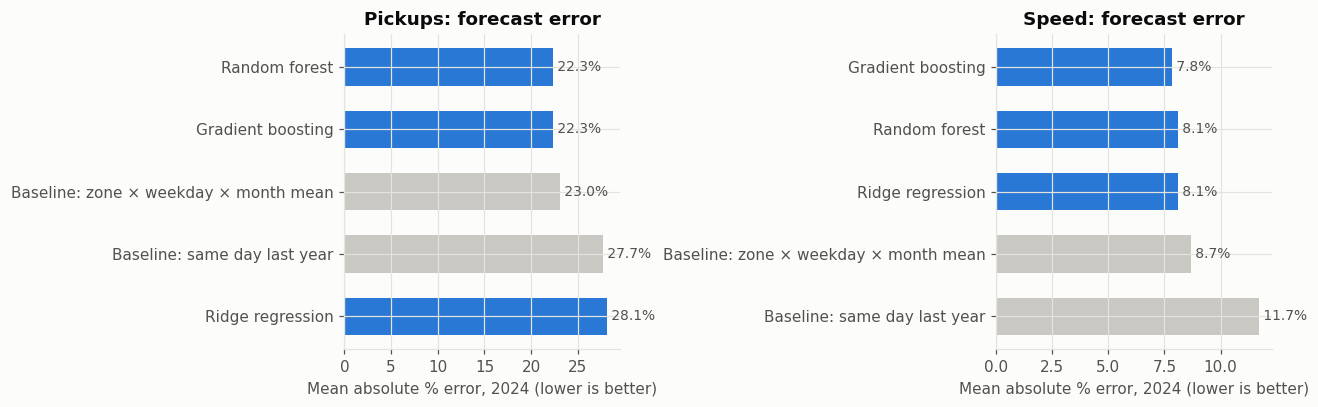

In [26]:
# Forecast accuracy on held-out data: three models vs two naive baselines
#           Train on 2022–2023, test on 2024 (a year with no policy change)
import time
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

CAT = ["zone_code", "dow", "month", "hol"]
NUM = ["doy_s", "doy_c", "prcp_mm", "snow_mm", "tmax_c", "tmin_c"]
MODELS = {
    "Gradient boosting": lambda: HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05,
                                                               categorical_features=[0], random_state=0),
    "Random forest": lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "Ridge regression": lambda: make_pipeline(
        ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), NUM)]),
        Ridge(alpha=1.0)),
}

tr_ = zd[zd.pickup_date <= "2023-12-31"].copy()
te_ = zd[(zd.pickup_date >= "2024-01-01") & (zd.pickup_date <= "2024-12-31")].copy()

# Baseline 1: same zone, same weekday, one year earlier (364 days)
lag = zd[["zone_id", "pickup_date", "y_trips", "y_speed"]].copy()
lag["pickup_date"] = lag.pickup_date + pd.Timedelta(days=364)
te_ = te_.merge(lag.rename(columns={"y_trips": "naive_y_trips", "y_speed": "naive_y_speed"}),
                on=["zone_id", "pickup_date"], how="left")
# Baseline 2: average for the same zone x weekday x month in the training years
for t in ["y_trips", "y_speed"]:
    avg = tr_.groupby(["zone_id", "dow", "month"])[t].mean().rename(f"avg_{t}")
    te_ = te_.merge(avg, left_on=["zone_id", "dow", "month"], right_index=True, how="left")
te_ = te_.dropna(subset=["naive_y_trips", "naive_y_speed", "avg_y_trips", "avg_y_speed"])   # common sample

def metrics(y, p):
    e = y - p
    return {"RMSE (log)": np.sqrt(np.mean(e ** 2)), "MAE (log)": np.mean(np.abs(e)),
            "MAPE (%)": np.mean(np.abs(np.exp(e) - 1)) * 100, "R²": 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)}

acc_rows, FITTED = [], {}
for target, lab in [("y_trips", "Pickups"), ("y_speed", "Speed")]:
    acc_rows.append({"Target": lab, "Model": "Baseline: same day last year", **metrics(te_[target], te_[f"naive_{target}"]), "Fit time (s)": 0})
    acc_rows.append({"Target": lab, "Model": "Baseline: zone × weekday × month mean", **metrics(te_[target], te_[f"avg_{target}"]), "Fit time (s)": 0})
    for name, make in MODELS.items():
        t0 = time.time(); m = make().fit(tr_[FEATS], tr_[target]); ft = time.time() - t0
        FITTED[(target, name)] = m
        acc_rows.append({"Target": lab, "Model": name, **metrics(te_[target], m.predict(te_[FEATS])), "Fit time (s)": ft})
acc = pd.DataFrame(acc_rows).set_index(["Target", "Model"])
print(f"Test set: {len(te_):,} zone-days in 2024 (trained on {len(tr_):,} zone-days, 2022–2023)")
display(acc.round(3))
acc.round(4).to_csv(f"{TAB_DIR}/ml_forecast_accuracy.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, lab in zip(axes, ["Pickups", "Speed"]):
    a = acc.loc[lab, "MAPE (%)"].sort_values()
    cols = [PAL["muted"] if n.startswith("Baseline") else PAL["blue"] for n in a.index]
    ax.barh(range(len(a)), a.values, color=cols, height=0.6)
    ax.set_yticks(range(len(a)), a.index); ax.invert_yaxis()
    for i, v in enumerate(a.values): ax.text(v, i, f" {v:.1f}%", va="center", fontsize=9, color=PAL["ink2"])
    ax.set_xlabel("Mean absolute % error, 2024 (lower is better)"); ax.set_title(f"{lab}: forecast error")
plt.tight_layout(); plt.show()

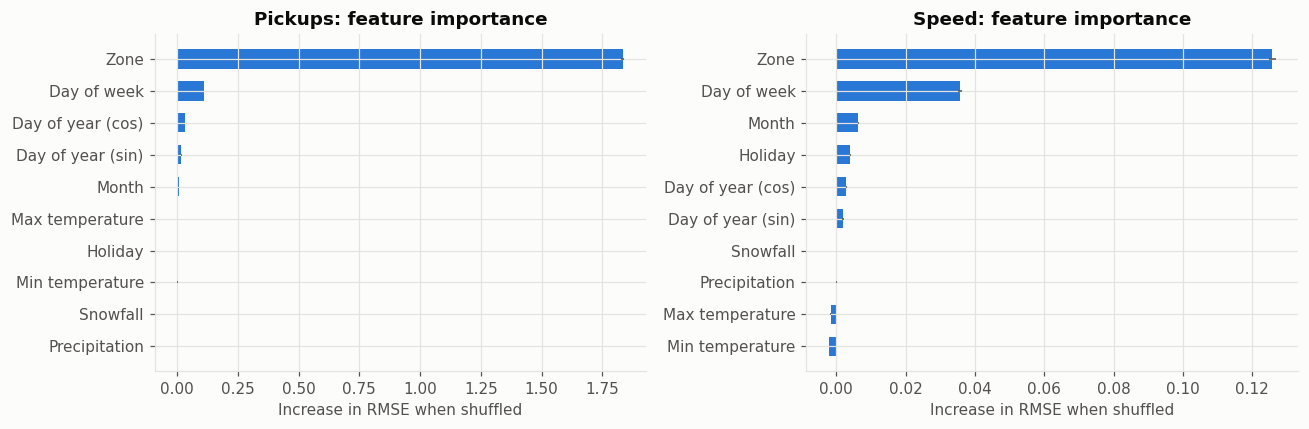

Zone and calendar features should dominate; weather adds little at the daily level (consistent with Chunk 12).


In [27]:
# Which inputs drive the forecast? Permutation importance on the 2024 test set
from sklearn.inspection import permutation_importance
NICE = {"zone_code": "Zone", "dow": "Day of week", "month": "Month", "doy_s": "Day of year (sin)",
        "doy_c": "Day of year (cos)", "hol": "Holiday", "prcp_mm": "Precipitation", "snow_mm": "Snowfall",
        "tmax_c": "Max temperature", "tmin_c": "Min temperature"}
sample = te_.sample(min(len(te_), 20000), random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
imp_tabs = {}
for ax, (target, lab) in zip(axes, [("y_trips", "Pickups"), ("y_speed", "Speed")]):
    pi = permutation_importance(FITTED[(target, "Gradient boosting")], sample[FEATS], sample[target],
                                n_repeats=5, random_state=0, scoring="neg_root_mean_squared_error")
    imp = pd.DataFrame({"importance": pi.importances_mean, "sd": pi.importances_std}, index=[NICE[f] for f in FEATS])
    imp = imp.sort_values("importance"); imp_tabs[lab] = imp
    ax.barh(imp.index, imp.importance, xerr=imp.sd, color=PAL["blue"], height=0.6, error_kw={"ecolor": PAL["ink2"], "lw": 1})
    ax.set_xlabel("Increase in RMSE when shuffled"); ax.set_title(f"{lab}: feature importance")
plt.tight_layout(); plt.show()
pd.concat(imp_tabs, axis=1).round(4).to_csv(f"{TAB_DIR}/ml_feature_importance.csv")
print("Zone and calendar features should dominate; weather adds little at the daily level (consistent with Chunk 12).")

Toll effect (%)  Placebo 2024 (%)  Placebo-adjusted (%)  CI low  CI high
Outcome Model                                                                                      
Speed   Gradient boosting            -1.98             -2.86                  0.90    0.12     1.63
        Random forest                -1.86             -2.95                  1.12    0.42     1.89
        Ridge regression             -2.26             -3.34                  1.12    0.37     1.78
Pickups Gradient boosting            -3.11              2.25                 -5.25   -7.08    -3.19
        Random forest                -2.73              2.23                 -4.85   -6.70    -2.94
        Ridge regression             -1.35              4.07                 -5.21   -6.91    -3.67

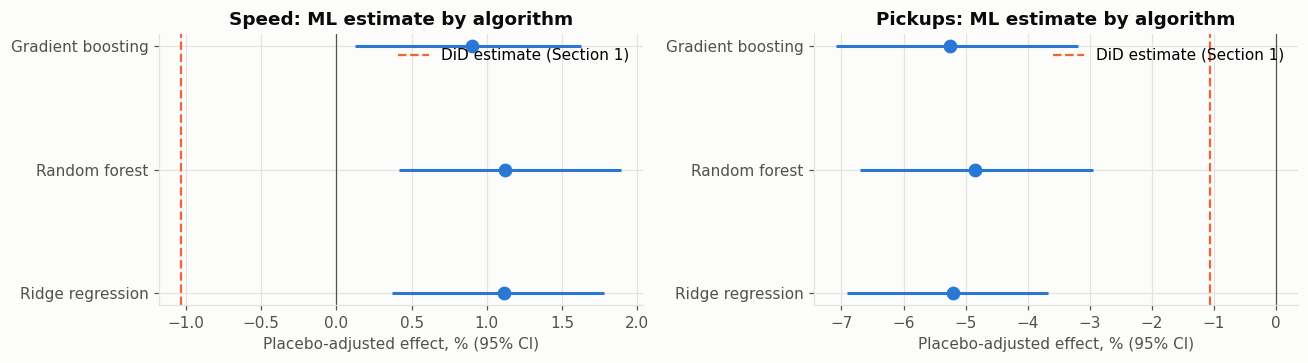

In [28]:
# Is the ML policy estimate robust to the choice of algorithm?
#           Same counterfactual design as Section 4a, run with all three models
def ml_effect_model(make, target, train_end, test_start, test_end, seed=0):
    tr = zd[zd.pickup_date <= train_end]
    te = zd[(zd.pickup_date >= test_start) & (zd.pickup_date <= test_end)].copy()
    m = make().fit(tr[FEATS], tr[target])
    te["res"] = te[target] - m.predict(te[FEATS])
    daily = te.groupby(["pickup_date", "grp"]).apply(lambda g: np.average(g.res, weights=g.trips),
                                                     include_groups=False).unstack()
    gap = (daily["charging_zone"] - daily["control_manhattan"]).dropna()
    wk = gap.groupby(gap.index.to_period("W")).agg(["sum", "count"])
    rng = np.random.default_rng(seed)
    bs = [(lambda s: s["sum"].sum() / s["count"].sum())(wk.sample(len(wk), replace=True, random_state=rng.integers(1e9)))
          for _ in range(N_BOOT)]
    return gap.mean(), np.array(bs)

rob = []
for target, lab in [("y_speed", "Speed"), ("y_trips", "Pickups")]:
    for name, make in MODELS.items():
        a_, a_bs = ml_effect_model(make, target, "2024-12-31", TOLL_START, "2025-12-31")
        p_, p_bs = ml_effect_model(make, target, "2023-12-31", "2024-01-05", "2024-12-31")
        adj = a_bs - p_bs
        rob.append({"Outcome": lab, "Model": name, "Toll effect (%)": pct(a_), "Placebo 2024 (%)": pct(p_),
                    "Placebo-adjusted (%)": pct(a_ - p_), "CI low": pct(np.percentile(adj, 2.5)),
                    "CI high": pct(np.percentile(adj, 97.5))})
        record("4", f"ML placebo-adjusted, {lab}, {name} (%)", pct(a_ - p_),
               pct(np.percentile(adj, 2.5)), pct(np.percentile(adj, 97.5)))
rob = pd.DataFrame(rob).set_index(["Outcome", "Model"])
display(rob.round(2)); rob.round(3).to_csv(f"{TAB_DIR}/ml_algorithm_robustness.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, lab in zip(axes, ["Speed", "Pickups"]):
    r_ = rob.loc[lab]
    y_ = np.arange(len(r_))
    ax.errorbar(r_["Placebo-adjusted (%)"], y_, xerr=[r_["Placebo-adjusted (%)"] - r_["CI low"], r_["CI high"] - r_["Placebo-adjusted (%)"]],
                fmt="o", color=PAL["blue"], ms=8, lw=2)
    ax.axvline(0, color=PAL["ink2"], lw=0.8)
    if "t_speed" in globals() and lab == "Speed":
        ax.axvline(t_speed.loc["Main (post 5 Jan 2025)", "effect_%"], color=PAL["orange"], ls="--", lw=1.5, label="DiD estimate (Section 1)")
        ax.legend(loc="best")
    if "t_trips" in globals() and lab == "Pickups":
        ax.axvline(t_trips.loc["Main (post 5 Jan 2025)", "effect_%"], color=PAL["orange"], ls="--", lw=1.5, label="DiD estimate (Section 1)")
        ax.legend(loc="best")
    ax.set_yticks(y_, r_.index); ax.invert_yaxis(); ax.set_xlabel("Placebo-adjusted effect, % (95% CI)")
    ax.set_title(f"{lab}: ML estimate by algorithm")
plt.tight_layout(); plt.show()

Cluster profiles (2024). Name each cluster from these, e.g. 'Midtown business', 'Nightlife', 'Residential', 'Airport'.


,Zones,Charging-zone zones,Median pickups/day,Mean trip miles,Mean speed (mph),Airport drop-offs (%),Weekend share (%),Night share (%),Weekday 7–10am (%),Weekday 4–8pm (%),Busiest zones
cluster,,,,,,,,,,,
0,17,9,161.8,4.1,11.9,2.2,47.5,48.0,5.6,9.8,"Clinton East, West Village, East Village"
1,13,0,29.6,6.2,10.4,2.4,28.0,12.8,23.4,7.1,"Crown Heights North, East New York, Prospect-L..."
2,28,1,34.3,6.1,14.0,5.8,34.0,22.9,13.4,11.9,"JFK Airport, Stuy Town/Peter Cooper Village, C..."
3,52,28,1470.6,3.2,10.6,2.5,27.9,14.5,9.7,20.0,"Upper East Side South, Midtown Center, Upper E..."


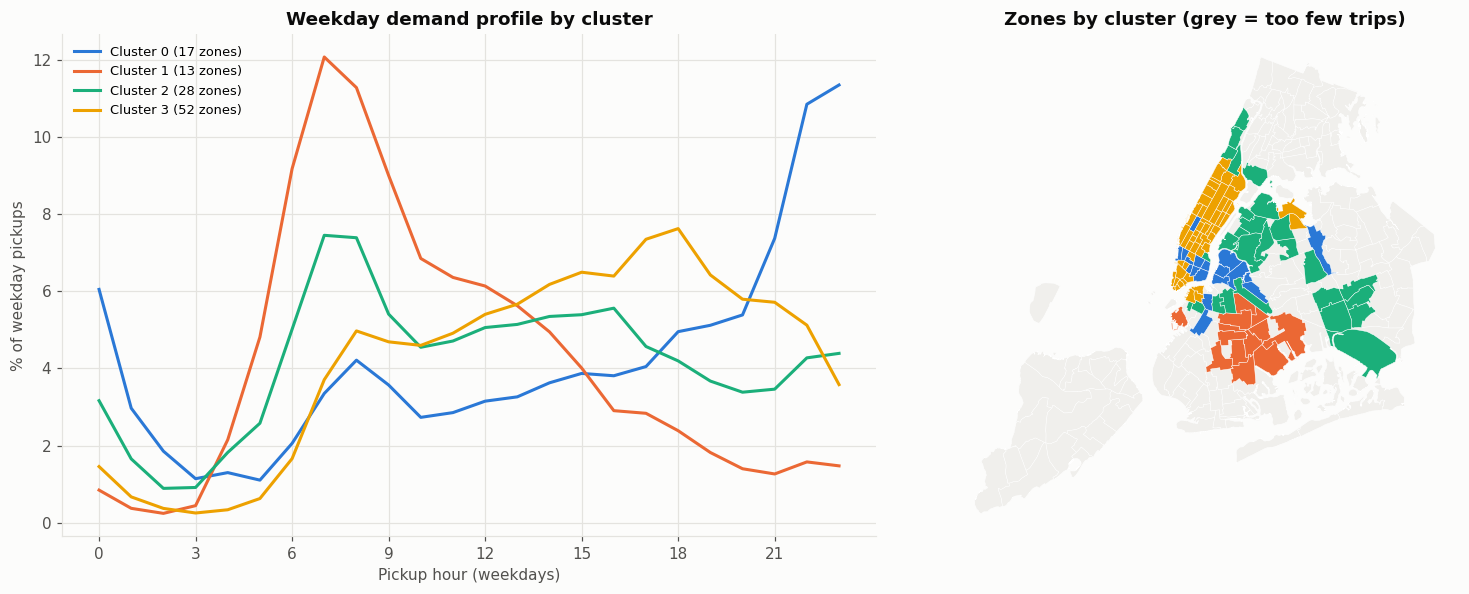

In [29]:
# What do the zone clusters mean? Profiles, hourly patterns and a map
import geopandas as gpd
wd_cols = [c for c in feat.columns if c.startswith("wd_")]; we_cols = [c for c in feat.columns if c.startswith("we_")]
night = [c for c in wd_cols + we_cols if int(c[-2:]) in (22, 23, 0, 1, 2, 3, 4, 5)]
am = [c for c in wd_cols if 7 <= int(c[-2:]) <= 9]; pm = [c for c in wd_cols if 16 <= int(c[-2:]) <= 19]
names = zg.set_index("LocationID")["zone"] if "zone" in zg.columns else pd.Series(dtype=str)
prof_tab = feat.assign(trips_day=np.exp(feat.log_daily),
                       weekend_share=feat[we_cols].sum(axis=1) * 100, night_share=feat[night].sum(axis=1) * 100,
                       am_peak=feat[am].sum(axis=1) * 100, pm_peak=feat[pm].sum(axis=1) * 100,
                       charging=(feat.grp == "charging_zone"))
ctab = prof_tab.groupby("cluster").agg(**{
    "Zones": ("trips_day", "size"), "Charging-zone zones": ("charging", "sum"),
    "Median pickups/day": ("trips_day", "median"), "Mean trip miles": ("mean_miles", "mean"),
    "Mean speed (mph)": ("speed", "mean"), "Airport drop-offs (%)": ("airport_share", lambda x: x.mean() * 100),
    "Weekend share (%)": ("weekend_share", "mean"), "Night share (%)": ("night_share", "mean"),
    "Weekday 7–10am (%)": ("am_peak", "mean"), "Weekday 4–8pm (%)": ("pm_peak", "mean")})
if len(names):
    ctab["Busiest zones"] = [", ".join(names.reindex(prof_tab[prof_tab.cluster == k].nlargest(3, "trips_day").index).fillna("?"))
                             for k in ctab.index]
print("Cluster profiles (2024). Name each cluster from these, e.g. 'Midtown business', 'Nightlife', 'Residential', 'Airport'.")
display(ctab.round(1)); ctab.round(2).to_csv(f"{TAB_DIR}/cluster_profiles.csv")

CL_COL = [PAL["blue"], PAL["orange"], PAL["aqua"], PAL["yellow"], PAL["magenta"], PAL["green"], PAL["violet"], PAL["red"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
for k in sorted(feat.cluster.unique()):
    shares = feat.loc[feat.cluster == k, wd_cols]
    shares = shares.div(shares.sum(axis=1), axis=0).mean() * 100
    axes[0].plot(range(24), shares.values, color=CL_COL[k % 8], label=f"Cluster {k} ({(feat.cluster == k).sum()} zones)")
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_xlabel("Pickup hour (weekdays)"); axes[0].set_ylabel("% of weekday pickups")
axes[0].set_title("Weekday demand profile by cluster"); axes[0].legend(loc="upper left", fontsize=8.5)
zmap = zgeo if "zgeo" in globals() else gpd.read_file(ZONE_SHP)
cm_ = zmap.merge(feat[["cluster"]], left_on="LocationID", right_index=True, how="left")
cm_.plot(ax=axes[1], color="#f0efec", edgecolor="white", linewidth=0.3)
for k in sorted(feat.cluster.unique()):
    cm_[cm_.cluster == k].plot(ax=axes[1], color=CL_COL[k % 8], edgecolor="white", linewidth=0.3)
axes[1].set_axis_off(); axes[1].set_title("Zones by cluster (grey = too few trips)")
plt.tight_layout(); plt.show()

## 5. Results table and lessons for Indian cities
The table collects every headline estimate. Use it to fill the policy discussion; each lesson should name the estimate it rests on and
the condition under which it would transfer.

| Lesson to test | Evidence | Transfer condition for Indian cities |
|---|---|---|
| A cordon charge on private cars can speed up the vehicles that remain | Obj 1 speed, Obj 4 checks | Enforcement on all vehicle types (ANPR coverage of two-wheelers and autos); alternatives to driving exist |
| Gains are largest when the charge is highest | Obj 2 peak vs overnight | Time-varying charges are administratively feasible |
| Small per-trip fees on taxis change demand little | Obj 1 pickups (given $0.75 passenger fee) | App-based fares already vary hourly; a fixed fee is small relative to surge |
| Metered demand responds to price differences across trip types | Obj 3 relative elasticity | Fare caps (e.g. surge limits for aggregators) shift demand between trip types rather than only reducing it |
| Evaluation needs trip-level data with full coverage | Section A audit | Data-sharing rules for aggregators and meters |

In [30]:
res = pd.DataFrame(RESULTS)
res["value"] = res.value.astype(float)
display(res.round(3))
res.to_csv(f"{CACHE_DIR}/results_summary.csv", index=False)
print("Saved", f"{CACHE_DIR}/results_summary.csv")

,objective,estimate,value,ci_low,ci_high,p,note
0,R,OLS (7): Precipitation (cm) effect on trips (%),0.188,-0.499,0.880,0.592,
1,R,OLS (7): Snowfall (cm) effect on trips (%),-2.617,-4.785,-0.398,0.021,
2,R,OLS (7): Snow depth (cm) effect on trips (%),-0.949,-1.638,-0.256,0.007,
3,R,OLS (7): Public holiday effect on trips (%),-18.372,-23.401,-13.011,0.000,
4,1,"Speed, charging zone vs control (%)",-1.031,-2.205,0.157,0.089,pre-trend -3.82 lp/yr (p=1.9e-24); placebo -5.1%
5,1,"Pickups, charging zone vs control (%)",-1.071,-2.921,0.814,0.264,pre-trend 3.24 lp/yr (p=4.7e-08); placebo 1.9%
6,1,"Speed, buffer vs control (%)",-2.300,-3.330,-1.259,0.000,pre-trend -2.06 lp/yr (p=2.9e-07); placebo -3.0%
7,1,"Pickups, buffer vs control (%)",-7.500,-8.686,-6.299,0.000,pre-trend 0.07 lp/yr (p=0.85); placebo -2.1%
8,1,"Speed, charging zone, pre-period 2022–24 (%)",-1.031,-2.205,0.157,0.089,pre-trend -3.82 pp/yr (p=1.9e-24); placebo -5....
9,1,"Pickups, charging zone, pre-period 2022–24 (%)",-1.071,-2.921,0.814,0.264,pre-trend 3.24 pp/yr (p=4.7e-08); placebo 1.9%...


Saved /content/drive/MyDrive/BigData Project/panels/results_summary.csv


## 6. Big-data engineering with Spark (optional)
Spark MLlib on trip-level data: a travel-time model used as a further estimate of the speed effect; vendor KPIs computed with both Spark
and DuckDB (engine timing); a fare regression comparing the setup in Rhouas & El Hami (2025) with a pre-trip model, each solved by
normal equations and L-BFGS; and a scalability test. Spark here runs on one machine (`local[*]`); the code is unchanged on a cluster.

**Trip-level travel-time model (Spark GBT).** Trained on 2024 trips, used to estimate the 2025 speed effect net of the pre-toll gap.

Machine RAM 14 GB -> Spark driver memory 5 GB
Incomplete months (dropped entirely):


,key,rows_kept,in_files,missing
23,2023-12,3221392,2021173,1200219


77 files found, 1 unreadable, 75 used
  unreadable: 2023/cleaned_trips/year=2023/month=12/part-00023-537e7ab8-4005-4a89-947b-779fc99e5942.c000.snappy.parquet (0 bytes)
Loaded 784,739 sampled 2024 trips and 876,967 sampled 2025 trips in 71s


,RMSE,MAE,R2,Train time (s)
Model,,,,
GBT (Spark MLlib),0.3307,0.2294,0.8141,644.1994
Linear regression (Spark MLlib),0.4257,0.3140,0.6921,14.5397


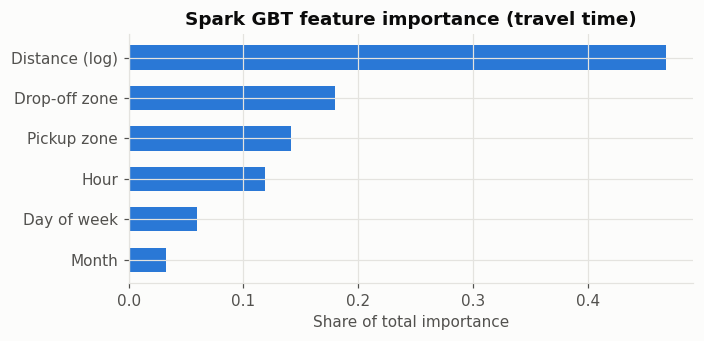

Pre-toll gap (2024 held-out trips): 1.07%  — should be close to 0
Trip-level speed effect (Spark GBT, charging zone vs control, net of 2024 gap): 2.4%  (95% CI 0.9 to 4.1)
Positive = trips inside the charging zone became faster than the model predicts, relative to control trips.


In [31]:
# Distributed ML with Spark MLlib on trip-level data
#   A travel-time model trained on a sample of 2024 trips, used to predict 2025 trips.
#   If 2025 trips inside the charging zone take less time than predicted, relative to control trips,
#   that is a trip-level, distributed estimate of the speed effect.
import subprocess, sys, os, re
def java_major():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        return int(re.search(r'version "(\d+)', out).group(1))
    except Exception:
        return 0
if java_major() < 17:      # recent PySpark needs Java 17+
    subprocess.run("apt-get -qq install -y openjdk-17-jre-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.regression import GBTRegressor, LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

SAMPLE = float(os.environ.get("TAXI_SPARK_SAMPLE", 0.02))   # 2% of trips per year; raise if you have more RAM/time
import gc; gc.collect()
total_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
drv_gb = max(2, min(8, int(total_gb * 0.4)))          # leave room for the Python side of the notebook
print(f"Machine RAM {total_gb:.0f} GB -> Spark driver memory {drv_gb} GB")
spark = (SparkSession.builder.master("local[*]").appName("taxi-mllib")
         .config("spark.driver.memory", f"{drv_gb}g").config("spark.sql.shuffle.partitions", "16")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

files = check_trip_files()[0] if "check_trip_files" in globals() else \
    [f for f in glob.glob(PARQUET_GLOB, recursive=True) if os.path.getsize(f) > 0]
def year_files(y):
    return [f for f in files if f"year={y}/" in f or f"out_{y}/" in f]
grp_sdf = spark.createDataFrame(zg[["LocationID", "grp"]].astype({"LocationID": int}))
def load(y):
    d = (spark.read.parquet(*year_files(y))
         .select(F.col("pickup_date").cast("date").alias("pickup_date"), F.col("pickup_hour").cast("int").alias("hour"),
                 F.col("pulocationid").cast("int").alias("pu"), F.col("dolocationid").cast("int").alias("do"),
                 F.col("trip_distance").cast("double").alias("dist"), F.col("trip_duration_min").cast("double").alias("dur"))
         .sample(fraction=SAMPLE, seed=42)
         .where((F.col("dist") > 0) & (F.col("dur") > 0)))
    d = (d.join(grp_sdf.withColumnRenamed("LocationID", "pu").withColumnRenamed("grp", "pu_grp"), "pu", "left")
          .join(grp_sdf.withColumnRenamed("LocationID", "do").withColumnRenamed("grp", "do_grp"), "do", "left")
          .fillna({"pu_grp": "other", "do_grp": "other"})
          .withColumn("dow", F.dayofweek("pickup_date")).withColumn("month", F.month("pickup_date"))
          .withColumn("log_dist", F.log("dist")).withColumn("log_dur", F.log("dur"))
          .withColumn("pu_s", F.col("pu").cast("string")).withColumn("do_s", F.col("do").cast("string")))
    return d
t0 = time.time()
d24, d25 = load(2024).cache(), load(2025).cache()
n24, n25 = d24.count(), d25.count()
print(f"Loaded {n24:,} sampled 2024 trips and {n25:,} sampled 2025 trips in {time.time() - t0:.0f}s")

idx = [StringIndexer(inputCol=c, outputCol=c + "_i", handleInvalid="keep") for c in ["pu_s", "do_s"]]
asm = VectorAssembler(inputCols=["log_dist", "hour", "dow", "month", "pu_s_i", "do_s_i"], outputCol="features")
gbt = GBTRegressor(labelCol="log_dur", featuresCol="features", maxIter=60, maxDepth=6, maxBins=300, seed=0)
lin = LinearRegression(labelCol="log_dur", featuresCol="features")
train, test = d24.randomSplit([0.8, 0.2], seed=1)
ev = {m: RegressionEvaluator(labelCol="log_dur", predictionCol="prediction", metricName=m) for m in ["rmse", "mae", "r2"]}
spark_rows, pipes = [], {}
for name, est in [("GBT (Spark MLlib)", gbt), ("Linear regression (Spark MLlib)", lin)]:
    t0 = time.time(); pm = Pipeline(stages=idx + [asm, est]).fit(train); ft = time.time() - t0
    pipes[name] = pm; pr = pm.transform(test)
    spark_rows.append({"Model": name, **{k.upper(): e.evaluate(pr) for k, e in ev.items()}, "Train time (s)": ft})
display(pd.DataFrame(spark_rows).set_index("Model").round(4))

fi = pd.Series(pipes["GBT (Spark MLlib)"].stages[-1].featureImportances.toArray(),
               index=["Distance (log)", "Hour", "Day of week", "Month", "Pickup zone", "Drop-off zone"]).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(fi.index, fi.values, color=PAL["blue"], height=0.6); ax.set_title("Spark GBT feature importance (travel time)")
ax.set_xlabel("Share of total importance")
plt.tight_layout(); plt.show()

# Counterfactual: trips that stay within one group; residual = actual − predicted log duration.
# The 2024 held-out trips give the pre-toll gap between groups, which is subtracted (like a placebo year).
def daily_gap(df):
    r = (pipes["GBT (Spark MLlib)"].transform(df.where(F.col("pu_grp") == F.col("do_grp")))
         .where(F.col("pu_grp").isin("charging_zone", "control_manhattan"))
         .withColumn("res", F.col("log_dur") - F.col("prediction"))
         .groupBy("pickup_date", "pu_grp").agg(F.mean("res").alias("res")).toPandas())
    w = r.pivot(index="pickup_date", columns="pu_grp", values="res").dropna()
    g = w["charging_zone"] - w["control_manhattan"]; g.index = pd.to_datetime(g.index)
    return g
gap24 = daily_gap(test)
gap25 = daily_gap(d25); gap25 = gap25[gap25.index >= TOLL_START]
def wk_boot(g, seed):
    wk = g.groupby(g.index.to_period("W")).agg(["sum", "count"]); rng = np.random.default_rng(seed)
    return np.array([(lambda s: s["sum"].sum() / s["count"].sum())(wk.sample(len(wk), replace=True, random_state=rng.integers(1e9)))
                     for _ in range(N_BOOT)])
bs = wk_boot(gap25, 0) - wk_boot(gap24, 1)
eff = -pct(gap25.mean() - gap24.mean())
lo, hi = -pct(np.percentile(bs, 97.5)), -pct(np.percentile(bs, 2.5))
print(f"Pre-toll gap (2024 held-out trips): {-pct(gap24.mean()):.2f}%  — should be close to 0")
print(f"Trip-level speed effect (Spark GBT, charging zone vs control, net of 2024 gap): {eff:.1f}%  (95% CI {lo:.1f} to {hi:.1f})")
print("Positive = trips inside the charging zone became faster than the model predicts, relative to control trips.")
record("4", "Spark MLlib trip-level speed effect (%)", eff, lo, hi, note=f"{SAMPLE:.0%} sample; net of 2024 gap")
d24.unpersist(); d25.unpersist(); spark.stop()

**Spark session, vendor KPIs and engine timing.** VendorID identifies the meter/payment technology provider, not a fleet.

Spark 4.0.4, local[*] with 2 cores, driver memory 5 GB
Incomplete months (dropped entirely):


,key,rows_kept,in_files,missing
23,2023-12,3221392,2021173,1200219


77 files found, 1 unreadable, 75 used
  unreadable: 2023/cleaned_trips/year=2023/month=12/part-00023-537e7ab8-4005-4a89-947b-779fc99e5942.c000.snappy.parquet (0 bytes)
Vendor column: vendorid


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Same KPI query over 154,669,633 trips; results match: True


,seconds
"DuckDB, cold (first read)",87.2
"Spark, warm",72.1
"DuckDB, warm",22.0


Vendor KPIs by year. VendorID identifies the meter/payment technology provider, not a taxi fleet.


Trips  Mean miles  Mean minutes  Mean fare ($)  Mean total ($)  Card payments (%)  Card tip (% of fare)  Passenger count missing (%)  \
year vendor                                                                                                                                            
2022 1       10263798        3.33         15.70          14.07           20.70              77.49                 22.91                         2.16   
     2       27756250        3.64         18.13          15.03           22.05              76.54                 23.68                         3.65   
     6          33132       10.97         64.32          51.99           52.78               0.00                   NaN                       100.00   
2023 1        8250535        3.31         16.43          18.56           27.27              79.83                 21.67                         2.36   
     2       25127496        3.63         17.91          20.18           29.49              79.73                 22.49                         2.63   
     6           5116       11.68         66.37          49.86           50.68               0.00                   NaN                       100.00   
2024 1        9029308        3.27         17.75          18.76           27.11              77.28                 20.72                         8.17   
     2       30285704        3.47         17.61          20.14           29.12              75.58                 22.46                         9.76   
     6           1194       12.09         63.41          34.25           47.66               0.00                   NaN                       100.00   
2025 1        9181326        3.51         19.09          19.44           27.65              72.28                 19.10                        16.86   
     2       34713293        3.48         17.22          20.20           29.17              67.66                 22.72                        20.95   
     6          22338        8.91         41.28           3.07           32.32               0.00                   NaN                       100.00   

             Share of year's trips (%)  
year vendor                             
2022 1                           26.97  
     2                           72.94  
     6                            0.09  
2023 1                           24.71  
     2                           75.27  
     6                            0.02  
2024 1                           22.97  
     2                           77.03  
     6                            0.00  
2025 1                           20.91  
     2                           79.04  
     6                            0.05

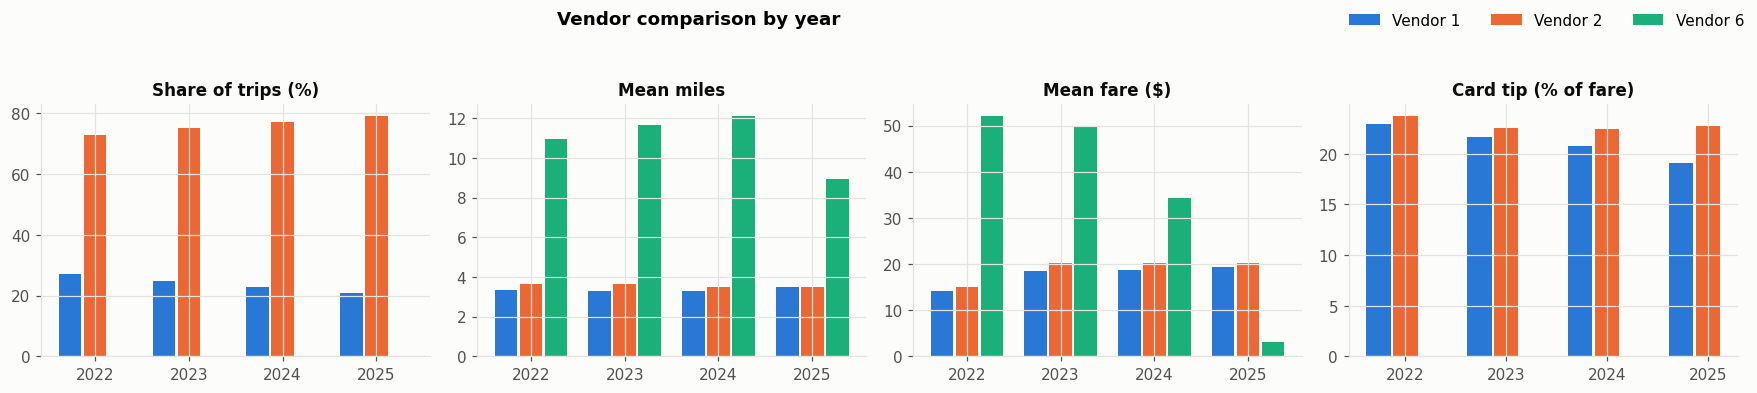

In [32]:
# Spark setup + vendor KPIs by year, computed with both Spark and DuckDB (engine timing comparison)
import subprocess, sys, os, re, time, gc
def java_major():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        return int(re.search(r'version "(\d+)', out).group(1))
    except Exception:
        return 0
if java_major() < 17:      # recent PySpark needs Java 17+
    subprocess.run("apt-get -qq install -y openjdk-17-jre-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
from pyspark.sql import SparkSession, functions as F

def get_spark():
    gc.collect()
    total_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
    drv_gb = max(2, min(8, int(total_gb * 0.4)))
    s = (SparkSession.builder.master("local[*]").appName("taxi-bigdata")
         .config("spark.driver.memory", f"{drv_gb}g").config("spark.sql.shuffle.partitions", "16")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
    s.sparkContext.setLogLevel("ERROR")
    print(f"Spark {s.version}, local[*] with {os.cpu_count()} cores, driver memory {drv_gb} GB")
    return s
spark = get_spark()

TRIP_FILES = check_trip_files()[0] if "check_trip_files" in globals() else \
    [f for f in glob.glob(PARQUET_GLOB, recursive=True) if os.path.getsize(f) > 0]
def year_files(y):
    return [f for f in TRIP_FILES if f"year={y}/" in f or f"out_{y}/" in f]
trips_sdf = spark.read.parquet(*TRIP_FILES)
VENDOR = next((c for c in trips_sdf.columns if c.lower() == "vendorid"), None)
print("Vendor column:", VENDOR or "NOT FOUND — vendor table skipped")

if VENDOR:
    flist = "[" + ", ".join("'" + f.replace("'", "''") + "'" for f in TRIP_FILES) + "]"
    DUCK_SQL = f"""
        SELECT year(CAST(pickup_date AS DATE)) AS year, CAST({VENDOR} AS INTEGER) AS vendor, count(*) AS trips,
               avg(trip_distance) AS mean_miles, avg(trip_duration_min) AS mean_minutes,
               avg(CASE WHEN NOT is_zero_fare THEN fare_amount END) AS mean_fare, avg(total_amount) AS mean_total,
               avg(CASE WHEN CAST(payment_type AS INTEGER) = 1 THEN 1 ELSE 0 END) AS card_share,
               sum(CASE WHEN CAST(payment_type AS INTEGER) = 1 THEN tip_amount END)
                 / sum(CASE WHEN CAST(payment_type AS INTEGER) = 1 THEN fare_amount END) AS card_tip_pct,
               avg(CASE WHEN passenger_count IS NULL THEN 1 ELSE 0 END) AS passenger_missing
        FROM read_parquet({flist}, hive_partitioning=true, union_by_name=true) GROUP BY ALL ORDER BY 1, 2"""
    def run_duck():
        return duckdb.connect().execute(DUCK_SQL).df()
    def run_spark():
        return (trips_sdf.withColumn("year", F.year(F.col("pickup_date").cast("date")))
                .groupBy("year", F.col(VENDOR).cast("int").alias("vendor"))
                .agg(F.count("*").alias("trips"), F.avg("trip_distance").alias("mean_miles"),
                     F.avg("trip_duration_min").alias("mean_minutes"),
                     F.avg(F.when(~F.col("is_zero_fare"), F.col("fare_amount"))).alias("mean_fare"),
                     F.avg("total_amount").alias("mean_total"),
                     F.avg(F.when(F.col("payment_type").cast("int") == 1, 1).otherwise(0)).alias("card_share"),
                     (F.sum(F.when(F.col("payment_type").cast("int") == 1, F.col("tip_amount")))
                      / F.sum(F.when(F.col("payment_type").cast("int") == 1, F.col("fare_amount")))).alias("card_tip_pct"),
                     F.avg(F.col("passenger_count").isNull().cast("int")).alias("passenger_missing"))
                .orderBy("year", "vendor").toPandas())
    # Same query on both engines. The first run reads files from disk ("cold"); later runs hit the OS file cache ("warm").
    t0 = time.time(); v_duck = run_duck(); t_duck_cold = time.time() - t0
    t0 = time.time(); v_spark = run_spark(); t_spark = time.time() - t0
    t0 = time.time(); v_duck = run_duck(); t_duck_warm = time.time() - t0
    same = (v_duck.trips.sum() == v_spark.trips.sum()) and np.allclose(v_duck.mean_fare, v_spark.mean_fare)
    timing = pd.Series({"DuckDB, cold (first read)": t_duck_cold, "Spark, warm": t_spark, "DuckDB, warm": t_duck_warm},
                       name="seconds")
    print(f"Same KPI query over {v_spark.trips.sum():,} trips; results match: {same}")
    display(timing.round(1).to_frame())
    timing.round(2).to_csv(f"{TAB_DIR}/engine_timing.csv")
    for k_, v_ in timing.items():
        record("A", f"Engine timing: {k_} (s)", v_)
    v = v_spark.copy()
    v["share_of_year_%"] = v.trips / v.groupby("year").trips.transform("sum") * 100
    v["card_share"] *= 100; v["card_tip_pct"] *= 100; v["passenger_missing"] *= 100
    v = v[v.trips >= 1000]          # drop rare/invalid vendor codes
    vt = v.set_index(["year", "vendor"]).rename(columns={
        "trips": "Trips", "share_of_year_%": "Share of year's trips (%)", "mean_miles": "Mean miles",
        "mean_minutes": "Mean minutes", "mean_fare": "Mean fare ($)", "mean_total": "Mean total ($)",
        "card_share": "Card payments (%)", "card_tip_pct": "Card tip (% of fare)", "passenger_missing": "Passenger count missing (%)"})
    print("Vendor KPIs by year. VendorID identifies the meter/payment technology provider, not a taxi fleet.")
    display(vt.round(2)); vt.round(3).to_csv(f"{TAB_DIR}/vendor_kpis_by_year.csv")

    kp = [("Share of year's trips (%)", "Share of trips (%)"), ("Mean miles", "Mean miles"),
          ("Mean fare ($)", "Mean fare ($)"), ("Card tip (% of fare)", "Card tip (% of fare)")]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
    vend = sorted(v.vendor.unique()); vcol = [PAL["blue"], PAL["orange"], PAL["aqua"], PAL["yellow"]]
    yrs = sorted(v.year.unique()); w = 0.8 / len(vend)
    for ax, (col, lab) in zip(axes, kp):
        for i, vv in enumerate(vend):
            s_ = vt.xs(vv, level="vendor")[col].reindex(yrs)
            ax.bar(np.arange(len(yrs)) + (i - (len(vend) - 1) / 2) * w, s_.values, width=w * 0.9, color=vcol[i % 4], label=f"Vendor {vv}")
        ax.set_xticks(range(len(yrs)), yrs); ax.set_title(lab, fontsize=11)
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="upper right", ncol=len(vend), frameon=False)
    fig.suptitle("Vendor comparison by year", fontweight="bold", x=0.4); plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

**Fare regression in Spark MLlib.** The paper's setup (total ~ fare + tip + …) versus a pre-trip fare model, each with two solvers.

In [33]:
# Fare regression in Spark MLlib: the paper's setup vs a proper pre-trip model,
#           each solved two ways (exact normal equations vs iterative L-BFGS)
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

FARE_YEAR, FARE_SAMPLE = 2024, float(os.environ.get("TAXI_FARE_SAMPLE", 0.05))
fd = (spark.read.parquet(*year_files(FARE_YEAR))
      .select(F.col("fare_amount").cast("double").alias("fare"), F.col("total_amount").cast("double").alias("total"),
              F.col("tip_amount").cast("double").alias("tip"), F.col("passenger_count").cast("double").alias("pax"),
              F.col("trip_distance").cast("double").alias("dist"), F.col("pickup_hour").cast("int").alias("hour"),
              F.dayofweek(F.col("pickup_date").cast("date")).alias("dow"),
              F.col("pulocationid").cast("string").alias("pu"), F.col("dolocationid").cast("string").alias("do"),
              F.col("ratecodeid").cast("int").cast("string").alias("rate"), F.col("is_zero_fare"))
      .where(~F.col("is_zero_fare") & (F.col("dist") > 0))
      .fillna({"pax": 1.0, "rate": "unknown"})
      .sample(fraction=FARE_SAMPLE, seed=7)
      .withColumn("hour_s", F.col("hour").cast("string")).withColumn("dow_s", F.col("dow").cast("string")))
train_f, test_f = fd.randomSplit([0.8, 0.2], seed=3)
train_f, test_f = train_f.cache(), test_f.cache()
n_tr, n_te = train_f.count(), test_f.count()
print(f"{FARE_YEAR} sample: {n_tr:,} training and {n_te:,} test trips ({FARE_SAMPLE:.0%} of non-zero-fare trips)")

cats = ["pu", "do", "rate", "hour_s", "dow_s"]
pre_stages = ([StringIndexer(inputCol=c, outputCol=c + "_i", handleInvalid="keep") for c in cats] +
              [OneHotEncoder(inputCols=[c + "_i" for c in cats], outputCols=[c + "_oh" for c in cats], handleInvalid="keep")])
SPECS = {
    "Paper's setup: total ~ fare + tip + distance + passengers":
        dict(label="total", stages=[VectorAssembler(inputCols=["pax", "dist", "fare", "tip"], outputCol="features")]),
    "Pre-trip model: fare ~ distance + zones + rate code + hour + weekday":
        dict(label="fare", stages=pre_stages + [VectorAssembler(inputCols=["dist"] + [c + "_oh" for c in cats], outputCol="features")]),
}
# Spark may print "LBFGS: Line search zoom failed": harmless — the optimiser has already converged (common on near-perfect fits)
rows, fitted = [], {}
for spec, cfg in SPECS.items():
    for solver in ["normal", "l-bfgs"]:
        lr = LinearRegression(labelCol=cfg["label"], featuresCol="features", solver=solver, maxIter=100, regParam=0.0)
        t0 = time.time(); m = Pipeline(stages=cfg["stages"] + [lr]).fit(train_f); ft = time.time() - t0
        pr = m.transform(test_f)
        ev = lambda metric: RegressionEvaluator(labelCol=cfg["label"], predictionCol="prediction", metricName=metric).evaluate(pr)
        summ = m.stages[-1].summary
        rows.append({"Model": spec, "Solver": "Normal equations (OLS)" if solver == "normal" else "L-BFGS",
                     "Features": m.stages[-1].numFeatures, "RMSE ($)": ev("rmse"), "MAE ($)": ev("mae"), "R²": ev("r2"),
                     "Train time (s)": ft, "Iterations": summ.totalIterations if solver != "normal" else 1})
        fitted[(spec, solver)] = m
ftab = pd.DataFrame(rows).set_index(["Model", "Solver"])
display(ftab.round(4)); ftab.round(4).to_csv(f"{TAB_DIR}/fare_regression_spark.csv")

paper = list(SPECS)[0]
coef = pd.Series(fitted[(paper, "normal")].stages[-1].coefficients.toArray(), index=["Passengers", "Distance", "Fare", "Tip"])
coef["Intercept"] = fitted[(paper, "normal")].stages[-1].intercept
print("Paper's setup, OLS coefficients:"); display(coef.round(4).to_frame("coefficient"))
print("Fare and tip coefficients near 1 and an intercept near the fixed surcharges: the model rebuilds the bill "
      "(total = fare + tip + fees) rather than explaining prices. The pre-trip model is the meaningful one.")
pre = list(SPECS)[1]
dist_coef = fitted[(pre, "normal")].stages[-1].coefficients.toArray()[0]
print(f"Pre-trip model: each extra mile adds ${dist_coef:.2f} to the fare, holding zones, rate code and time fixed.")
for spec in SPECS:
    for solver in ["normal", "l-bfgs"]:
        r_ = ftab.loc[(spec, "Normal equations (OLS)" if solver == "normal" else "L-BFGS")]
        record("A", f"Spark fare model [{spec.split(':')[0]}, {solver}] RMSE ($)", r_["RMSE ($)"], note=f"R² {r_['R²']:.3f}, {r_['Train time (s)']:.1f}s")

2024 sample: 1,571,272 training and 393,026 test trips (5% of non-zero-fare trips)


Features  RMSE ($)  MAE ($)      R²  Train time (s)  Iterations
Model                                              Solver                                                                                 
Paper's setup: total ~ fare + tip + distance + ... Normal equations (OLS)         4    2.5000   1.4885  0.9875          8.4292           1
                                                   L-BFGS                         4    2.5000   1.4885  0.9875         19.9857          11
Pre-trip model: fare ~ distance + zones + rate ... Normal equations (OLS)       559    5.3842   3.0412  0.9072         38.1376           1
                                                   L-BFGS                       559    5.3842   3.0412  0.9072         55.5817          27

Paper's setup, OLS coefficients:


,coefficient
Passengers,0.0947
Distance,0.3296
Fare,0.9932
Tip,1.2156
Intercept,3.6039


Fare and tip coefficients near 1 and an intercept near the fixed surcharges: the model rebuilds the bill (total = fare + tip + fees) rather than explaining prices. The pre-trip model is the meaningful one.
Pre-trip model: each extra mile adds $3.58 to the fare, holding zones, rate code and time fixed.


**Scalability.** Training time as data size grows, for both solvers.

  0.5% sample: 196,778 rows done
  1.0% sample: 392,988 rows done
  2.0% sample: 786,158 rows done
  5.0% sample: 1,964,625 rows done
  10.0% sample: 3,931,024 rows done


RMSE ($)                        Train time (s)                       
Solver    L-BFGS Normal equations (OLS)         L-BFGS Normal equations (OLS)
Rows                                                                         
196778     5.402                  5.402         10.260                  2.391
392988     5.405                  5.405          9.791                  1.795
786158     5.401                  5.401         11.663                  4.176
1964625    5.412                  5.412         23.020                  4.823
3931024    5.451                  5.451         42.124                 10.249

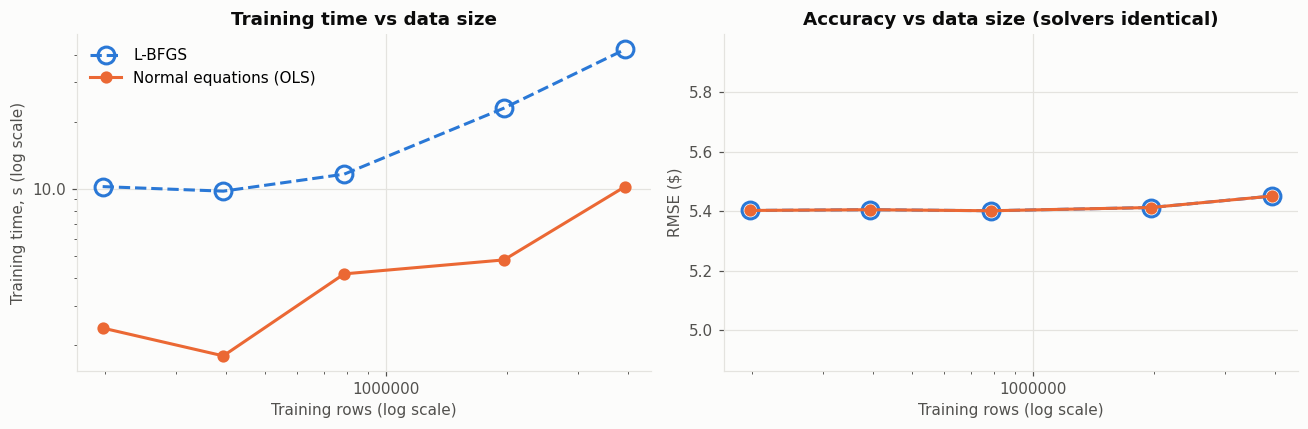

L-BFGS: training time grows ~ rows^0.49  (1.0 = linear scaling)
Normal equations (OLS): training time grows ~ rows^0.51  (1.0 = linear scaling)
Note: Spark here runs on one machine (local[*], 2 cores). On a cluster the same code distributes across nodes; the slope shows how cost grows with data, not cluster speed-up.


In [34]:
# Scalability: how training time grows with data size, for both solvers
FRACS = [float(x) for x in os.environ.get("TAXI_SCALE_FRACS", "0.005,0.01,0.02,0.05,0.10").split(",")]
base = (spark.read.parquet(*year_files(FARE_YEAR))
        .select(F.col("fare_amount").cast("double").alias("fare"), F.col("trip_distance").cast("double").alias("dist"),
                F.col("pickup_hour").cast("int").cast("string").alias("hour_s"),
                F.dayofweek(F.col("pickup_date").cast("date")).cast("string").alias("dow_s"),
                F.col("pulocationid").cast("string").alias("pu"), F.col("dolocationid").cast("string").alias("do"),
                F.col("ratecodeid").cast("int").cast("string").alias("rate"), F.col("is_zero_fare"))
        .where(~F.col("is_zero_fare") & (F.col("dist") > 0)).fillna({"rate": "unknown"}))
feat_pipe = Pipeline(stages=pre_stages + [VectorAssembler(inputCols=["dist"] + [c + "_oh" for c in cats], outputCol="features")])
scale = []
for frac in FRACS:
    sdf = base.sample(fraction=frac, seed=11)
    fp = feat_pipe.fit(sdf)
    X = fp.transform(sdf).select("fare", "features").cache()
    n = X.count()                                         # materialise before timing
    for solver in ["normal", "l-bfgs"]:
        lr = LinearRegression(labelCol="fare", featuresCol="features", solver=solver, maxIter=100)
        t0 = time.time(); m = lr.fit(X); ft = time.time() - t0
        scale.append({"Fraction": frac, "Rows": n, "Solver": "Normal equations (OLS)" if solver == "normal" else "L-BFGS",
                      "Train time (s)": ft, "RMSE ($)": m.summary.rootMeanSquaredError})
    X.unpersist()
    print(f"  {frac:.1%} sample: {n:,} rows done")
sc = pd.DataFrame(scale)
display(sc.pivot_table(index="Rows", columns="Solver", values=["Train time (s)", "RMSE ($)"]).round(3))
sc.round(4).to_csv(f"{TAB_DIR}/spark_scalability.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
from matplotlib.ticker import ScalarFormatter, NullFormatter
for i, (solver, g) in enumerate(sc.groupby("Solver")):
    col = [PAL["blue"], PAL["orange"]][i]
    style = dict(color=col, lw=2, ms=11 if i == 0 else 6, mfc="none" if i == 0 else col, mew=2, ls="--" if i == 0 else "-")
    axes[0].plot(g.Rows, g["Train time (s)"], "o", label=solver, **style)
    axes[1].plot(g.Rows, g["RMSE ($)"], "o", label=solver, **style)
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("Training rows (log scale)")
    ax.xaxis.set_major_formatter(ScalarFormatter()); ax.xaxis.set_minor_formatter(NullFormatter())
    ax.ticklabel_format(axis="x", style="plain")
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(ScalarFormatter()); axes[0].yaxis.set_minor_formatter(NullFormatter())
axes[0].set_ylabel("Training time, s (log scale)"); axes[0].set_title("Training time vs data size")
lo_, hi_ = sc["RMSE ($)"].min(), sc["RMSE ($)"].max()
axes[1].set_ylim(lo_ * 0.9, hi_ * 1.1)
axes[1].set_ylabel("RMSE ($)"); axes[1].set_title("Accuracy vs data size (solvers identical)")
axes[0].legend(loc="upper left"); plt.tight_layout(); plt.show()

for solver, g in sc.groupby("Solver"):
    slope = np.polyfit(np.log(g.Rows), np.log(g["Train time (s)"]), 1)[0]
    print(f"{solver}: training time grows ~ rows^{slope:.2f}  (1.0 = linear scaling)")
print(f"Note: Spark here runs on one machine (local[*], {os.cpu_count()} cores). On a cluster the same code distributes "
      "across nodes; the slope shows how cost grows with data, not cluster speed-up.")
spark.stop()

### Final results table (including Section 6)

In [35]:
res = pd.DataFrame(RESULTS)
res["value"] = res.value.astype(float)
display(res.round(3))
res.to_csv(f"{CACHE_DIR}/results_summary.csv", index=False)
print("Saved", f"{CACHE_DIR}/results_summary.csv")

,objective,estimate,value,ci_low,ci_high,p,note
0,R,OLS (7): Precipitation (cm) effect on trips (%),0.188,-0.499,0.880,0.592,
1,R,OLS (7): Snowfall (cm) effect on trips (%),-2.617,-4.785,-0.398,0.021,
2,R,OLS (7): Snow depth (cm) effect on trips (%),-0.949,-1.638,-0.256,0.007,
3,R,OLS (7): Public holiday effect on trips (%),-18.372,-23.401,-13.011,0.000,
4,1,"Speed, charging zone vs control (%)",-1.031,-2.205,0.157,0.089,pre-trend -3.82 lp/yr (p=1.9e-24); placebo -5.1%
5,1,"Pickups, charging zone vs control (%)",-1.071,-2.921,0.814,0.264,pre-trend 3.24 lp/yr (p=4.7e-08); placebo 1.9%
6,1,"Speed, buffer vs control (%)",-2.300,-3.330,-1.259,0.000,pre-trend -2.06 lp/yr (p=2.9e-07); placebo -3.0%
7,1,"Pickups, buffer vs control (%)",-7.500,-8.686,-6.299,0.000,pre-trend 0.07 lp/yr (p=0.85); placebo -2.1%
8,1,"Speed, charging zone, pre-period 2022–24 (%)",-1.031,-2.205,0.157,0.089,pre-trend -3.82 pp/yr (p=1.9e-24); placebo -5....
9,1,"Pickups, charging zone, pre-period 2022–24 (%)",-1.071,-2.921,0.814,0.264,pre-trend 3.24 pp/yr (p=4.7e-08); placebo 1.9%...


Saved /content/drive/MyDrive/BigData Project/panels/results_summary.csv
